<a href="https://colab.research.google.com/github/NathaliaVega01/TrabajoIntegrador-MercadoMotocicletasColombia/blob/main/TrabajoIntegrador_ModeloMercadoMotocicletas_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Modelación y pronóstico del mercado de motocicletas en Colombia con base en variables macroeconómicas**

Nathalia Vega Aguirre

##Entendimiento del Problema



El mercado de motocicletas en Colombia es dinámico y sensible a variables macroeconómicas (PIB, inflación, tasa de cambio) según la ANDI. Históricamente, la proyección de la demanda total para la planeación de ventas de empresas líderes se ha apoyado en modelos predictivos más simples como promedio móvil y en la experiencia de expertos de negocio.

La situación problemática actual surge de un desajuste entre la complejidad del entorno y las herramientas utilizadas. El mercado exige una capacidad de pronóstico que capture interacciones complejas, estacionalidades y la no linealidad introducida por múltiples variables económicas. Si bien los modelos tradicionales proveen interpretabilidad y sirven como punto de partida, presentan limitaciones en su desempeño predictivo en escenarios volátiles, lo que impide alcanzar la precisión necesaria para una óptima gestión operativa. Esta dependencia de modelos que no alcanzan la rigurosidad requerida para el contexto económico actual genera una imprecisión persistente en el pronóstico del volumen de mercado que se materializa en dificultades en la planeación y gestión de la cadena de suministro.

El reto principal del proyecto radica en disminuir el error predictivo (imprecisión) en la estimación de la demanda total del mercado de motocicletas mediante la integración y comparación formal de metodologías de modelación. Un desafío metodológico significativo reside en la selección y el tratamiento de las variables predictoras. Esto se debe a que dichas variables macroeconómicas deben ser proyectadas a futuro, lo que implica construir un modelo predictivo basado en variables rezagadas.

El proyecto aborda la raíz del problema de negocio, que es la limitación analítica de los métodos actuales. Al resolver este reto técnico, se busca proveer la información necesaria para mitigar ineficiencias operativas y financieras que puede experimentar la compañía por una estimación imprecisa del mercado.


##Entendimiento de los Datos



Para predecir el mercado de motocicletas con base en variables macroeconómicas es necesario la construcción del conjunto de datos que integre las series temporales de dichas variables con la cantidad de registros de motocicletas nuevas en el RUNT. En este caso, el horizonte temporal de análisis comprende desde enero de 2005 hasta julio de 2026, lo que permite observar el comportamiento del mercado a lo largo de distintos ciclos económicos, incluyendo la crisis financiera internacional de 2008-2009, la devaluación del peso a partir de 2015, la pandemia del COVID-19 y el ciclo inflacionario y de tasas de interés de 2022-2023.

Dada la naturaleza y la frecuencia de reporte de las variables macroeconómicas, se elaboraron dos conjuntos de datos: uno con temporalidad mensual y otro trimestral. En este último, la variable objetivo se agrega como la suma de los registros de los tres meses de cada trimestre.


**Dataset Mensual:** las variables que lo componen son las siguientes:


***Tabla. Variables mensuales***

| Variable | Fuente |
| :--- | :--- |
| Registros (unidades de motocicletas) | Fuente propia (Base paga del RUNT) |
| Población Total (en miles) | DANE |
| Población Ocupada (en miles) | DANE |
| Población Desocupada (en miles) | DANE |
| Tasa de Ocupación | DANE |
| Tasa de Desocupación | DANE |
| Tasa de cambio (TRM) | Banco de la República |
| Var. TRM | Calculado |
| Tasa de interés de política monetaria | Banco de la República |
| DTF | Banco de la República |
| Inflación mensual | Banco de la República |
| Inflación Interanual | Banco de la República |
| Días Hábiles | Calculado |
| SMMLV (COP) | Banco de la República |
| Índice de Confianza del Consumidor | Fundación para la Educación Superior y el Desarrollo (Fedesarrollo) |
| Índice de de Expectativas del Consumidor | Fundación para la Educación Superior y el Desarrollo (Fedesarrollo) |
| Índice de Condiciones Económicas | Fundación para la Educación Superior y el Desarrollo (Fedesarrollo) |


El dataset mensual tiene 259 observaciones desde enero del 2005 a julio del 2026.


**Dataset Trimestral:** las variables que se reportan únicamente trimestralmente son las siguientes:


***Tabla. Variables trimestrales***
| Variable | Fuente | Observaciones |
| :--- | :--- | :--- |
| PIB (MMCOP) | Banco de la República | Base 2015 - Constante - Desestacionalizado (MM COP) |
| Exportaciones (MMCOP) | Banco de la República | Base 2015 - Constante - Desestacionalizado (MM COP) |
| Importaciones (MMCOP) | Banco de la República | Base 2015 - Constante - Desestacionalizado (MM COP) |
| Remesas (millones de USD) | Banco de la República | |
| PIB per cápita | Calculado | Calculado como PIB Total / Población Total |


El dataset trimestral tiene 86 observaciones desde el primer trimestre del 2005 al segundo semestre del 2026.



In [15]:
#Se importan las librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
import math
from statsmodels.tsa.seasonal import seasonal_decompose

In [4]:
#Se cargan los datasets

#Dataset Trimestral
df_datamarket_trim = pd.read_excel("Data - Mercado.xlsx", sheet_name="DataTrimestral")

#Dataset Mensual
df_datamarket_men = pd.read_excel("Data - Mercado.xlsx", sheet_name="DataMensual")

In [5]:
#Validación de la carga de los datasets

df_datamarket_trim.head()

,Periodo,FechaInicio,FechaFin,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,PIB,...,DTF,InflacionAnual,InflacionTrimestral,DiasHabiles,Remesas,PIB_PC,SMMLV,ICC,IEC,ICE
0,2005 - Trim 1,2005-01-01,2005-03-01,37999,40356.925000,16083.864000,2497.111000,0.569730,0.134391,126088.657004,...,0.074733,0.0503,0.026326,72,731.13,312.433757,426000,0.142667,0.194333,0.065333
1,2005 - Trim 2,2005-04-01,2005-06-01,46544,40472.751667,16344.090000,2233.020667,0.576303,0.120203,128906.474678,...,0.072167,0.0483,0.012552,75,803.26,318.501879,426000,0.153667,0.175667,0.120000
2,2005 - Trim 3,2005-07-01,2005-09-01,62445,40590.071000,16573.203667,2196.234667,0.581704,0.117011,128717.054381,...,0.069767,0.0502,0.004802,76,851.47,317.114632,426000,0.229333,0.273667,0.162333
3,2005 - Trim 4,2005-10-01,2005-12-01,65080,40711.004667,17130.671000,1935.233000,0.598455,0.101502,131260.139968,...,0.063900,0.0485,0.004105,75,927.86,322.419309,426000,0.200333,0.224000,0.164000
4,2006 - Trim 1,2006-01-01,2006-03-01,86446,40831.239333,16551.336333,2386.386667,0.575535,0.126012,134044.350100,...,0.060400,0.0411,0.019120,75,855.89,328.288713,455700,0.272667,0.306667,0.222000


In [6]:
#Validación de la carga de los datasets

df_datamarket_men.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,DTF,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,IEC,ICE
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,0.0767,0.0543,0.0082,24,426000,0.193,0.266,0.083
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,0.0741,0.0525,0.0102,24,426000,0.139,0.189,0.065
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,0.0734,0.0503,0.0077,24,426000,0.096,0.128,0.048
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,0.0729,0.0501,0.0044,26,426000,0.133,0.169,0.080
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,0.0718,0.0504,0.0041,24,426000,0.141,0.147,0.130


In [7]:
#Validación de la calidad y tipo de datos

df_datamarket_trim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86 entries, 0 to 85
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Periodo              86 non-null     object        
 1   FechaInicio          86 non-null     datetime64[ns]
 2   FechaFin             86 non-null     datetime64[ns]
 3   Registros            86 non-null     int64         
 4   PoblacionTotal       86 non-null     float64       
 5   PoblacionOcupada     86 non-null     float64       
 6   PoblacionDesocupada  86 non-null     float64       
 7   TasaOcupacion        86 non-null     float64       
 8   TasaDesocupacion     86 non-null     float64       
 9   PIB                  86 non-null     float64       
 10  Var.PIB              85 non-null     float64       
 11  Exportaciones        86 non-null     float64       
 12  Importaciones        86 non-null     float64       
 13  TRM                  86 non-null     

In [8]:
#Validación de la calidad y tipo de datos

df_datamarket_men.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 259 entries, 0 to 258
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Fecha                259 non-null    datetime64[ns]
 1   Registros            259 non-null    int64         
 2   PoblacionTotal       259 non-null    float64       
 3   PoblacionOcupada     259 non-null    float64       
 4   PoblacionDesocupada  259 non-null    float64       
 5   TasaOcupacion        259 non-null    float64       
 6   TasaDesocupacion     259 non-null    float64       
 7   TRM                  259 non-null    float64       
 8   Var.TRM              258 non-null    float64       
 9   TasaInteres          259 non-null    float64       
 10  DTF                  259 non-null    float64       
 11  InflacionAnual       259 non-null    float64       
 12  InflacionMensual     259 non-null    float64       
 13  DiasHabiles          259 non-null  

In [9]:
#Métricas estadísticas generales

df_datamarket_trim.describe()

,FechaInicio,FechaFin,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,PIB,Var.PIB,...,DTF,InflacionAnual,InflacionTrimestral,DiasHabiles,Remesas,PIB_PC,SMMLV,ICC,IEC,ICE
count,86,86,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,85.000000,...,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,8.600000e+01,86.000000,86.000000,86.000000
mean,2015-08-16 15:20:55.813953536,2015-10-16 10:19:32.093023232,147814.290698,46050.282643,20057.032176,2459.795443,0.582132,0.109970,195860.249919,0.008961,...,0.063464,0.049278,0.012294,74.046512,1596.101628,421.482222,8.463711e+05,0.053163,0.099310,-0.016140
min,2005-01-01 00:00:00,2005-03-01 00:00:00,37999.000000,40356.925000,16018.596000,1896.889333,0.445454,0.077353,126088.657004,-0.161649,...,0.018300,0.015100,-0.005399,71.000000,731.130000,312.433757,4.260000e+05,-0.361333,-0.221667,-0.666667
25%,2010-04-23 18:00:00,2010-06-24 00:00:00,110789.250000,42852.866417,18501.452000,2162.569667,0.568585,0.095849,159262.015271,0.003524,...,0.043667,0.032000,0.004829,73.000000,1012.065000,371.378539,5.765000e+05,-0.097583,-0.050250,-0.173500
50%,2015-08-16 00:00:00,2015-10-16 12:00:00,144852.000000,45463.270000,20440.724000,2389.613803,0.583342,0.108060,200982.445123,0.008429,...,0.054233,0.044500,0.010534,74.000000,1280.355000,437.484155,7.183500e+05,0.057167,0.105833,-0.004833
75%,2020-12-09 00:00:00,2021-02-06 12:00:00,168117.000000,49670.540083,21423.044667,2581.138750,0.601005,0.118152,221924.415912,0.014502,...,0.087033,0.058025,0.016639,75.000000,1941.225000,456.382773,1.006399e+06,0.226750,0.245000,0.165750
max,2026-04-01 00:00:00,2026-06-01 00:00:00,332084.000000,52505.805000,24439.674599,4446.712000,0.628518,0.209399,262061.541560,0.098772,...,0.138700,0.133400,0.045560,77.000000,3354.000000,499.109654,2.000000e+06,0.345333,0.425667,0.368667
std,NaN,NaN,57452.787958,3755.446772,2272.149409,456.913499,0.029608,0.020973,38848.960867,0.024685,...,0.028272,0.025981,0.010360,1.396693,746.823424,52.396239,3.691941e+05,0.184324,0.161864,0.238429


In [10]:
#Métricas estadísticas generales

df_datamarket_men.describe()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,DTF,InflacionAnual,InflacionMensual,DiasHabiles,SMMLV,ICC,IEC,ICE
count,259,259.000000,259.000000,259.000000,259.000000,259.000000,259.000000,259.000000,258.000000,259.000000,259.000000,259.000000,259.000000,259.000000,2.590000e+02,259.000000,259.000000,259.000000
mean,2015-10-01 08:48:11.119691008,49591.223938,46075.511853,20074.367501,2458.656754,0.582181,0.109875,2850.731004,0.001809,0.062674,0.063613,0.049357,0.004062,24.675676,8.508252e+05,0.053757,0.100097,-0.015830
min,2005-01-01 00:00:00,202.000000,40318.940000,15572.558000,1763.467000,0.424971,0.070249,1712.280000,-0.071816,0.017500,0.017600,0.014900,-0.003800,22.000000,4.260000e+05,-0.413000,-0.283000,-0.730000
25%,2010-05-16 12:00:00,37747.500000,42844.232500,18363.613000,2142.199131,0.568686,0.094752,1979.395000,-0.016732,0.041250,0.044050,0.031750,0.001350,24.000000,5.765000e+05,-0.105000,-0.048000,-0.172000
50%,2015-10-01 00:00:00,47251.000000,45482.981000,20384.009000,2349.787000,0.585916,0.107484,2860.000000,-0.002518,0.052500,0.054500,0.044200,0.003200,25.000000,7.183500e+05,0.067000,0.112000,0.007000
75%,2021-02-15 00:00:00,56877.500000,49739.386000,21535.027000,2632.811500,0.601032,0.119876,3693.000000,0.018021,0.092500,0.086650,0.058650,0.006050,25.000000,1.014980e+06,0.221000,0.252000,0.176000
max,2026-07-01 00:00:00,132098.000000,52584.648000,24598.644740,4695.063000,0.640080,0.219720,4922.300000,0.135486,0.132500,0.143900,0.133400,0.017800,27.000000,2.000000e+06,0.388000,0.488000,0.408000
std,NaN,20168.983131,3755.770311,2289.872066,473.955877,0.030279,0.021839,887.069221,0.033475,0.030890,0.028307,0.025801,0.003844,0.970009,3.739757e+05,0.187433,0.167623,0.240276


###Análisis Exploratorio de Datos

Con el fin de tener una mejor comprensión de cada una de las variables de manera independiente y, posteriormente, su relación con el mercado, el análisis exploratorio de datos se llevó a cabo en tres etapas: la variable objetivo, las variables predictoras, mensuales y trimestrales, y la relación entre la variable objetivo y las predictoras, incluyendo el análisis de rezagos.

####Variable Objetivo: Registros (Unidades de Motocicletas - Mercado)

La variable objetivo corresponde al número mensual de motocicletas nuevas registradas en el RUNT. Su análisis busca identificar la tendencia de largo plazo, los patrones estacionales y los eventos atípicos que deberán ser considerados en la fase de modelación.


In [11]:
objetivo = df_datamarket_men[["Fecha", "Registros"]].copy()

# Resumen de calidad
print("Total de observaciones:", len(objetivo))
print("Valores faltantes:", objetivo["Registros"].isna().sum())
print("Valores iguales a cero:", (objetivo["Registros"] == 0).sum())
print("Valores negativos:", (objetivo["Registros"] < 0).sum())

# Identificar posibles meses faltantes
calendario = pd.date_range(
    start=objetivo["Fecha"].min().to_period("M").to_timestamp(),
    end=objetivo["Fecha"].max().to_period("M").to_timestamp(),
    freq="MS"
)

fechas_observadas = pd.DatetimeIndex(
    objetivo["Fecha"].dt.to_period("M").drop_duplicates()
                       .dt.to_timestamp()
)

meses_faltantes = calendario.difference(fechas_observadas)

Total de observaciones: 259
Valores faltantes: 0
Valores iguales a cero: 0
Valores negativos: 0


In [12]:
estadisticos = objetivo["Registros"].describe().to_frame().T

estadisticos["mediana"] = objetivo["Registros"].median()
estadisticos["asimetria"] = objetivo["Registros"].skew()
estadisticos["curtosis"] = objetivo["Registros"].kurtosis()
estadisticos["coef_variacion_pct"] = (
    objetivo["Registros"].std()
    / objetivo["Registros"].mean()
) * 100

display(estadisticos.round(2))

,count,mean,std,min,25%,50%,75%,max,mediana,asimetria,curtosis,coef_variacion_pct
Registros,259.0,49591.22,20168.98,202.0,37747.5,47251.0,56877.5,132098.0,47251.0,1.09,2.44,40.67


La gráfica evidencia una serie con tendencia creciente de largo plazo, pero no lineal, en la que se distinguen varias etapas. Entre 2005 y 2008 el mercado pasa de cerca de 12 mil a alrededor de 40 mil registros mensuales; en 2009 se observa una contracción asociada a la desaceleración económica. Además, con una caída puntual en el mes de noviembre cercana a 5 mil unidades, debido a la implementación obligatoria del RUNT que presentó fallas en el sistema e impidió el registro de las motocicletas. Entre 2010 y 2015 el mercado se expande de forma sostenida hasta niveles de 55 a 60 mil unidades, para luego contraerse entre 2016 y 2017 y estabilizarse alrededor de 45 a 50 mil unidades hasta 2019. En abril de 2020 la serie cae como consecuencia de las medidas de confinamiento por el COVID-19, seguida de una rápida recuperación en 2021-2022. Finalmente, tras un leve retroceso en 2023 debido a la problemática para expedición de SOAT, a partir de 2024 se presenta una aceleración pronunciada que lleva el mercado a superar los 130 mil registros en un solo mes en 2026. Este comportamiento indica que la serie no es estacionaria.

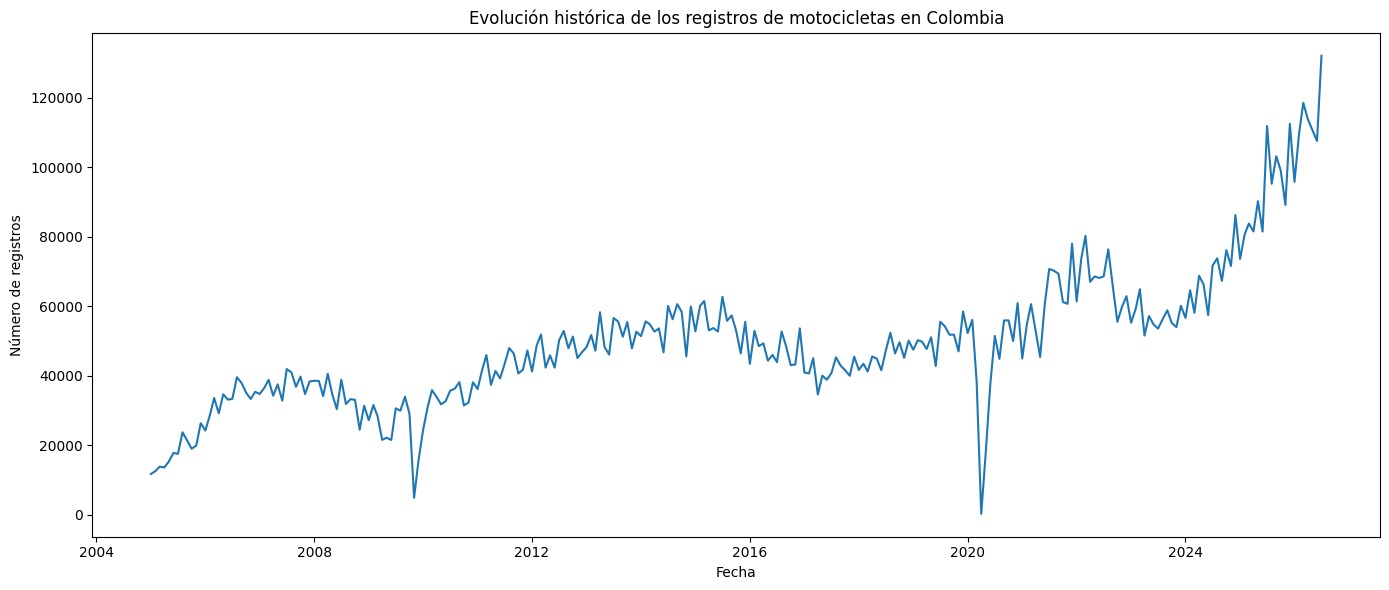

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    objetivo["Fecha"],
    objetivo["Registros"],
    linewidth=1.5
)

plt.title("Evolución histórica de los registros de motocicletas en Colombia")
plt.xlabel("Fecha")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

La gráfica resume la distribución mensual de los registros dentro de cada año. La mediana anual confirma los ciclos descritos: crecimiento hasta 2007, retroceso en 2009, expansión entre 2011 y 2015, contracción en 2016-2017 y un nuevo ciclo expansivo desde 2021. Se destaca la alta dispersión de 2020, cuyo rango va desde valores cercanos a cero hasta niveles similares a los de 2019, reflejando el decrecimiento y la posterior recuperación dentro del mismo año. De igual forma, 2025 presenta una caja amplia que evidencia un crecimiento acelerado mes a mes, y 2026 se ubica en un nivel superior, con una mediana cercana a 110 mil unidades.

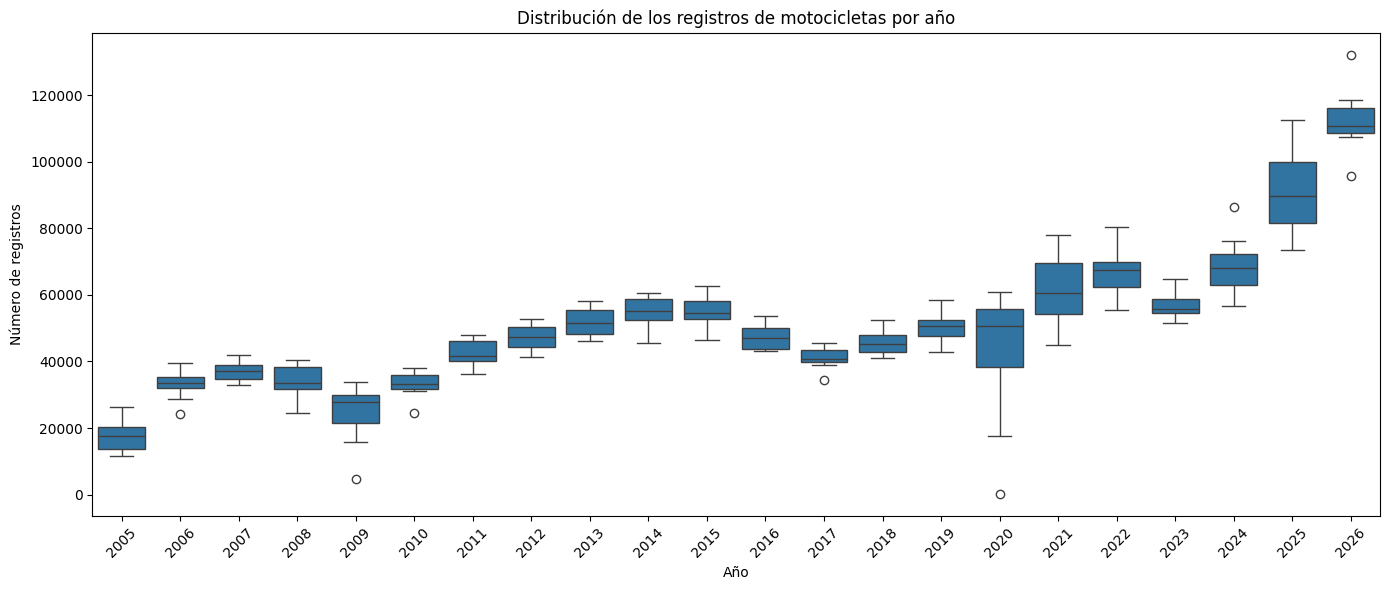

In [14]:
# Extraer el año de la fecha
objetivo["Año"] = objetivo["Fecha"].dt.year

# Distribución de registros por año
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=objetivo,
    x="Año",
    y="Registros"
)

plt.title("Distribución de los registros de motocicletas por año")
plt.xlabel("Año")
plt.ylabel("Número de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

La gráfica muestra un patrón estacional intra-anual consistente. Julio es el mes con mayor promedio histórico (55.351 unidades), seguido de diciembre (53.101) y agosto (51.980); mientras que noviembre (44.573) y enero (45.612) registran los promedios más bajos. Los picos de julio y diciembre podrían estar asociados al pago de las primas de servicios a mitad y final de año, que incrementa la capacidad de compra de los hogares, mientras que la caída de enero coincide con el cierre de temporada y vacaciones. Asimismo, abril también presenta bajos registros en promedio (46.768) debido a vacaciones de semana santa. Es importante tener en cuenta que los meses de enero a julio incluyen las observaciones de 2026, año de niveles récord, lo cual eleva ligeramente su promedio frente a los meses de agosto a diciembre.

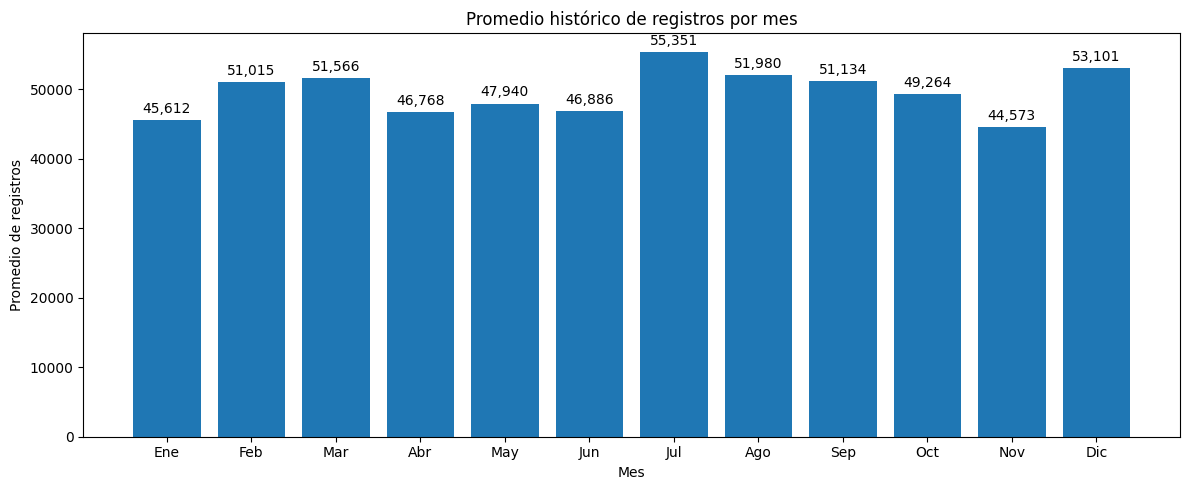

In [18]:
objetivo["Mes"] = objetivo["Fecha"].dt.month

nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

promedio_mensual = (
    objetivo.groupby("Mes")["Registros"]
    .mean()
    .reindex(range(1, 13))
)

plt.figure(figsize=(12, 5))

barras = plt.bar(nombres_meses, promedio_mensual.values)

# Mostrar etiquetas en cada barra
plt.bar_label(
    barras,
    labels=[f"{valor:,.0f}" for valor in promedio_mensual.values],
    padding=3
)

plt.title("Promedio histórico de registros por mes")
plt.xlabel("Mes")
plt.ylabel("Promedio de registros")
plt.tight_layout()
plt.show()

La gráfica complementa el análisis anterior mostrando la variabilidad de los registros en cada mes calendario. Las medianas mensuales presentan poca variación y se mantienen dentro de un intervalo comprendido entre 43 y 53 mil unidades. No obstante, la amplitud de las cajas evidencia una mayor dispersión de los registros entre años que entre meses, lo que indica que la variabilidad entre años (efecto tendencia) es mayor que la variabilidad entre meses (efecto estacional). Los valores atípicos superiores, presentes en todos los meses, corresponden a los años 2025 y 2026, mientras que los atípicos inferiores se concentran en enero (inicio de la serie en 2005), abril (confinamiento de 2020) y noviembre (caída puntual de 2009).

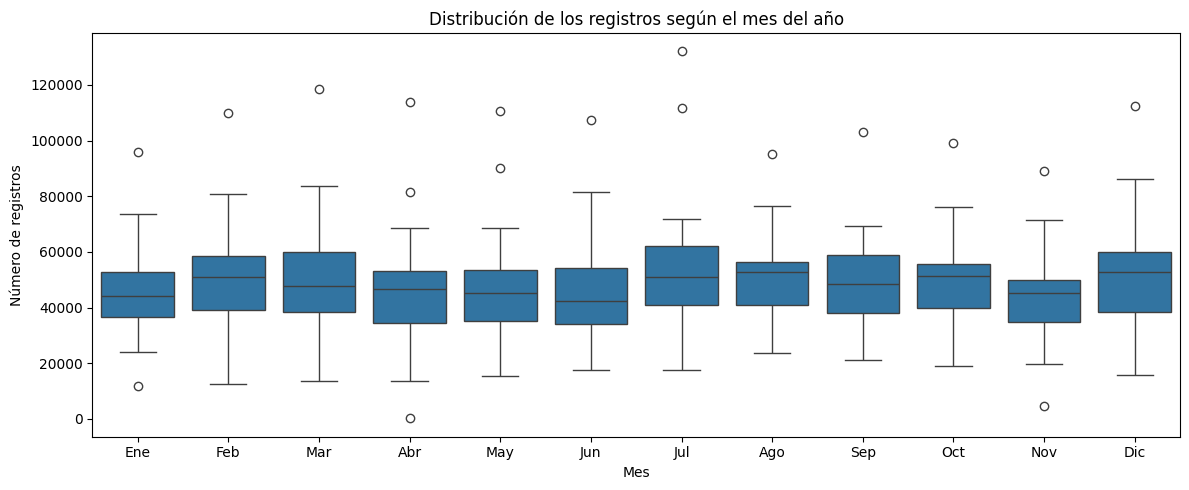

In [20]:

# Distribución de registros por mes calendario
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=objetivo,
    x="Mes",
    y="Registros"
)

plt.xticks(range(12), nombres_meses)
plt.title("Distribución de los registros según el mes del año")
plt.xlabel("Mes")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

In [21]:
#Posibles Valores Atípicos

serie = objetivo["Registros"].dropna()

q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = objetivo[
    (objetivo["Registros"] < limite_inferior) |
    (objetivo["Registros"] > limite_superior)
]

display(atipicos[["Fecha", "Registros"]])

print("Cantidad de posibles valores atípicos:", len(atipicos))

,Fecha,Registros
58,2009-11-01,4813
183,2020-04-01,202
239,2024-12-01,86239
244,2025-05-01,90212
246,2025-07-01,111861
247,2025-08-01,95242
248,2025-09-01,103166
249,2025-10-01,98990
250,2025-11-01,89130
251,2025-12-01,112509


Cantidad de posibles valores atípicos: 17


La descomposición de la serie separa sus componentes de tendencia, estacionalidad y residuo. La tendencia reproduce los ciclos del mercado y evidencia la fuerte pendiente positiva desde 2024. El componente estacional presenta un patrón regular y estable, con una amplitud aproximada de ±5.000 unidades, esto evidencia un patrón cíclico que se repite de manera regular a lo largo del período analizado, lo que confirma la presencia de estacionalidad anual en los registros de motocicletas. Las oscilaciones alrededor de cero reflejan el efecto sistemático de cada mes sobre el comportamiento de la serie, indicando períodos en los que los registros tienden a situarse por encima o por debajo de la tendencia. Asimismo, la magnitud relativamente constante de estas fluctuaciones sugiere que el efecto estacional se mantiene estable en el tiempo. El residuo se mantiene cercano a cero en la mayor parte del periodo, con excepción de choques negativos marcados en 2009 y 2020 y de una mayor dispersión a partir de 2020.

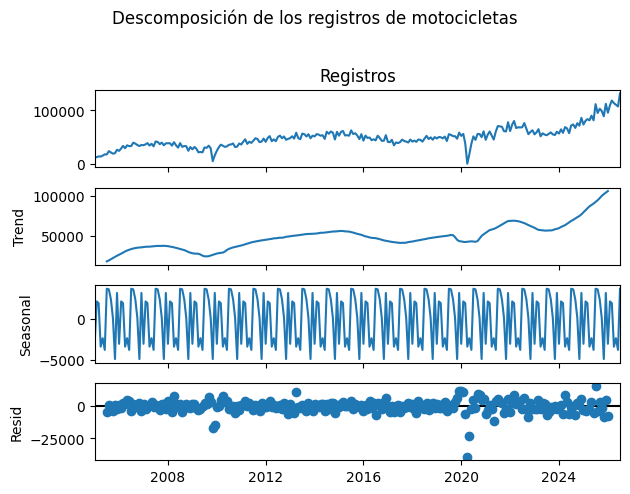

In [22]:
# La descomposición requiere una serie mensual regular y sin faltantes.
serie_mensual = (
    df_datamarket_men.set_index("Fecha")["Registros"]
      .groupby(lambda x: x.to_period("M"))
      .sum(min_count=1)
)

serie_mensual.index = serie_mensual.index.to_timestamp()

# Comprobar continuidad y valores faltantes antes de continuar
serie_mensual = serie_mensual.asfreq("MS")

if serie_mensual.isna().any():
    print("Hay meses faltantes. Investiga y resuelve esos faltantes antes de descomponer.")
elif len(serie_mensual) < 24:
    print("Se recomienda contar con al menos dos ciclos anuales completos.")
else:
    descomposicion = seasonal_decompose(
        serie_mensual,
        model="additive",
        period=12
    )

    descomposicion.plot()
    plt.suptitle("Descomposición de los registros de motocicletas", y=1.02)
    plt.tight_layout()
    plt.show()

####Variables Predictoras: Variables Macroeconómicas

#####Variables: Periodicidad Mensual

Las variables predictoras mensuales recogen información del mercado laboral, la tasa de cambio, las condiciones monetarias, la inflación, el ingreso mínimo, la percepción de los consumidores y el calendario. A continuación, se analiza su evolución histórica y su distribución.



In [23]:
#Calidad de la data

variables_predictoras = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Conservar únicamente las columnas que existan en la base
variables_predictoras = [
    col for col in variables_predictoras
    if col in df_datamarket_men.columns
]

predictores = df_datamarket_men[variables_predictoras].copy()

for col in variables_predictoras:
    predictores[col] = pd.to_numeric(
        predictores[col], errors="coerce"
    )

inventario = pd.DataFrame({
    "No_nulos": predictores.notna().sum(),
    "Faltantes": predictores.isna().sum(),
    "Porcentaje_faltantes": predictores.isna().mean() * 100,
    "Valores_unicos": predictores.nunique()
})

display(inventario.round(2))

,No_nulos,Faltantes,Porcentaje_faltantes,Valores_unicos
PoblacionTotal,259,0,0.00,259
PoblacionOcupada,259,0,0.00,259
PoblacionDesocupada,259,0,0.00,259
TasaOcupacion,259,0,0.00,259
TasaDesocupacion,259,0,0.00,257
TRM,259,0,0.00,257
Var.TRM,258,1,0.39,258
TasaInteres,259,0,0.00,43
DTF,259,0,0.00,213
InflacionAnual,259,0,0.00,218


In [24]:
#Métricas Estadísticas

display(predictores.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
PoblacionTotal,259.0,46075.512,3755.770,40318.940,42844.232,45482.981,49739.386,52584.648
PoblacionOcupada,259.0,20074.368,2289.872,15572.558,18363.613,20384.009,21535.027,24598.645
PoblacionDesocupada,259.0,2458.657,473.956,1763.467,2142.199,2349.787,2632.812,4695.063
TasaOcupacion,259.0,0.582,0.030,0.425,0.569,0.586,0.601,0.640
TasaDesocupacion,259.0,0.110,0.022,0.070,0.095,0.107,0.120,0.220
TRM,259.0,2850.731,887.069,1712.280,1979.395,2860.000,3693.000,4922.300
Var.TRM,258.0,0.002,0.033,-0.072,-0.017,-0.003,0.018,0.135
TasaInteres,259.0,0.063,0.031,0.018,0.041,0.052,0.092,0.132
DTF,259.0,0.064,0.028,0.018,0.044,0.054,0.087,0.144
InflacionAnual,259.0,0.049,0.026,0.015,0.032,0.044,0.059,0.133


La gráfica permite agrupar las variables mensuales según su comportamiento:

**•	Variables demográficas y laborales:** La población total crece de forma continua y casi lineal, con un salto alrededor de 2014 y una aceleración entre 2017 y 2020, debido al flujo migratorio de ese periodo. La población ocupada también presenta tendencia creciente con estacionalidad, una caída abrupta en 2020 y una recuperación que la lleva a máximos históricos. La población desocupada y la tasa de desocupación oscilan alrededor de niveles estables, registran un pico en 2020 (la tasa de desocupación supera el 20%) y descienden posteriormente hasta niveles cercanos al 8%, los más bajos del periodo. La tasa de ocupación muestra el comportamiento inverso.

**•	Tasa de cambio:** La TRM se mantiene entre 1.800 y 2.500 pesos hasta 2014, se devalúa fuertemente a partir de 2015, alcanza su máximo cercano a 4.900 pesos en 2022 y luego desciende. Su variación mensual (Var. TRM) oscila alrededor de cero sin tendencia, lo que sugiere un comportamiento estacionario.

**•	Variables monetarias e inflación:** La tasa de interés de política monetaria y la DTF presentan ciclos prácticamente idénticos, con máximos en 2008, 2016 y 2023 y mínimos históricos en 2020-2021. La inflación anual sigue un ciclo similar, con picos en 2008, 2016 y cerca del 13% en 2023, lo cual evidencia la reacción de la política monetaria frente a la inflación. La inflación mensual es más volátil y no muestra tendencia.

**•	Salario mínimo y días hábiles:** El SMMLV crece de forma escalonada, con incrementos una vez al año, y se acelera en los últimos años. Los días hábiles oscilan entre 22 y 27 sin tendencia, por ser una variable puramente de calendario.

**•	Índices de confianza:** ICC, IEC e ICE se mueven de forma casi paralela: niveles altos entre 2005 y 2014, deterioro desde 2015, mínimos en 2020, nuevo deterioro en 2022-2023 y recuperación en 2025-2026. Este movimiento conjunto anticipa una alta correlación entre ellos.

En conjunto, varias de las predictoras (población, población ocupada, TRM y SMMLV) comparten con los registros una tendencia creciente, mientras que otras son cíclicas o estacionarias. Esta diferencia es relevante, ya que la correlación entre series con tendencia puede ser en parte espuria.



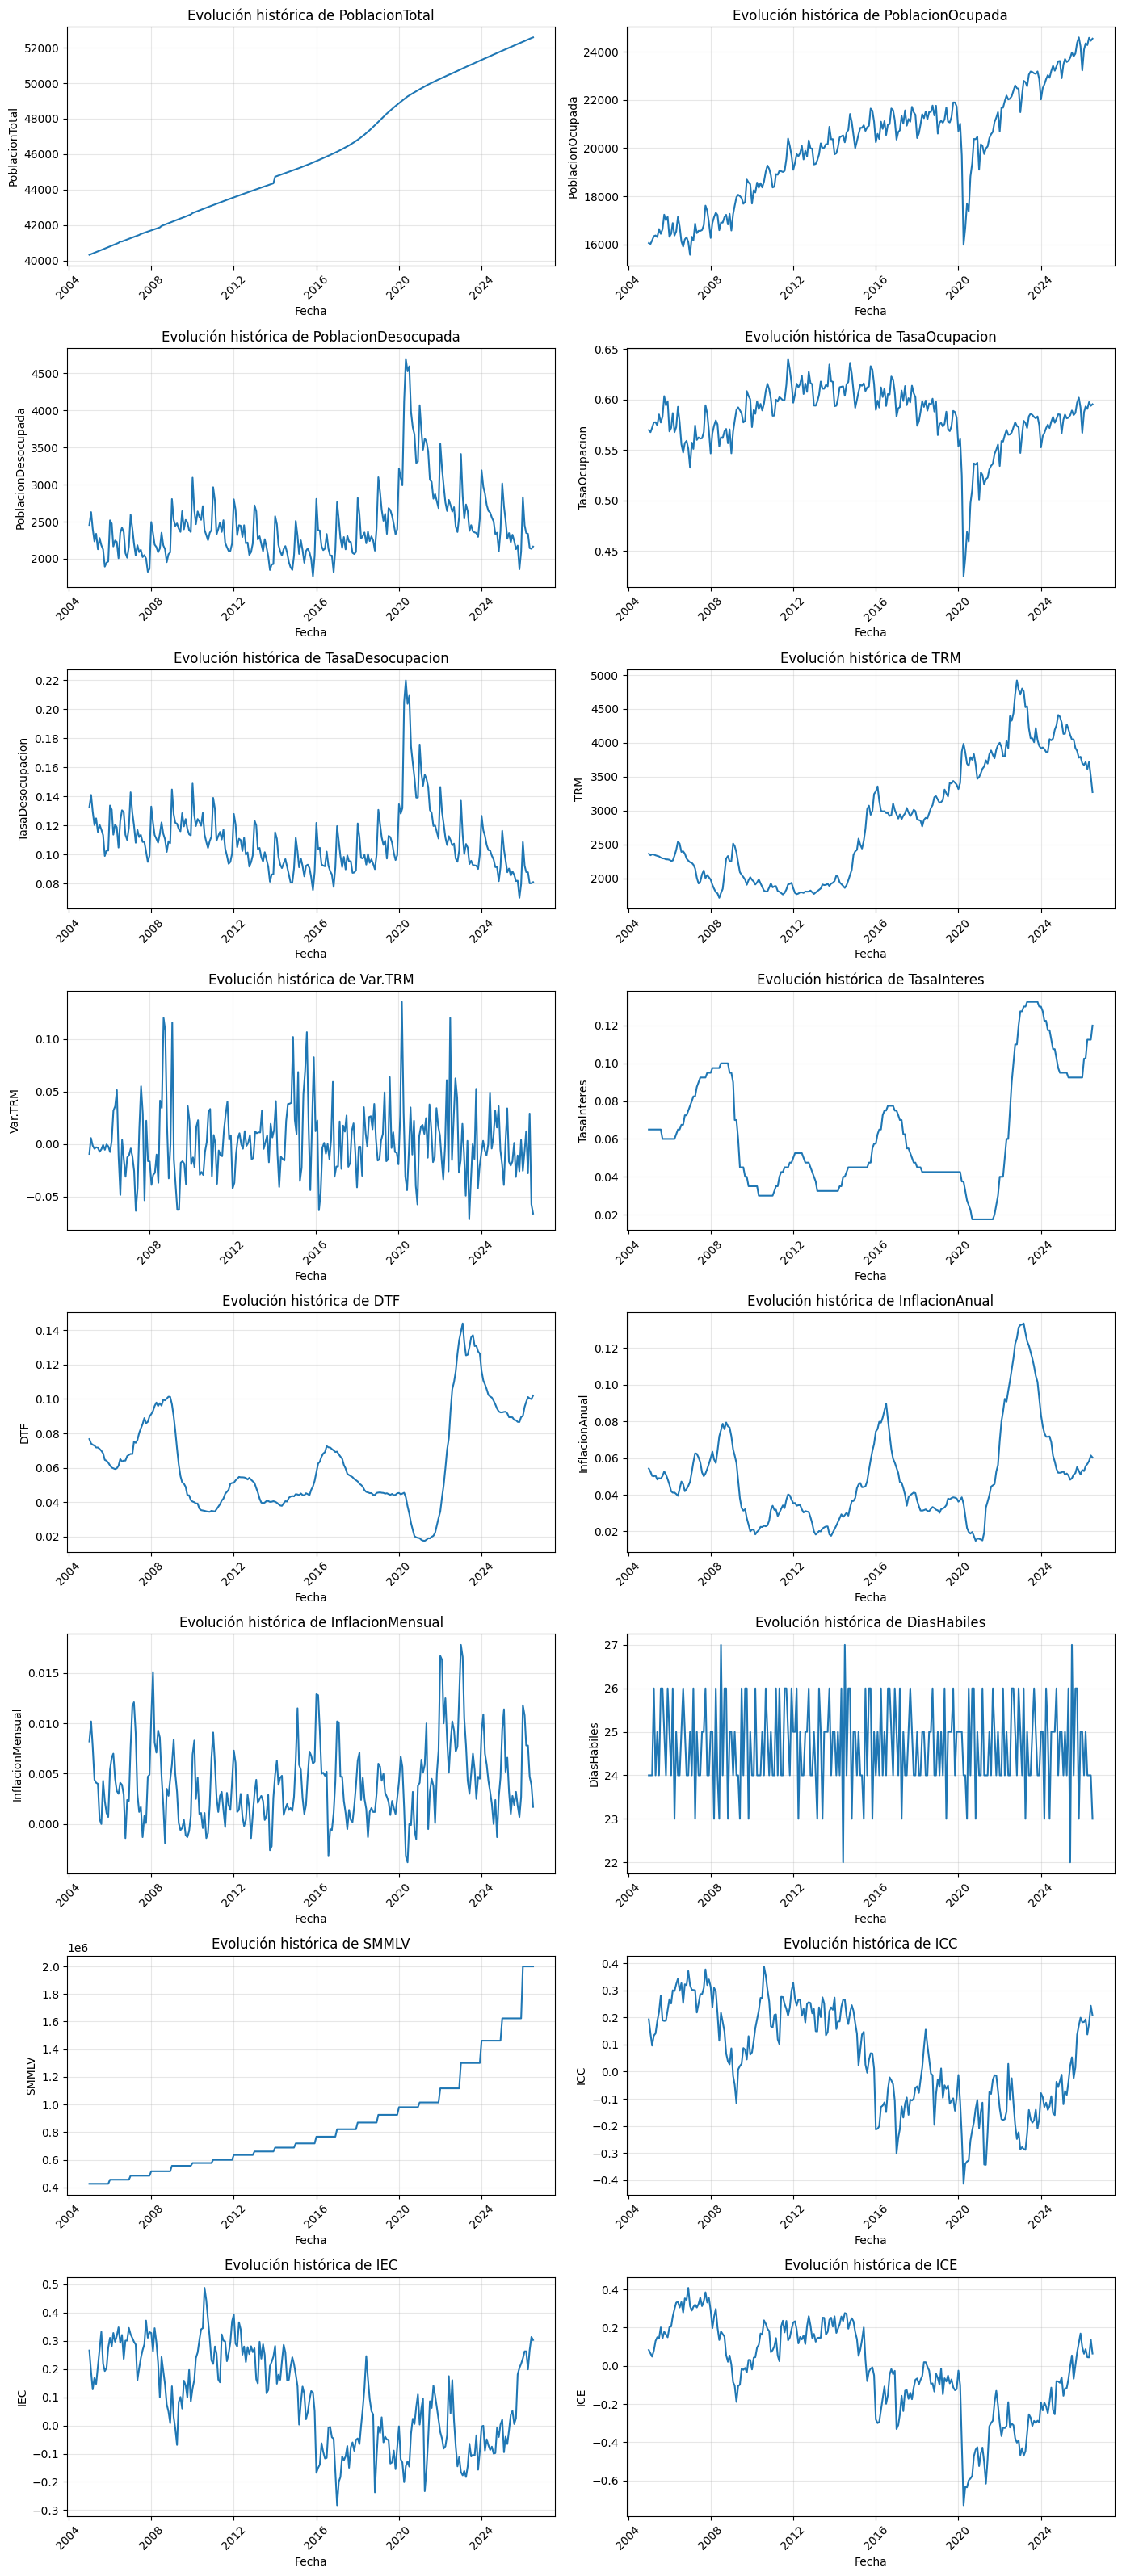

In [25]:
n_variables = len(variables_predictoras)

ncols = 2
nrows = math.ceil(n_variables / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 4 * nrows)
)

# Convertir los ejes en una lista, incluso si hay una sola fila
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(variables_predictoras):

    datos = (
        df_datamarket_men[["Fecha", col]]
        .dropna()
        .sort_values("Fecha")
    )

    ax = axes[i]

    if datos.empty:
        ax.set_visible(False)
        continue

    ax.plot(datos["Fecha"], datos[col], linewidth=1.5)

    ax.set_title(f"Evolución histórica de {col}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

# Ocultar espacios sobrantes en la cuadrícula
for j in range(n_variables, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

La siguiente gráfica presenta el histograma y el diagrama de caja de cada variable mensual. Se identifican tres tipos de comportamiento:

**•	Distribuciones multimodales o aplanadas: **(población total, población ocupada, TRM, tasa de interés, DTF, ICC e IEC), que reflejan los distintos regímenes o niveles que ha tenido la variable en el tiempo más que una dispersión aleatoria. No presentan valores atípicos.

**•	Distribuciones con asimetría positiva y valores atípicos superiores:** (población desocupada, tasa de desocupación, inflación anual, inflación mensual, SMMLV y Var.TRM). Los atípicos se concentran en episodios específicos: la pandemia de 2020 para el desempleo, el ciclo inflacionario de 2022-2023 para la inflación y el último año para el SMMLV.

**•	Distribuciones con asimetría negativa:** (tasa de ocupación e ICE), cuyos valores atípicos inferiores corresponden también a 2020. Los días hábiles tienen una distribución discreta concentrada en 24 y 25 días.

Estos resultados indican que las variables tienen escalas muy diferentes, por lo que será necesario estandarizarlas para los modelos de Machine Learning. Los valores atípicos corresponden a eventos económicos reales, por lo que se recomienda conservarlos y controlarlos mediante variables indicadoras.


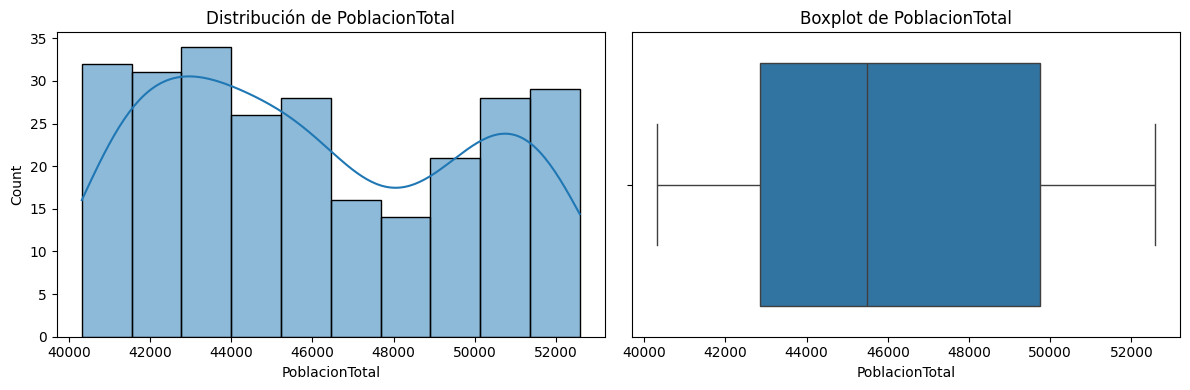

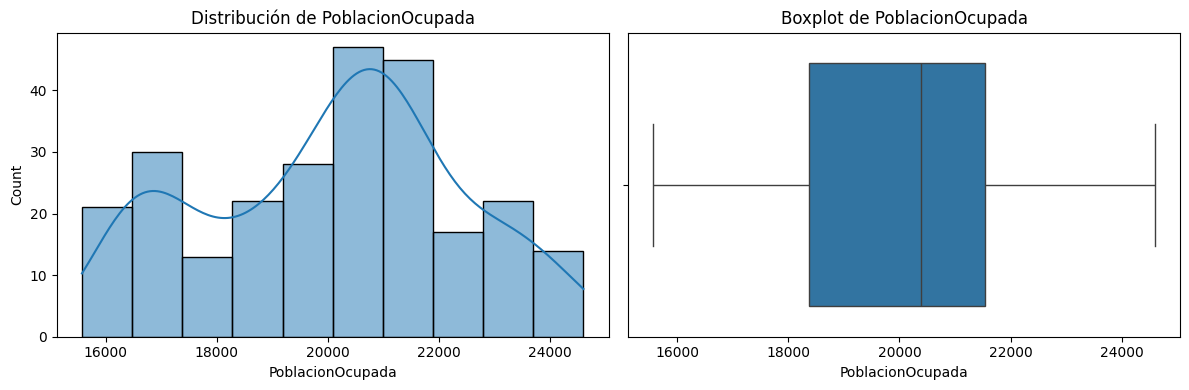

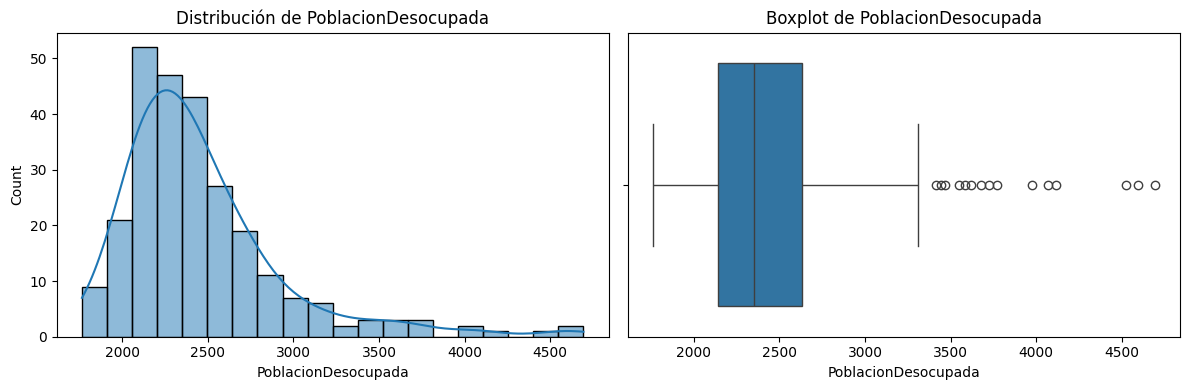

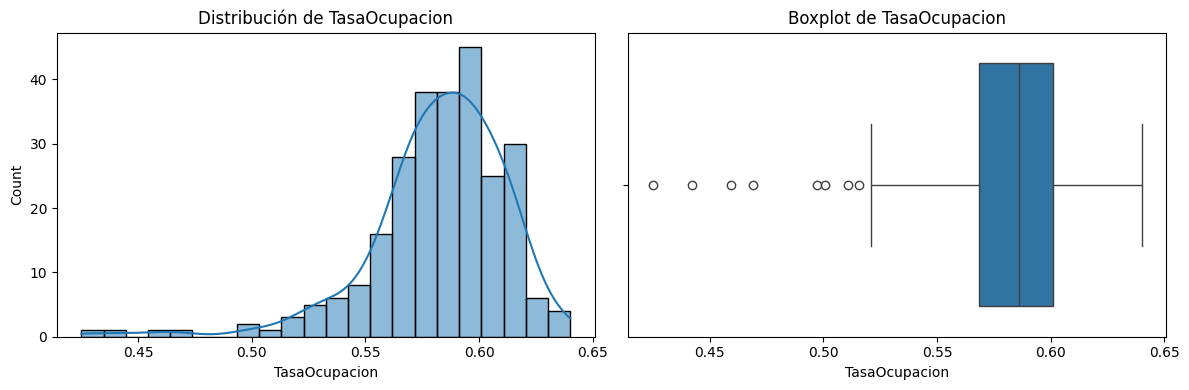

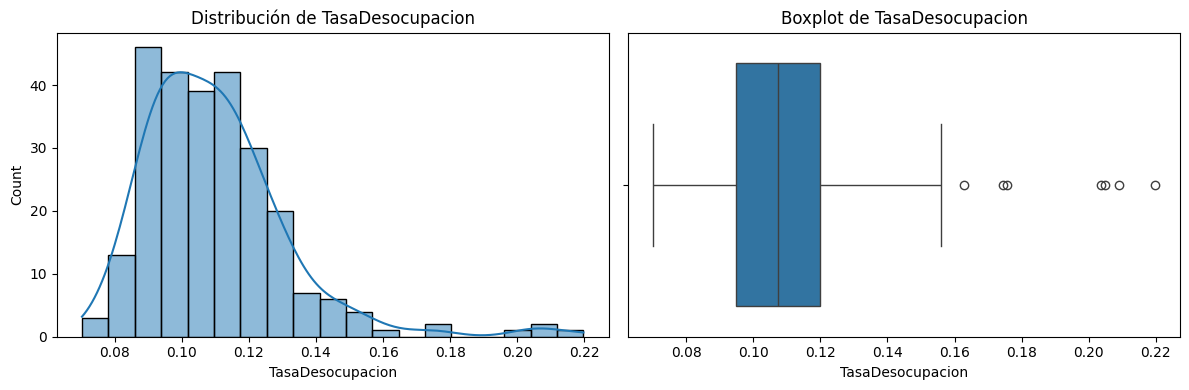

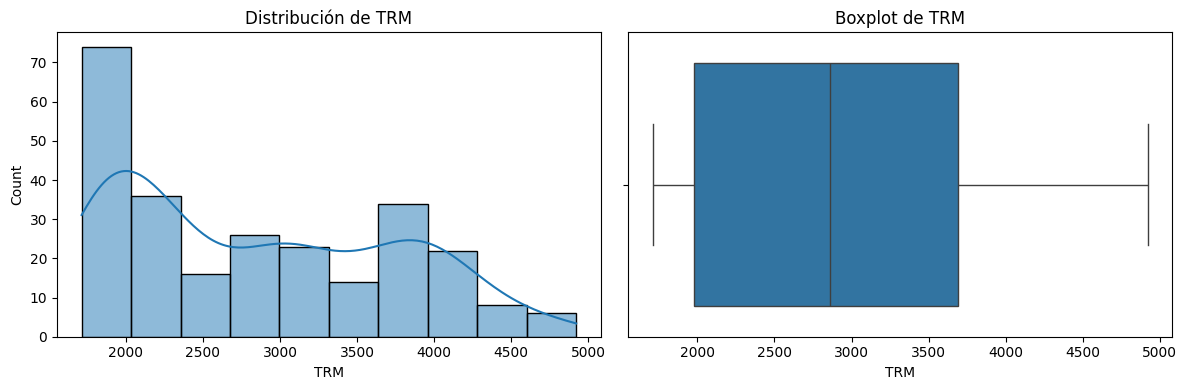

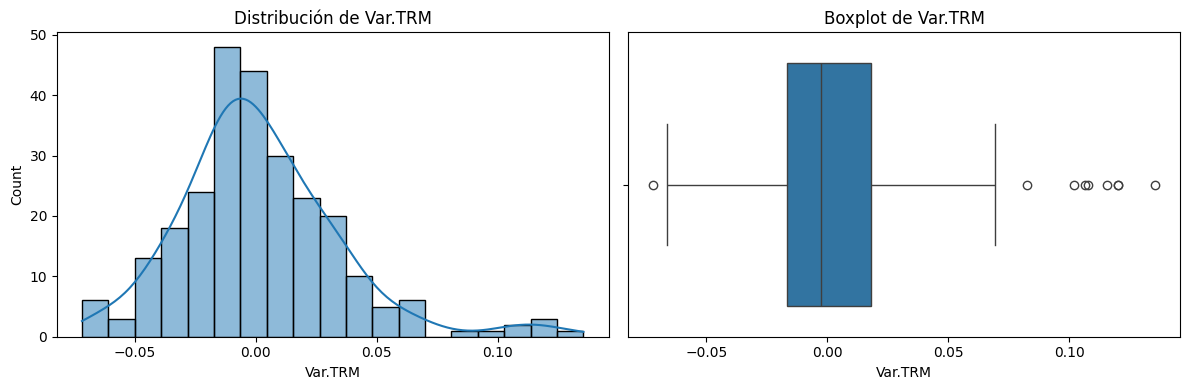

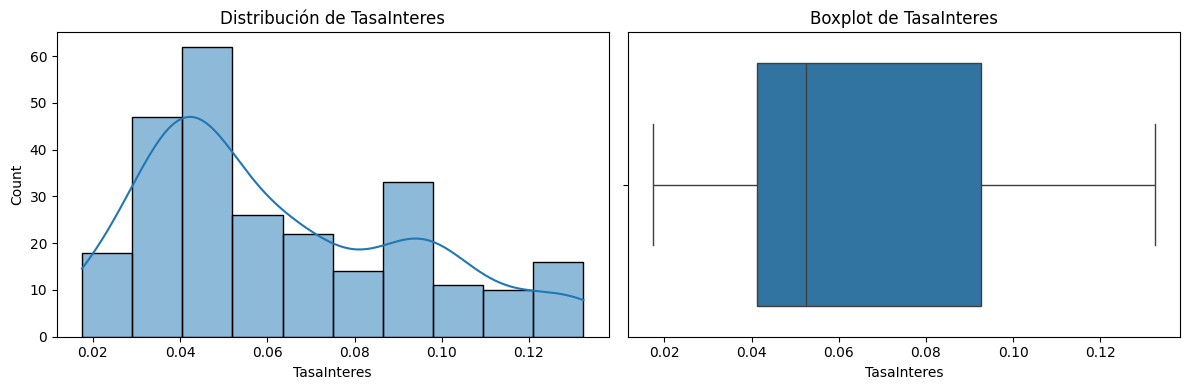

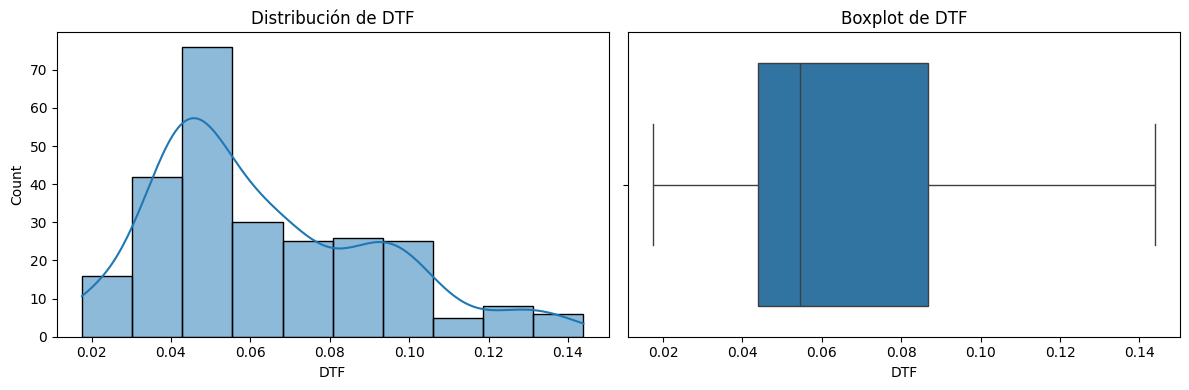

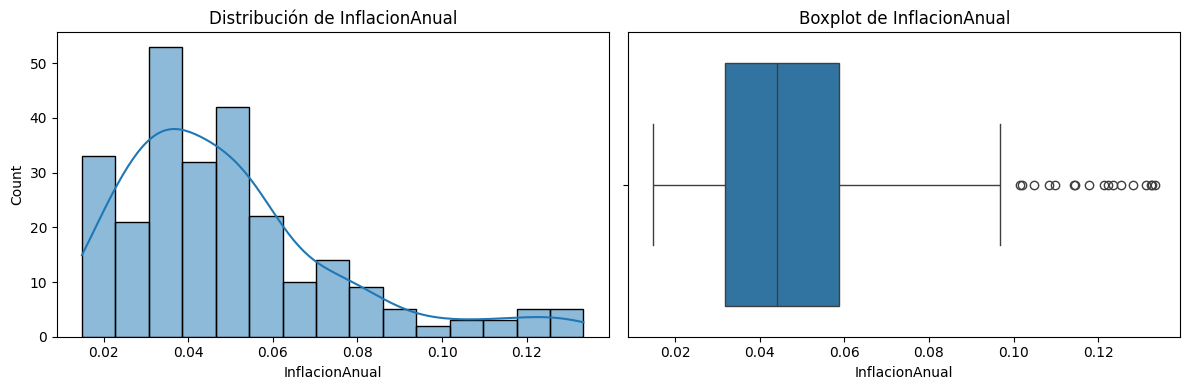

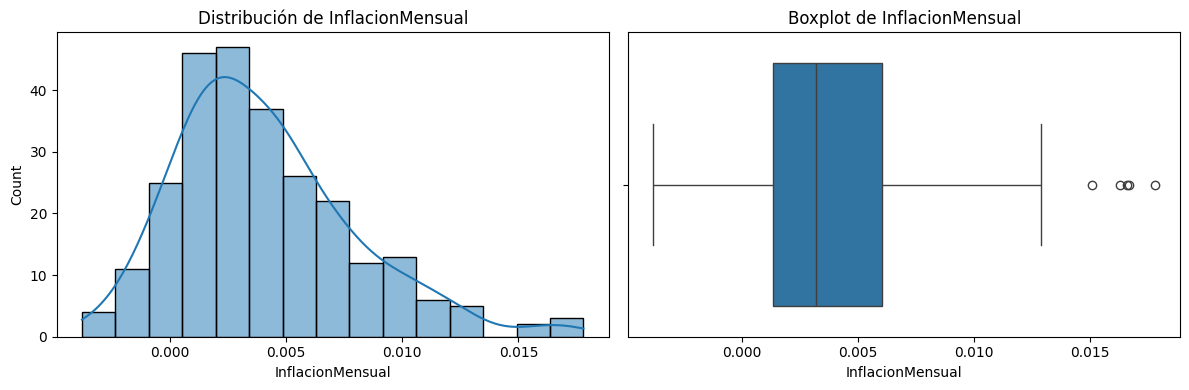

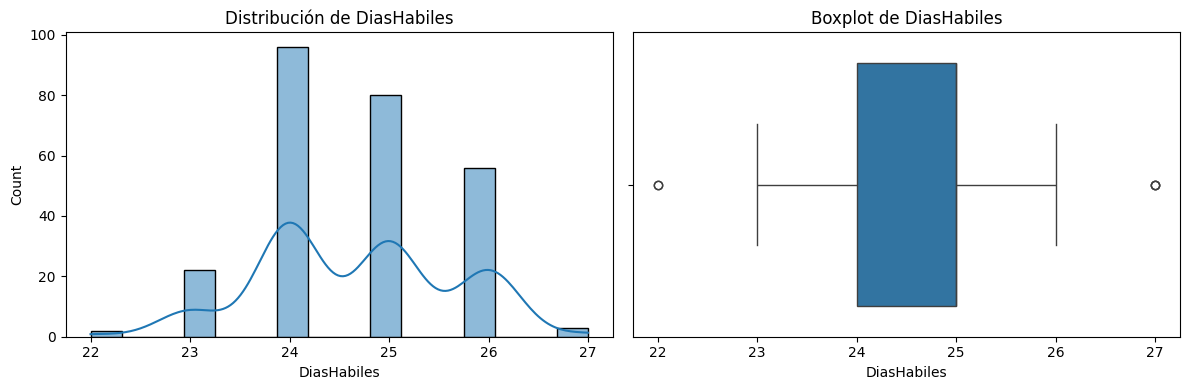

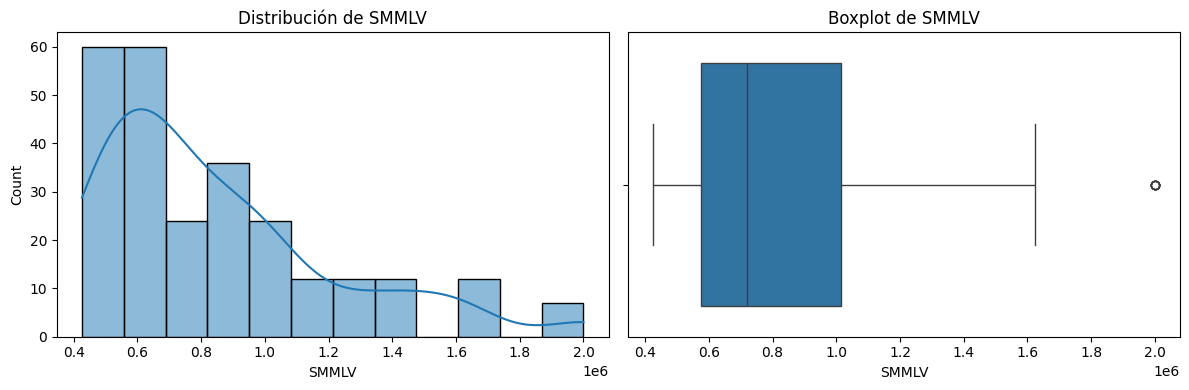

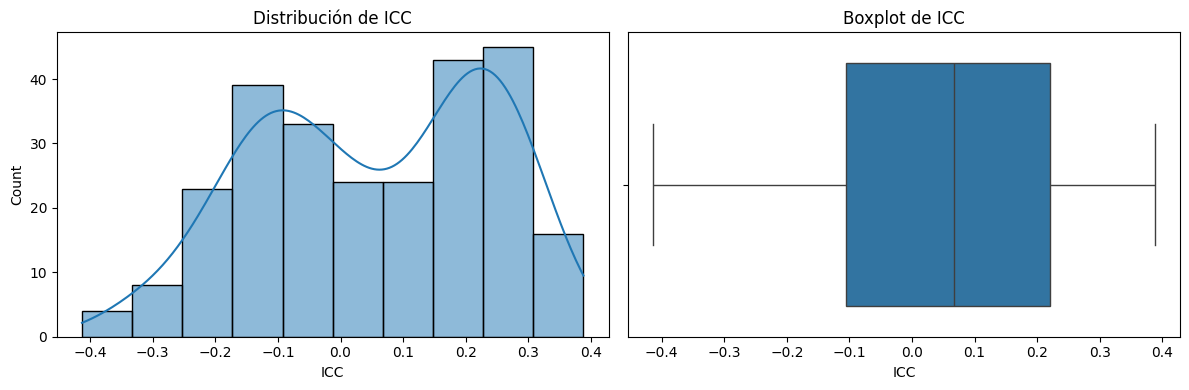

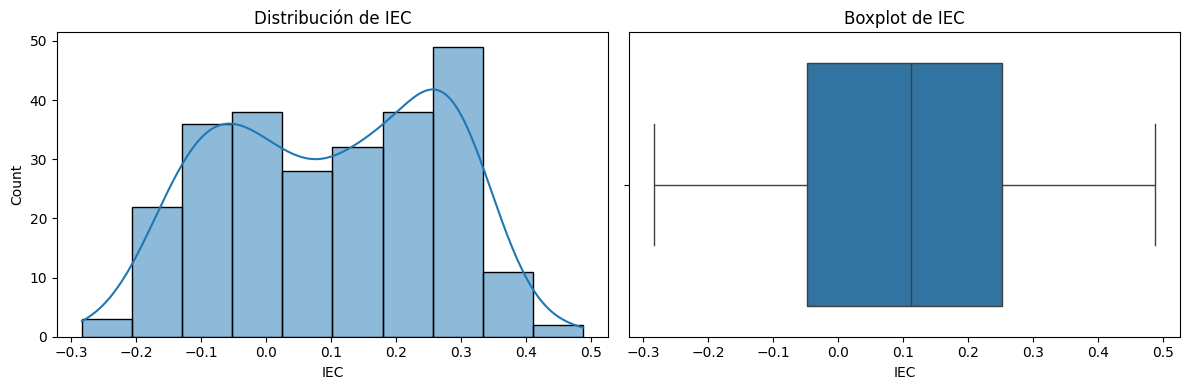

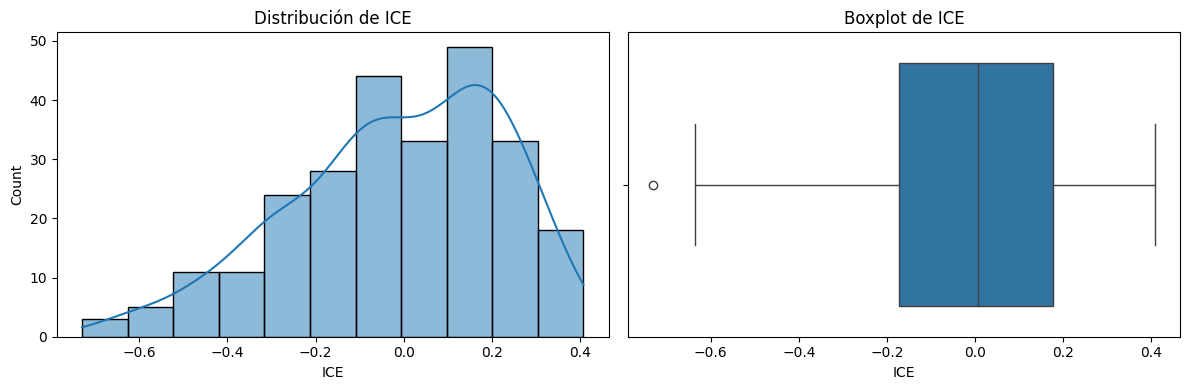

In [26]:
for col in variables_predictoras:

    datos = predictores[col].dropna()

    if datos.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(datos, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribución de {col}")

    sns.boxplot(x=datos, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}")

    plt.tight_layout()
    plt.show()

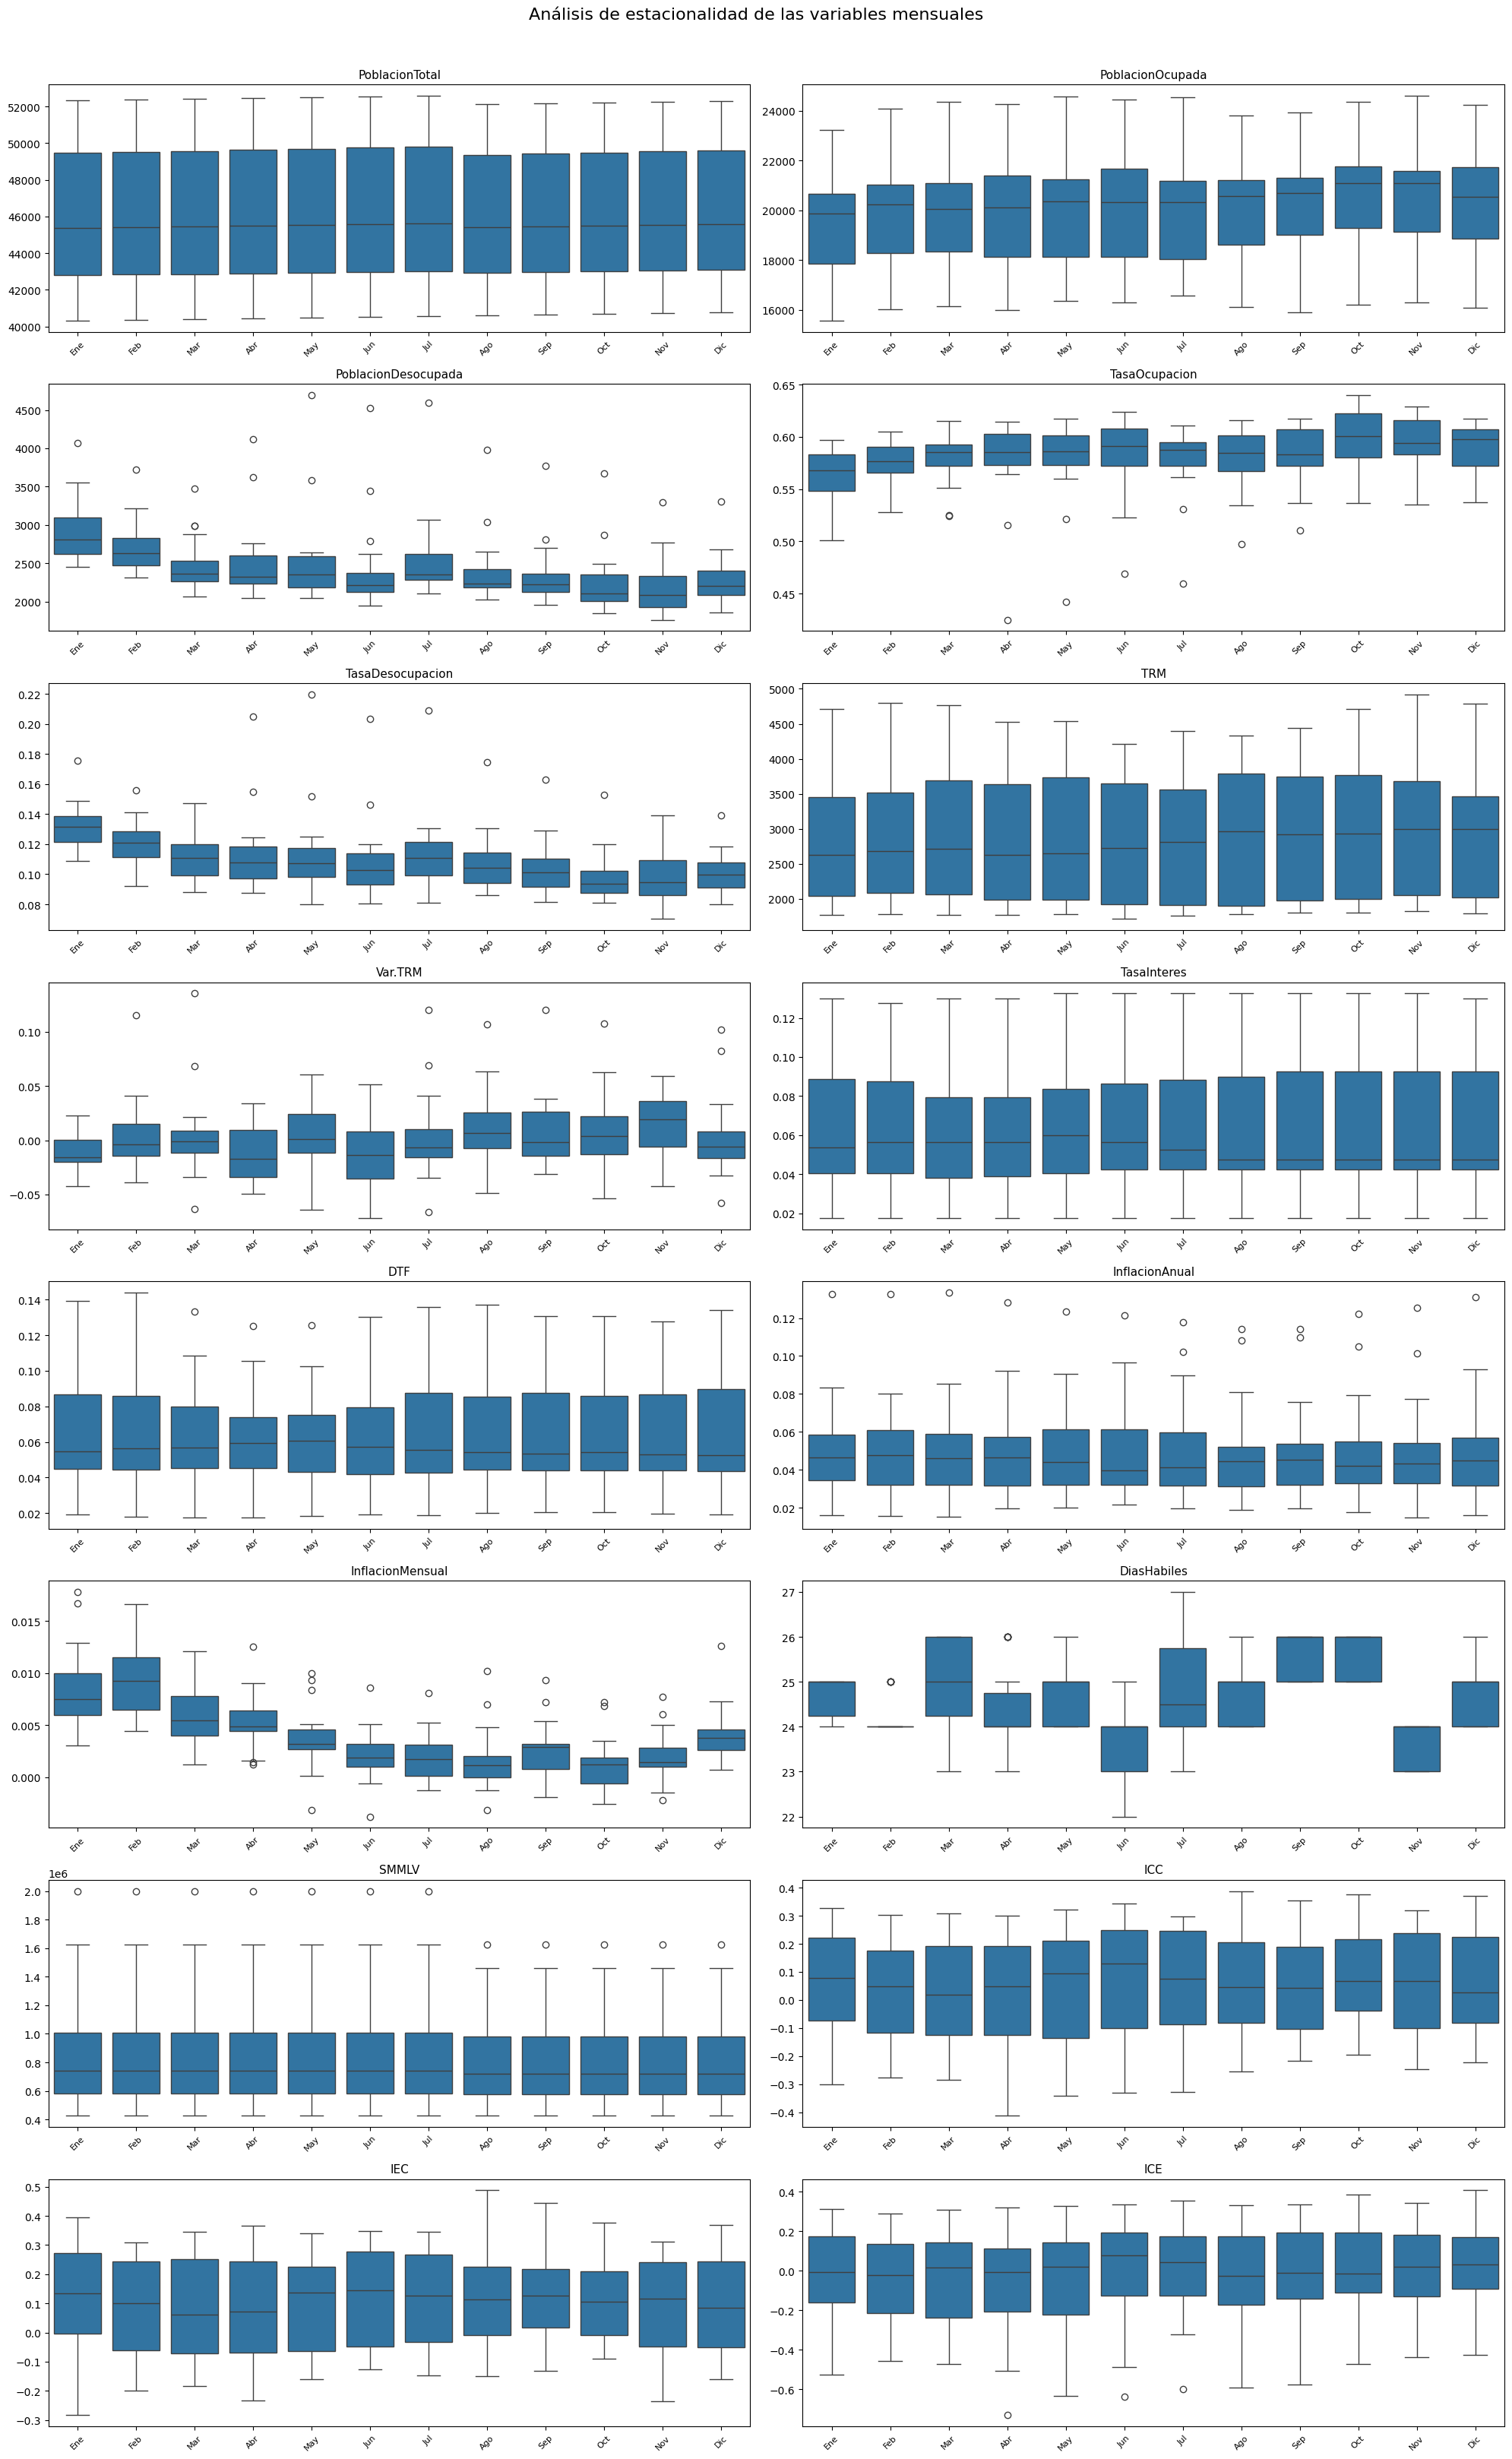

In [28]:
nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

variables_mensuales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Filtrar variables disponibles
variables_disponibles = [
    col for col in variables_mensuales
    if col in df_datamarket_men.columns
]

# Definir cuadrícula
ncols = 2
nrows = math.ceil(len(variables_disponibles) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(20, 4 * nrows)
)

axes = axes.flatten()

for i, col in enumerate(variables_disponibles):

    temporal = df_datamarket_men[
        ["Fecha", col]
    ].dropna().copy()

    temporal["Mes"] = temporal["Fecha"].dt.month

    sns.boxplot(
        data=temporal,
        x="Mes",
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].set_xticks(range(12))
    axes[i].set_xticklabels(nombres_meses, rotation=45, fontsize=8)

# Eliminar ejes vacíos
for j in range(len(variables_disponibles), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Análisis de estacionalidad de las variables mensuales",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

#####Variables: Periodicidad Trimestral

Las variables trimestrales describen la actividad económica agregada y el sector externo del país.

In [27]:
#Calidad de la data

variables_predictoras = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Conservar únicamente las columnas que existan en la base
variables_predictoras = [
    col for col in variables_predictoras
    if col in df_datamarket_trim.columns
]

predictores = df_datamarket_trim[variables_predictoras].copy()

for col in variables_predictoras:
    predictores[col] = pd.to_numeric(
        predictores[col], errors="coerce"
    )

inventario = pd.DataFrame({
    "No_nulos": predictores.notna().sum(),
    "Faltantes": predictores.isna().sum(),
    "Porcentaje_faltantes": predictores.isna().mean() * 100,
    "Valores_unicos": predictores.nunique()
})

display(inventario.round(2))

,No_nulos,Faltantes,Porcentaje_faltantes,Valores_unicos
PIB,86,0,0.00,86
Var.PIB,85,1,1.16,85
Exportaciones,86,0,0.00,86
Importaciones,86,0,0.00,86
Remesas,86,0,0.00,86
PIB_PC,86,0,0.00,86


In [29]:
#Métricas Estadísticas

display(predictores.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
PIB,86.0,195860.250,38848.961,126088.657,159262.015,200982.445,221924.416,262061.542
Var.PIB,85.0,0.009,0.025,-0.162,0.004,0.008,0.015,0.099
Exportaciones,86.0,29760.482,4022.718,21334.353,25944.901,30801.073,32907.607,36079.445
Importaciones,86.0,42705.260,13024.832,18667.178,30688.300,44290.312,50785.145,67264.113
Remesas,86.0,1596.102,746.823,731.130,1012.065,1280.355,1941.225,3354.000
PIB_PC,86.0,421.482,52.396,312.434,371.379,437.484,456.383,499.110


La gráfica muestra que el PIB crece de manera sostenida durante todo el periodo, con una desaceleración en 2009, una caída abrupta en el segundo trimestre de 2020 y una recuperación que supera el nivel previo a la pandemia desde 2021. Este cambio se observa con claridad en la variación trimestral del PIB, que se mantiene cerca de cero en condiciones normales, cae alrededor de 16% en 2020 y rebota cerca de 10% en el trimestre siguiente. Las exportaciones crecen hasta 2013, se estabilizan y presentan la misma caída en 2020. Las importaciones muestran un crecimiento más pronunciado, con caídas en 2009 y 2020, un máximo en 2022, un ajuste en 2023 y una nueva recuperación hasta máximos en 2026; esta variable es especialmente relevante para el sector, dado que la producción local depende de la importación de kits CKD. Las remesas permanecen estables entre 2008 y 2015 y, desde 2016, crecen de forma acelerada hasta triplicar su nivel, comportamiento similar al de los registros en los últimos años. Finalmente, el PIB per cápita replica la trayectoria del PIB, pero con un crecimiento más moderado desde 2022 debido al aumento de la población.

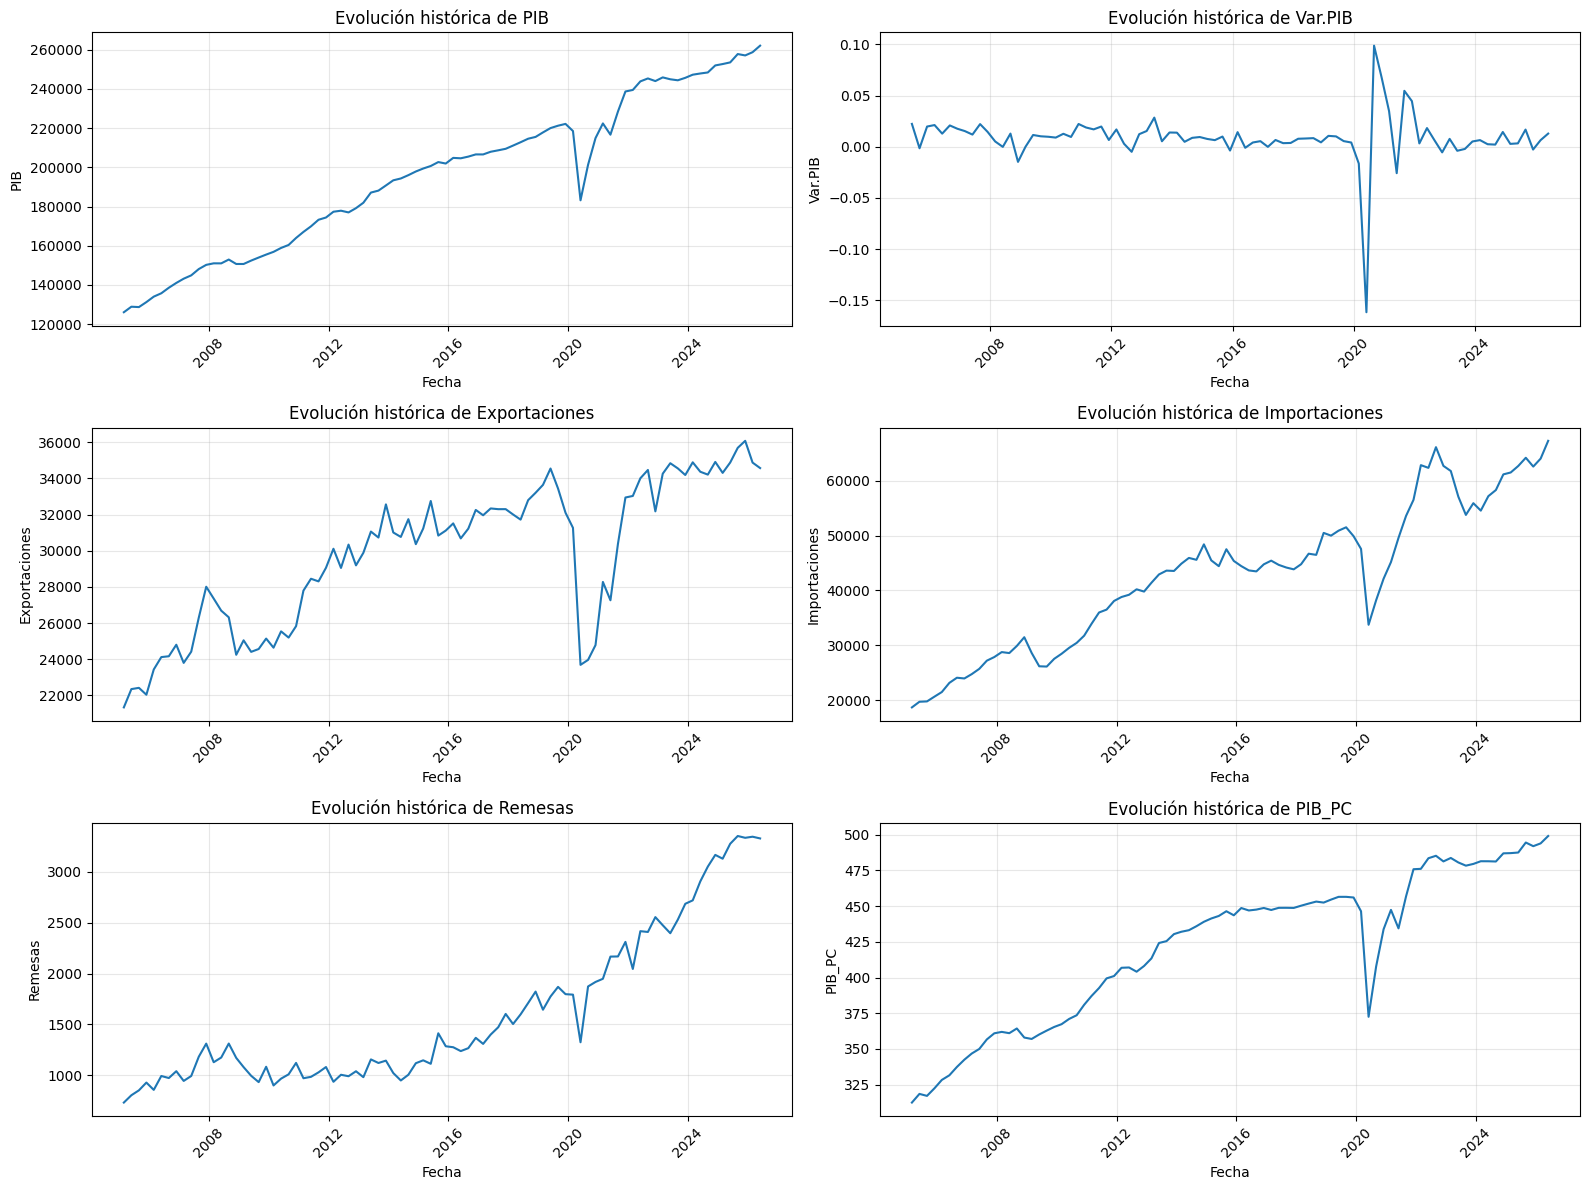

In [30]:

n_variables = len(variables_predictoras)

ncols = 2
nrows = math.ceil(n_variables / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 4 * nrows)
)

# Convertir los ejes en una lista, incluso si hay una sola fila
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i, col in enumerate(variables_predictoras):

    datos = (
        df_datamarket_trim[["FechaFin", col]]
        .dropna()
        .sort_values("FechaFin")
    )

    ax = axes[i]

    if datos.empty:
        ax.set_visible(False)
        continue

    ax.plot(datos["FechaFin"], datos[col], linewidth=1.5)

    ax.set_title(f"Evolución histórica de {col}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

# Ocultar espacios sobrantes en la cuadrícula
for j in range(n_variables, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

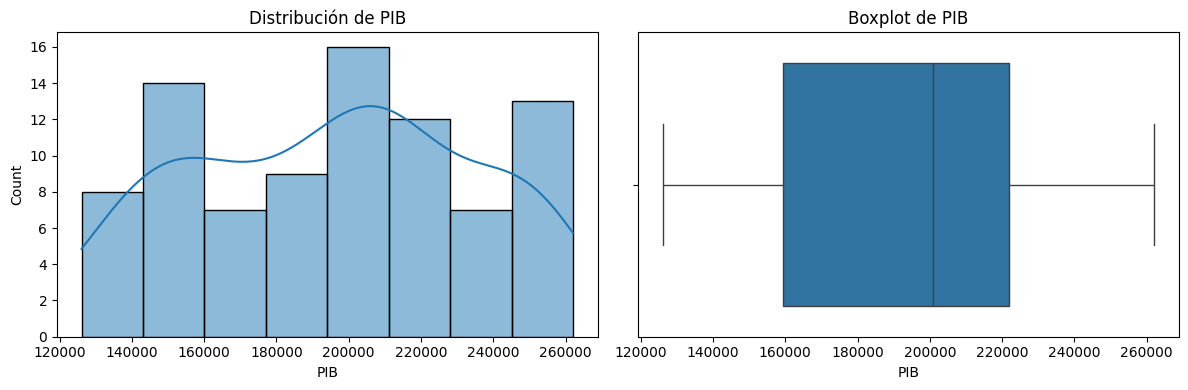

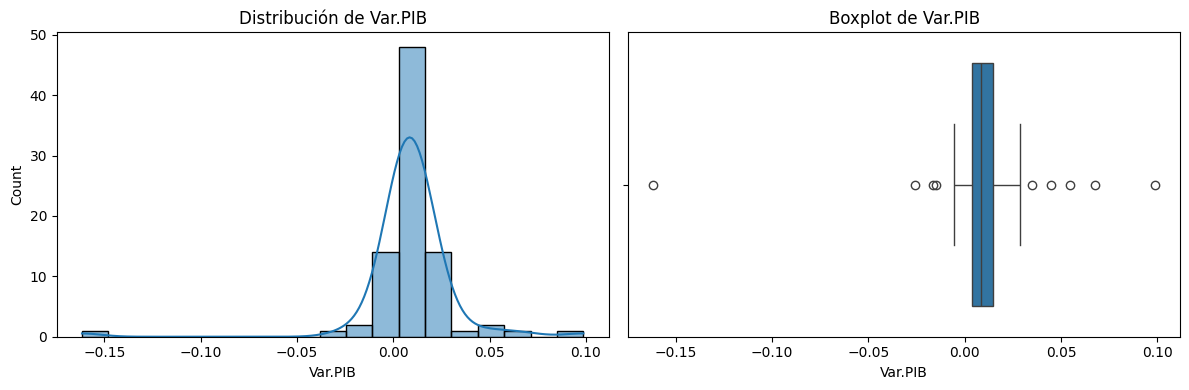

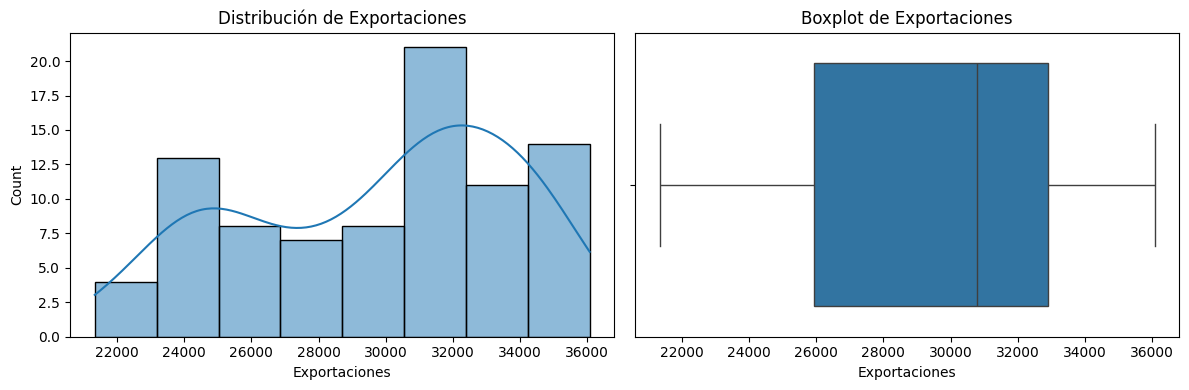

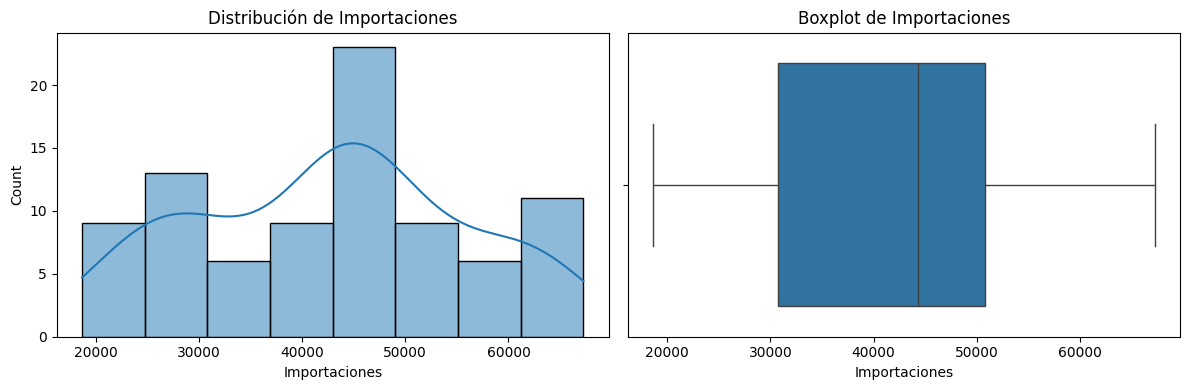

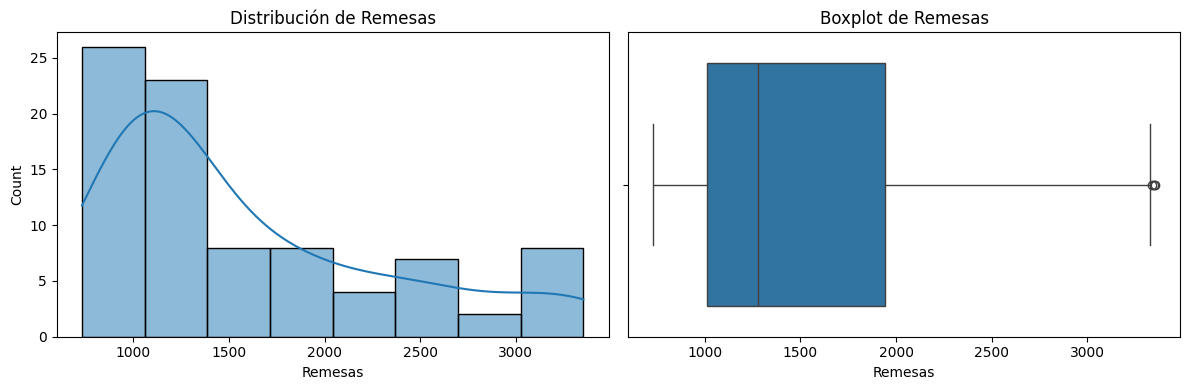

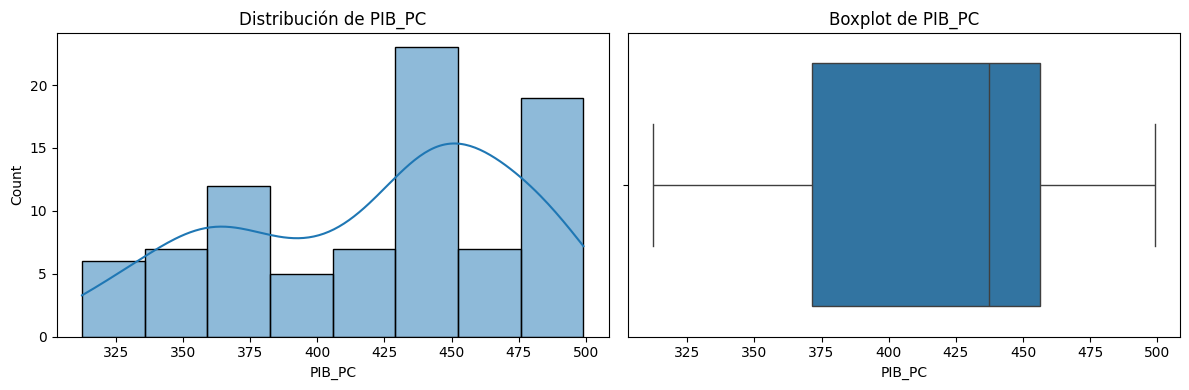

In [31]:
for col in variables_predictoras:

    datos = predictores[col].dropna()

    if datos.empty:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(datos, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribución de {col}")

    sns.boxplot(x=datos, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}")

    plt.tight_layout()
    plt.show()

La gráfica compara la distribución de cada variable trimestral según el trimestre del año. Las cajas de PIB, exportaciones, importaciones y PIB per cápita son prácticamente iguales entre T1 y T4, lo cual confirma la ausencia de estacionalidad esperada por tratarse de series desestacionalizadas; en consecuencia, la estacionalidad del modelo deberá provenir de la variable objetivo. Las remesas muestran una mediana ligeramente mayor en el segundo semestre, aunque la diferencia es pequeña. La variación del PIB concentra sus valores cerca de cero y sus atípicos corresponden a la caída de 2020 (T2) y a las recuperaciones posteriores (T3 y T4).

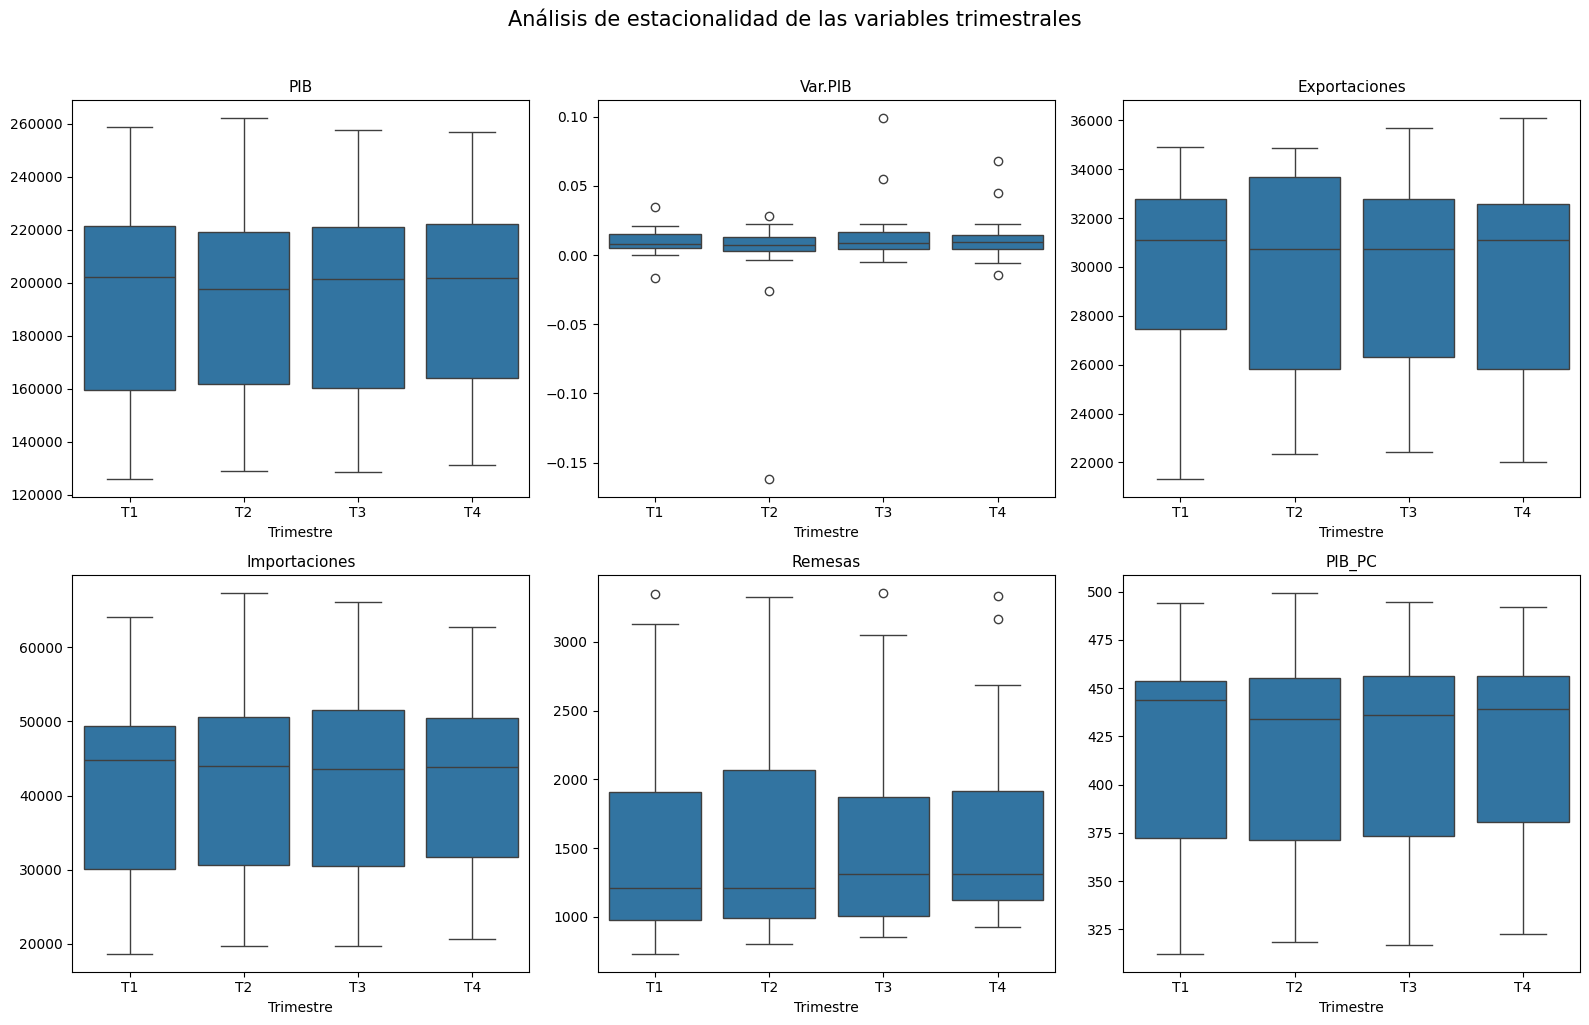

In [32]:
nombres_trimestres = ["T1", "T2", "T3", "T4"]

variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Conservar únicamente las variables que existen en el DataFrame
variables_disponibles = [
    col for col in variables_trimestrales
    if col in df_datamarket_trim.columns
]

ncols = 3
nrows = math.ceil(len(variables_disponibles) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 5 * nrows)
)

axes = axes.flatten()

for i, col in enumerate(variables_disponibles):

    temporal = df_datamarket_trim[["FechaFin", col]].dropna().copy()

    temporal["Trimestre"] = temporal["FechaFin"].dt.quarter

    sns.boxplot(
        data=temporal,
        x="Trimestre",
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("Trimestre")
    axes[i].set_ylabel("")
    axes[i].set_xticks(range(4))
    axes[i].set_xticklabels(nombres_trimestres)

# Eliminar espacios de gráficos que no se utilicen
for j in range(len(variables_disponibles), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Análisis de estacionalidad de las variables trimestrales",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

####Relación entre las Variables

En esta etapa se analiza la relación entre los registros y cada variable predictora mediante gráficos de dispersión, matrices de correlación y correlaciones con rezagos, con el fin de identificar las variables con mayor potencial predictivo, detectar redundancias entre ellas y definir los rezagos a utilizar.

In [33]:
# Lista de predictores mensuales
variables_mensuales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

# Conservar las variables disponibles
predictores_mensuales = [
    col for col in variables_mensuales
    if col in df_datamarket_men.columns
]


# Preparar las fechas sin modificar las bases originales
datos_objetivo = objetivo[["Fecha", "Registros"]].copy()
datos_predictores = df_datamarket_men[
    ["Fecha"] + predictores_mensuales
].copy()

datos_objetivo["Fecha"] = pd.to_datetime(datos_objetivo["Fecha"])
datos_predictores["Fecha"] = pd.to_datetime(datos_predictores["Fecha"])


# Integrar ambas bases
base_analisis = datos_objetivo.merge(
    datos_predictores,
    on="Fecha",
    how="inner",
    validate="one_to_one"
)

base_analisis = base_analisis.sort_values("Fecha").reset_index(drop=True)


columnas_correlacion = ["Registros"] + predictores_mensuales

corr_pearson = base_analisis[
    columnas_correlacion
].corr(method="pearson", numeric_only=True)

corr_spearman = base_analisis[
    columnas_correlacion
].corr(method="spearman", numeric_only=True)


La gráfica muestra que las relaciones más claras con los registros son positivas y aproximadamente lineales con el SMMLV, la población ocupada y la población total; en estas dos últimas, los puntos más recientes se ubican por encima de la recta, lo que sugiere una relación no lineal en el periodo de mayor crecimiento. En el caso del SMMLV, los puntos se agrupan en columnas verticales porque el salario se mantiene constante durante cada año. La TRM presenta una relación positiva moderada con dos nubes de puntos que corresponden al periodo previo y posterior a la devaluación de 2015. La tasa de desocupación muestra una relación negativa, coherente con la teoría económica. La tasa de interés, la DTF y la inflación presentan relaciones positivas débiles y muy dispersas, contrarias a lo esperado, lo que sugiere que su efecto no es contemporáneo o está mezclado con la tendencia general. Los índices de confianza (ICC, IEC e ICE) muestran una relación negativa débil, explicada en buena medida por el deterioro de la confianza en los mismos años en que el mercado creció. La población desocupada, la tasa de ocupación, la Var.TRM y los días hábiles no muestran una relación clara.

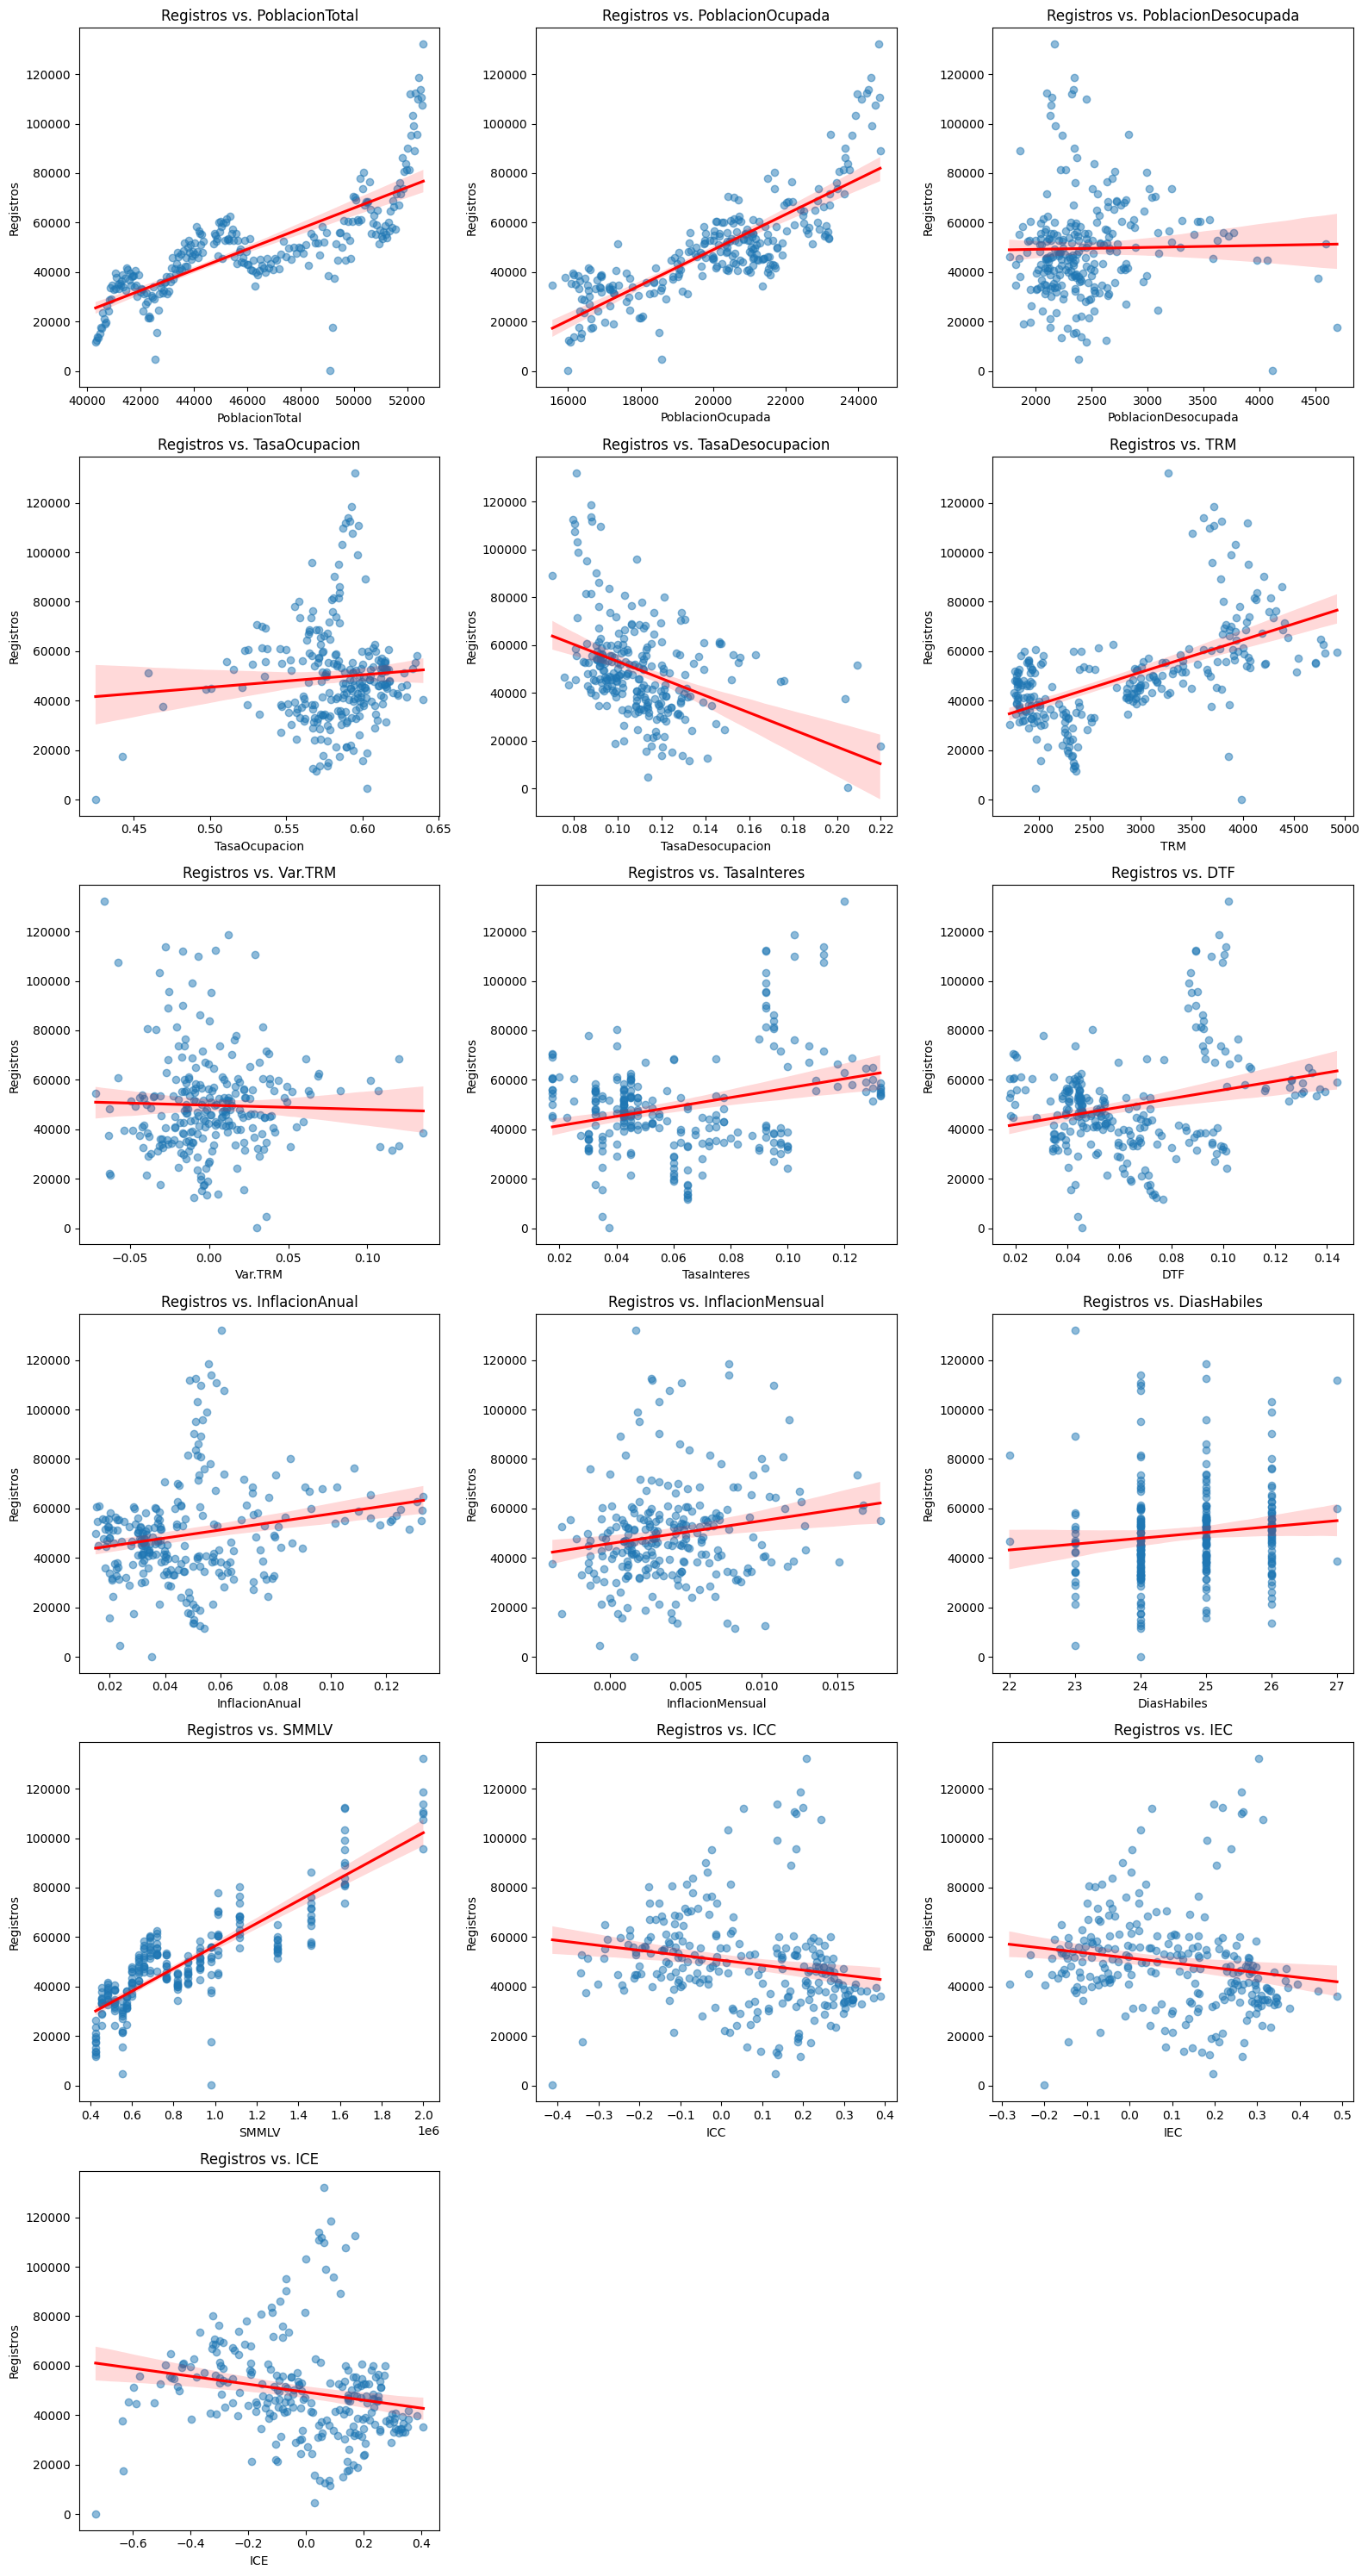

In [34]:
variables_graficos = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

variables_graficos = [
    col for col in variables_graficos
    if col in base_analisis.columns
]

ncols = 3
nrows = math.ceil(len(variables_graficos) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(16, 5 * nrows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(variables_graficos):

    temporal = base_analisis[
        ["Registros", col]
    ].dropna()

    sns.regplot(
        data=temporal,
        x=col,
        y="Registros",
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"},
        ax=axes[i]
    )

    axes[i].set_title(f"Registros vs. {col}")

for j in range(len(variables_graficos), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Los registros trimestrales presentan una relación positiva, fuerte y lineal con el PIB, las exportaciones, las importaciones, las remesas y el PIB per cápita, lo cual es consistente con la literatura que vincula la demanda de motocicletas con la capacidad adquisitiva de los hogares. Sin embargo, los trimestres más recientes, con más de 250 mil registros, se ubican por encima de la recta, indicando que el crecimiento reciente del mercado es mayor al que explican estas variables por sí solas. La variación del PIB no muestra relación con los registros: la nube de puntos se concentra cerca de cero y la pendiente depende casi por completo del dato atípico de 2020.


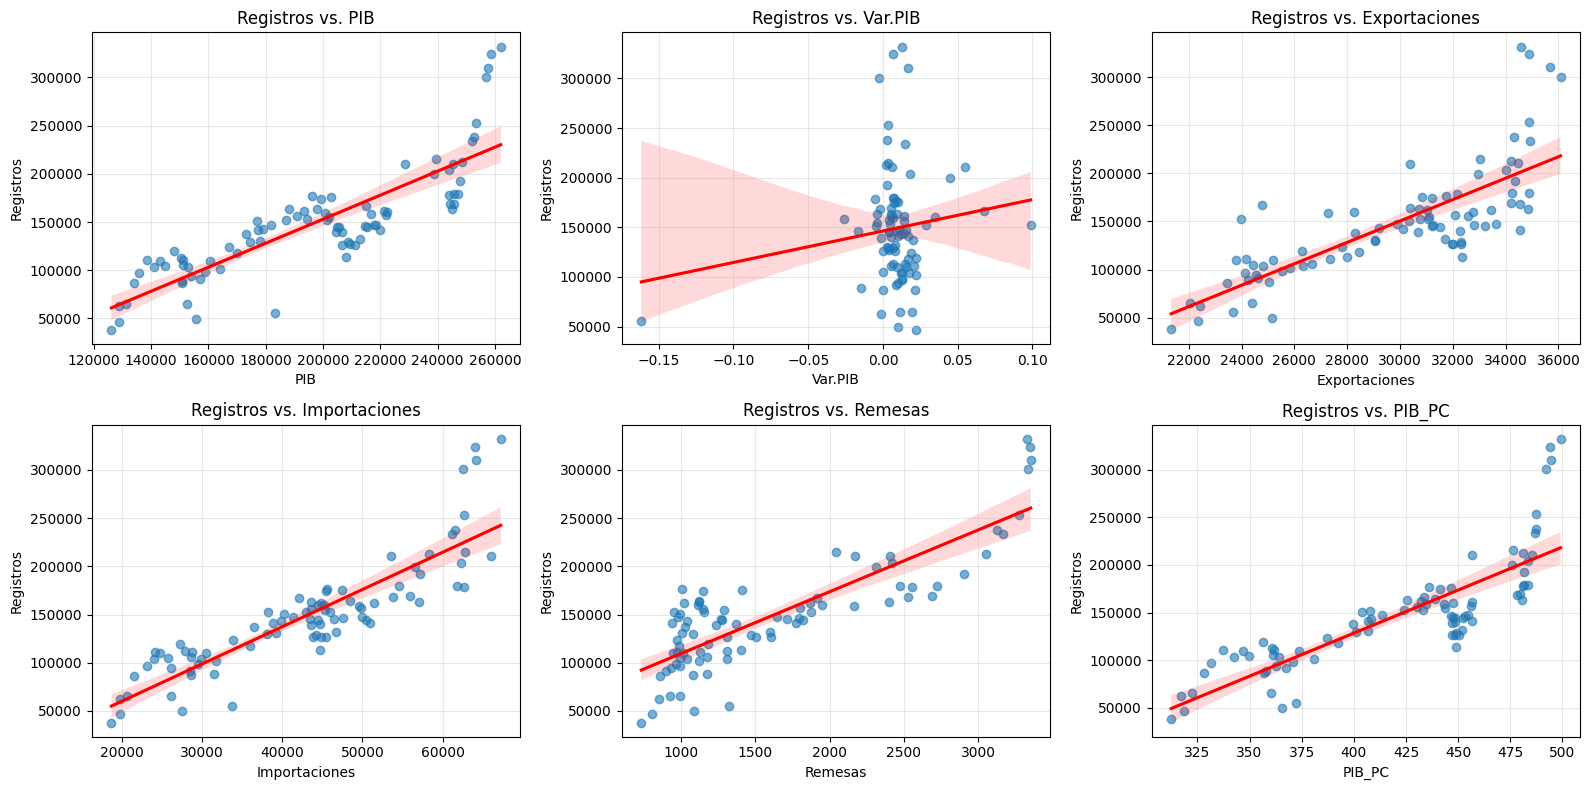

In [35]:
df = df_datamarket_trim.copy()

variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

ncols = 3
nrows = math.ceil(len(variables_trimestrales) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 4 * nrows)
)

axes = axes.flatten()

for i, variable in enumerate(variables_trimestrales):
    sns.regplot(
        data=df,
        x=variable,
        y="Registros",
        ax=axes[i],
        scatter_kws={"alpha": 0.6},
        line_kws={"color": "red"}
    )

    axes[i].set_title(f"Registros vs. {variable}")
    axes[i].grid(True, alpha=0.3)

for j in range(len(variables_trimestrales), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

La matriz de correlación de Spearman permite explorar cómo se relacionan los registros de motocicletas con las dinámicas demográficas, laborales y económicas del país, proporcionando indicios sobre los factores que podrían estar asociados al comportamiento de la demanda. Los resultados sugieren que el crecimiento del mercado presenta una relación importante con la evolución de la población y del ingreso nominal, representado por variables como la población total (0,83), la población ocupada (0,82) y el salario mínimo (0,83). Estas asociaciones podrían reflejar el efecto conjunto del crecimiento demográfico y de la capacidad adquisitiva sobre la demanda potencial de motocicletas. Por otra parte, la correlación positiva observada con la TRM (0,59) y la relación negativa con la tasa de desocupación (-0,42) sugieren que las condiciones macroeconómicas y laborales también podrían estar vinculadas con la evolución del mercado.

Sin embargo, estas relaciones deben interpretarse considerando que las series presentan tendencias temporales y que la correlación no permite establecer efectos causales. Un aspecto relevante es la elevada correlación entre algunos predictores, como entre la tasa de interés y la DTF, así como entre los indicadores de confianza del consumidor, estas asociaciones evidencian la presencia de multicolinealidad potencial entre los mismos, aspecto que deberá considerarse durante la selección de variables.


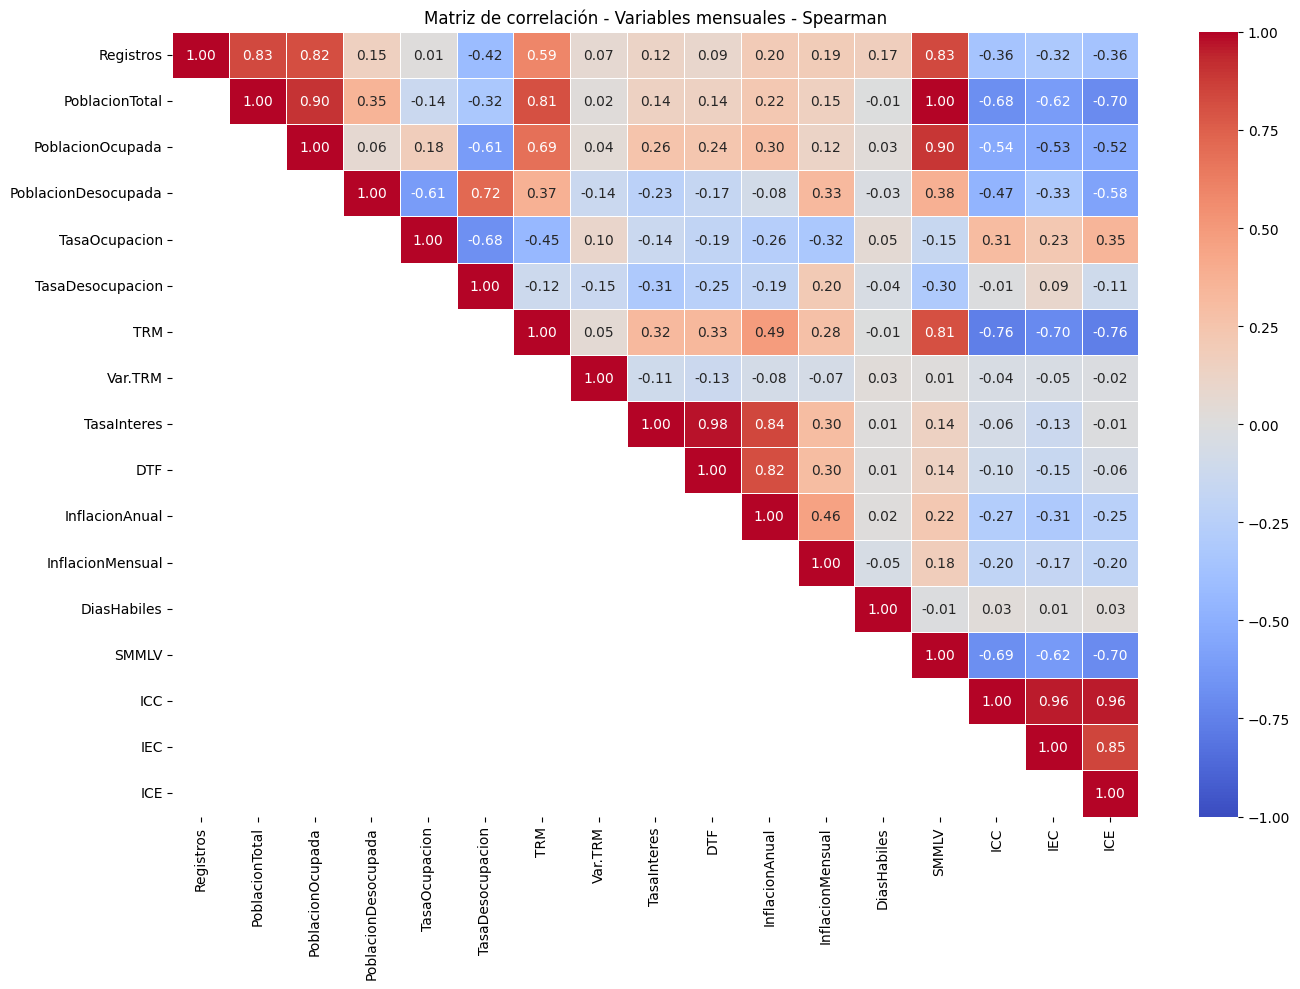

In [36]:
# Seleccionar variables numéricas
variables = df_datamarket_men.select_dtypes(include="number")

# Calcular la matriz de correlación de Spearman
matriz_corr = variables.corr(method="spearman")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(np.ones_like(matriz_corr, dtype=bool), k=-1)

# Visualizar la matriz
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables mensuales - Spearman")
plt.tight_layout()
plt.show()


La matriz de Spearman trimestral muestra altas correlaciones entre los registros y todas las variables en niveles: importaciones (0,91), PIB (0,87), PIB per cápita (0,86), exportaciones (0,81) y remesas (0,76). La variación del PIB, en cambio, presenta una correlación ligeramente negativa (-0,13) y correlaciones negativas con las demás variables, lo que confirma que, a diferencia de las series en niveles, no comparte la tendencia de largo plazo. Entre predictoras, la multicolinealidad es muy alta: PIB, importaciones y PIB per cápita se correlacionan en 0,96 y 0,98 entre sí, y las exportaciones superan 0,91 con estas variables.


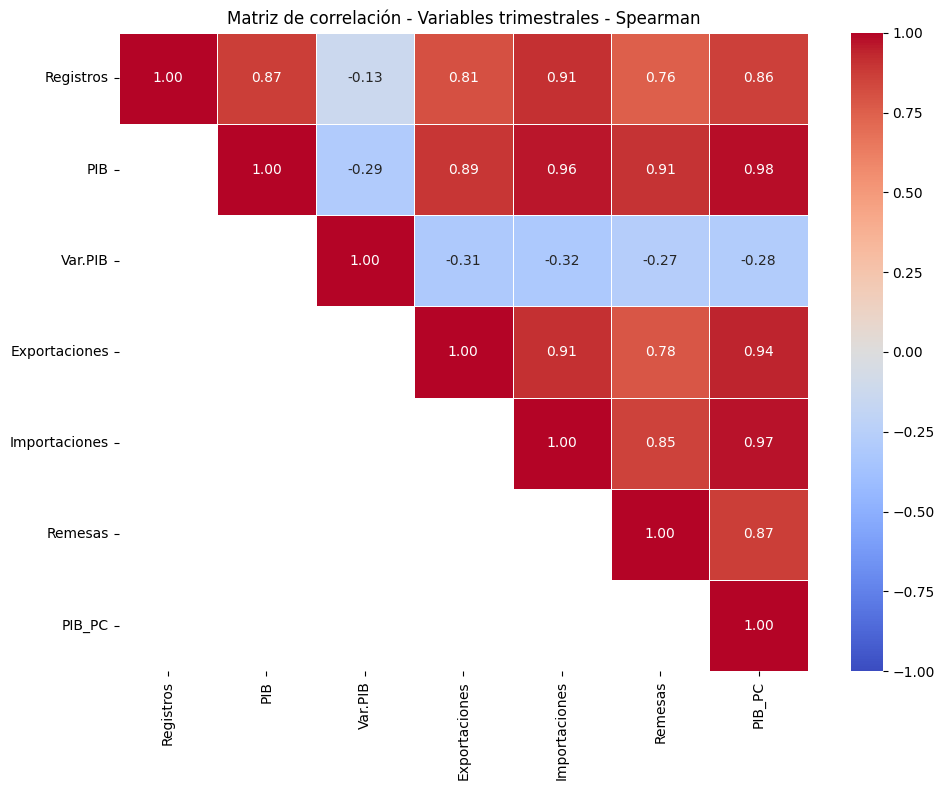

In [41]:
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Seleccionar variables trimestrales + variable objetivo
variables_corr = ["Registros"] + variables_trimestrales

# Seleccionar únicamente las columnas de interés
datos_corr = df_datamarket_trim[variables_corr]

# Calcular la matriz de correlación de Pearson
matriz_corr = datos_corr.corr(method="spearman")

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(
    np.ones_like(matriz_corr, dtype=bool),
    k=-1
)

# Visualizar la matriz
plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Variables trimestrales - Spearman")
plt.tight_layout()
plt.show()

In [38]:
resultados_rezagos = []

for col in predictores_mensuales:

    for lag in range(0, 13):

        temporal = base_analisis[
            ["Fecha", "Registros", col]
        ].copy()

        # Predictor observado lag meses antes
        temporal["Predictor_rezagado"] = temporal[col].shift(lag)

        temporal = temporal[
            ["Registros", "Predictor_rezagado"]
        ].dropna()

        if len(temporal) < 12:
            continue

        correlacion = temporal["Registros"].corr(
            temporal["Predictor_rezagado"],
            method="spearman"
        )

        resultados_rezagos.append({
            "Variable": col,
            "Rezago_meses": lag,
            "Correlacion_Spearman": correlacion,
            "Observaciones": len(temporal)
        })

tabla_rezagos = pd.DataFrame(resultados_rezagos)
display(tabla_rezagos)

,Variable,Rezago_meses,Correlacion_Spearman,Observaciones
0,PoblacionTotal,0,0.832766,259
1,PoblacionTotal,1,0.831013,258
2,PoblacionTotal,2,0.829202,257
3,PoblacionTotal,3,0.827363,256
4,PoblacionTotal,4,0.825476,255
...,...,...,...,...
203,ICE,8,-0.440433,251
204,ICE,9,-0.445332,250
205,ICE,10,-0.474486,249
206,ICE,11,-0.486811,248


In [39]:
mejores_rezagos = (
    tabla_rezagos
    .assign(
        Abs_Correlacion=lambda df:
            df["Correlacion_Spearman"].abs()
    )
    .sort_values(
        ["Variable", "Abs_Correlacion"],
        ascending=[True, False]
    )
    .groupby("Variable")
    .head(3)
    .sort_values("Variable")
)

display(mejores_rezagos)

,Variable,Rezago_meses,Correlacion_Spearman,Observaciones,Abs_Correlacion
116,DTF,12,-0.135083,247,0.135083
115,DTF,11,-0.124611,248,0.124611
114,DTF,10,-0.113592,249,0.113592
143,DiasHabiles,0,0.167785,259,0.167785
144,DiasHabiles,1,-0.101707,258,0.101707
154,DiasHabiles,11,0.078573,248,0.078573
181,ICC,12,-0.472618,247,0.472618
180,ICC,11,-0.470460,248,0.470460
179,ICC,10,-0.458942,249,0.458942
205,ICE,10,-0.474486,249,0.474486


In [40]:
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

predictores_trim_disponibles = [
    col for col in variables_trimestrales
    if col in df_datamarket_trim.columns
]

# Registros mensuales agrupados por trimestre
datos_registros = objetivo[["Fecha", "Registros"]].copy()

datos_registros["Trimestre"] = (
    datos_registros["Fecha"].dt.to_period("Q")
)

registros_trim = (
    datos_registros
    .groupby("Trimestre", as_index=False)
    .agg(Registros=("Registros", "sum"))
)

# Preparar predictores trimestrales
datos_trim = df_datamarket_trim[
    ["FechaFin"] + predictores_trim_disponibles
].copy()

datos_trim["Trimestre"] = (
    datos_trim["FechaFin"].dt.to_period("Q")
)

# Verificar que exista un único registro por trimestre
print(
    "Trimestres duplicados en predictores:",
    datos_trim["Trimestre"].duplicated().sum()
)

# Integrar ambas bases por trimestre
base_trimestral = registros_trim.merge(
    datos_trim[["Trimestre"] + predictores_trim_disponibles],
    on="Trimestre",
    how="inner",
    validate="one_to_one"
)

display(base_trimestral.head())

Trimestres duplicados en predictores: 0


,Trimestre,Registros,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC
0,2005Q1,37999,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757
1,2005Q2,46544,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879
2,2005Q3,62445,128717.054381,-0.001469,22416.208758,19760.125657,851.47,317.114632
3,2005Q4,65080,131260.139968,0.019757,22034.764695,20628.289335,927.86,322.419309
4,2006Q1,86446,134044.350100,0.021211,23431.599497,21467.411899,855.89,328.288713


In [42]:
# Ordenar por fecha
df_datamercado = df_datamarket_men.sort_values("Fecha").copy()

# Identificar variables explicativas numéricas
variables_explicativas = [
    c for c in df_datamercado.select_dtypes(include="number").columns
    if c != "Registros"
]

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_mensuales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

print(
    tabla_rezagos.sort_values(
        "Correlacion",
        key=lambda x: x.abs(),
        ascending=False
    ).to_string(index=False)
)

           Variable  Rezago_mensuales  Correlacion
              SMMLV                 1     0.851407
              SMMLV                 2     0.848491
              SMMLV                 0     0.848283
              SMMLV                 6     0.845897
              SMMLV                 4     0.843916
              SMMLV                 3     0.843764
              SMMLV                 5     0.843362
              SMMLV                11     0.839600
              SMMLV                 7     0.836394
              SMMLV                12     0.836335
              SMMLV                 8     0.834937
              SMMLV                10     0.834908
              SMMLV                 9     0.834158
   PoblacionOcupada                 0     0.812779
   PoblacionOcupada                 1     0.784972
     PoblacionTotal                 0     0.777352
     PoblacionTotal                 1     0.776039
     PoblacionTotal                 2     0.774562
     PoblacionTotal            

Dado que las variables macroeconómicas deben proyectarse a futuro, la gráfica evalúa la correlación de los registros con cada variable mensual rezagada entre 0 y 12 meses. El SMMLV (0,83 a 0,85) y la población total (0,76 a 0,78) mantienen correlaciones altas y estables en todos los rezagos. La población ocupada pierde fuerza gradualmente (de 0,81 a 0,70), mientras que la TRM la aumenta levemente (de 0,57 a 0,62), lo que sugiere un efecto retardado de la tasa de cambio sobre el precio y la demanda. Los índices de confianza fortalecen su correlación negativa con el rezago (de cerca de 0,19 a -0,40 en el rezago de 12 meses). En contraste, la tasa de desocupación (de -0,39 a -0,09), la tasa de interés, la DTF y la inflación pierden correlación a medida que aumenta el rezago. Los días hábiles solo tienen relación en el mes contemporáneo (0,11), lo que es coherente con su naturaleza de calendario; al ser conocidos con anticipación, pueden incluirse sin rezago. La Var. TRM no presenta correlación en ningún rezago.

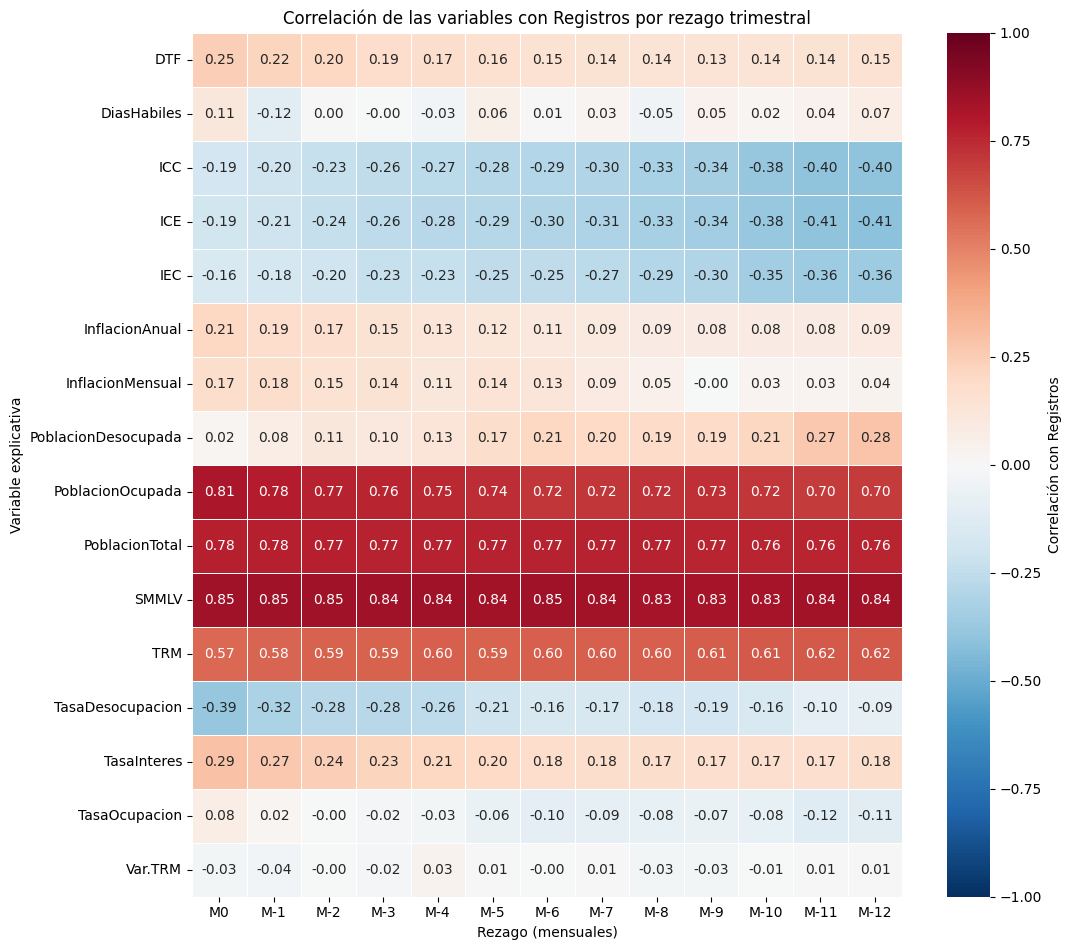

In [43]:
# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_mensuales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
)

# Graficar
plt.figure(figsize=(11, max(5, len(mapa_rezagos) * 0.6)))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables con Registros por rezago trimestral")
plt.xlabel("Rezago (mensuales)")
plt.ylabel("Variable explicativa")
plt.xticks(
    ticks=[i + 0.5 for i in range(13)],
    labels=["M0", "M-1", "M-2", "M-3", "M-4", "M-5", "M-6", "M-7", "M-8", "M-9", "M-10", "M-11", "M-12"],
    rotation=0
)

plt.tight_layout()
plt.show()

In [44]:
# Ordenar por fecha
df_datamercado = df_datamarket_trim.sort_values("FechaFin").copy()

# Identificar variables explicativas numéricas
variables_explicativas = [
    c for c in df_datamercado.select_dtypes(include="number").columns
    if c != "Registros"
]

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_trimestrales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

print(
    tabla_rezagos.sort_values(
        "Correlacion",
        key=lambda x: x.abs(),
        ascending=False
    ).to_string(index=False)
)

           Variable  Rezago_trimestrales  Correlacion
      Importaciones                    0     0.874650
              SMMLV                    0     0.862802
              SMMLV                    2     0.859101
              SMMLV                    1     0.857495
              SMMLV                    4     0.855872
              SMMLV                    3     0.854075
                PIB                    0     0.841536
            Remesas                    0     0.832503
   PoblacionOcupada                    0     0.830264
            Remesas                    1     0.824898
             PIB_PC                    0     0.823751
      Importaciones                    1     0.823356
            Remesas                    3     0.813263
            Remesas                    2     0.812139
                PIB                    1     0.805513
            Remesas                    4     0.803619
     PoblacionTotal                    0     0.798461
     PoblacionTotal         

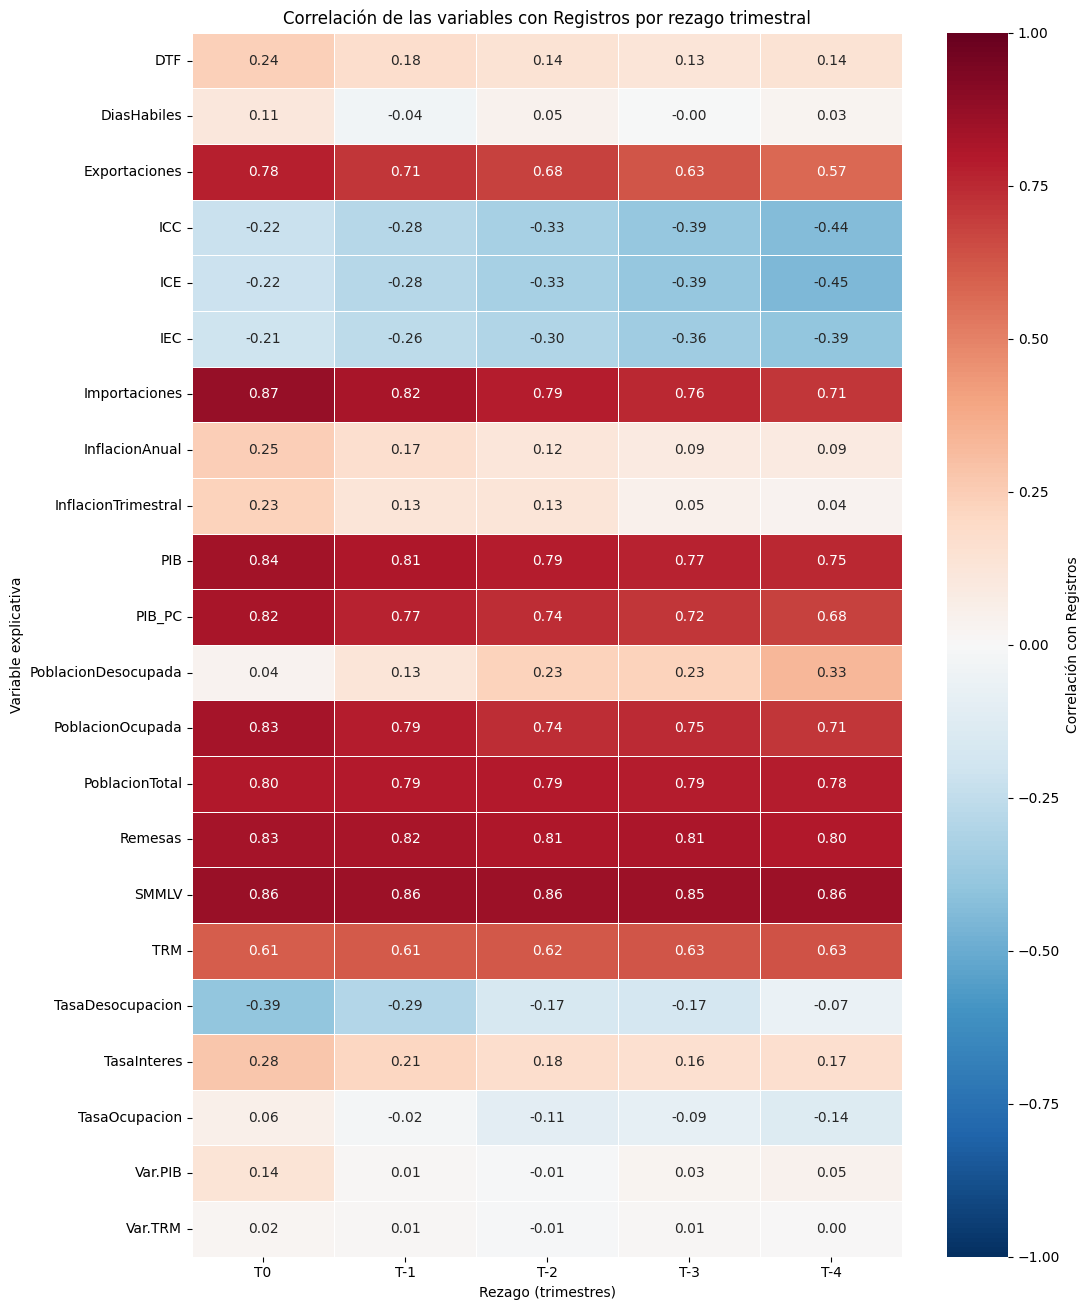

In [45]:
# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_trimestrales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4]
)

# Graficar
plt.figure(figsize=(11, max(5, len(mapa_rezagos) * 0.6)))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables con Registros por rezago trimestral")
plt.xlabel("Rezago (trimestres)")
plt.ylabel("Variable explicativa")
plt.xticks(
    ticks=[i + 0.5 for i in range(5)],
    labels=["T0", "T-1", "T-2", "T-3", "T-4"],
    rotation=0
)

plt.tight_layout()
plt.show()

La gráfica presenta el mismo análisis para las variables trimestrales con rezagos de 0 a 4 trimestres. Todas las variables en niveles conservan correlaciones altas, aunque decrecientes con el rezago: las importaciones pasan de 0,87 a 0,71, el PIB de 0,84 a 0,75, el PIB per cápita de 0,82 a 0,68 y las exportaciones de 0,78 a 0,57. Las remesas son la variable más estable, con correlaciones entre 0,83 y 0,80 en todos los rezagos, lo que las convierte en una candidata robusta para un modelo con predictoras rezagadas. La variación del PIB no muestra relación en ningún rezago.

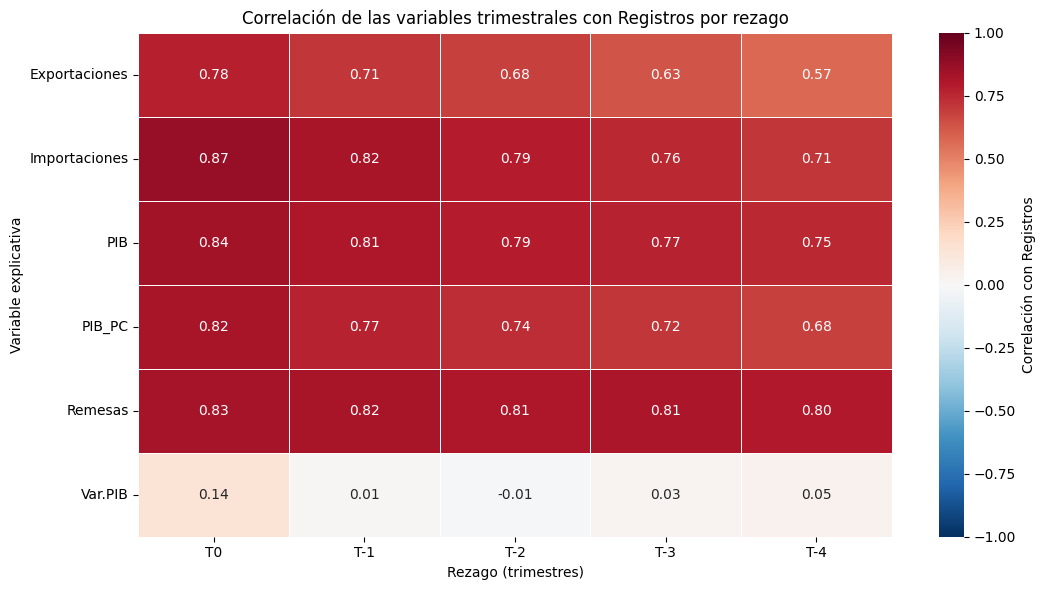

In [46]:
# Ordenar por fecha
df_datamercado = df_datamarket_trim.sort_values("FechaFin").copy()

# Seleccionar únicamente las variables trimestrales explicativas
variables_explicativas = variables_trimestrales

# Evaluar rezagos trimestrales
rezagos = [0, 1, 2, 3, 4]

resultados = []

for variable in variables_explicativas:
    for rezago in rezagos:

        correlacion = df_datamercado["Registros"].corr(
            df_datamercado[variable].shift(rezago)
        )

        resultados.append({
            "Variable": variable,
            "Rezago_trimestrales": rezago,
            "Correlacion": correlacion
        })

tabla_rezagos = pd.DataFrame(resultados)

# Mostrar resultados ordenados por correlación absoluta
#print(
#    tabla_rezagos.sort_values(
#       "Correlacion",
#       key=lambda x: x.abs(),
#        ascending=False
#    ).to_string(index=False)
#)

# Organizar los resultados en una matriz
mapa_rezagos = tabla_rezagos.pivot(
    index="Variable",
    columns="Rezago_trimestrales",
    values="Correlacion"
)

# Ordenar columnas de 0 a 4 trimestres
mapa_rezagos = mapa_rezagos.reindex(
    columns=[0, 1, 2, 3, 4]
)

# Graficar
plt.figure(figsize=(11, 6))

sns.heatmap(
    mapa_rezagos,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Correlación con Registros"}
)

plt.title("Correlación de las variables trimestrales con Registros por rezago")
plt.xlabel("Rezago (trimestres)")
plt.ylabel("Variable explicativa")

plt.xticks(
    ticks=[i + 0.5 for i in range(5)],
    labels=["T0", "T-1", "T-2", "T-3", "T-4"],
    rotation=0
)

plt.tight_layout()
plt.show()


El análisis exploratorio permite concluir que:

•	La serie de registros es no estacionaria, con tendencia creciente, estacionalidad moderada (picos en julio y diciembre) y choques atípicos en 2009 y 2020 que deberán controlarse con variables indicadoras.

•	Las variables con mayor relación con el mercado son el SMMLV, la población total y ocupada y la TRM en el dataset mensual, y las importaciones, el PIB y las remesas en el dataset trimestral.

•	Existe alta multicolinealidad entre predictoras, que exige seleccionar un representante por grupo; y parte de las correlaciones observadas puede deberse a la tendencia común de las series.


##Preparación de los Datos

Se combinan los dos datasets mensual y trimestral expandiendo las variables trimestrales a nivel de mes, repitiendo su valor.

In [48]:
# Variables trimestrales que se replicarán
variables_trimestrales = [
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "Remesas",
    "PIB_PC"
]

# Crear una copia del dataset trimestral
trim_expandido = df_datamarket_trim[
    ["FechaInicio", "FechaFin"] + variables_trimestrales
].copy()

# Generar los tres meses de cada trimestre
trim_expandido["Fecha"] = trim_expandido.apply(
    lambda fila: pd.date_range(
        start=fila["FechaInicio"],
        end=fila["FechaFin"],
        freq="MS"          # Inicio de cada mes
    ),
    axis=1
)

# Expandir una fila por cada mes
trim_expandido = trim_expandido.explode("Fecha")

# Conservar solo la fecha mensual y las variables trimestrales
trim_expandido = trim_expandido[
    ["Fecha"] + variables_trimestrales
].reset_index(drop=True)

# Unir con el dataset mensual
df_datamarket = df_datamarket_men.merge(
    trim_expandido,
    on="Fecha",
    how="left"
)

In [49]:
df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,SMMLV,ICC,IEC,ICE,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,426000,0.193,0.266,0.083,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,426000,0.139,0.189,0.065,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,426000,0.096,0.128,0.048,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,426000,0.133,0.169,0.080,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,426000,0.141,0.147,0.130,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879


In [50]:
# Exportaciones per cápita (pesos por persona)
df_datamarket["Exportaciones_PC"] = (
    (df_datamarket["Exportaciones"] * 100000) /
    (df_datamarket["PoblacionTotal"] * 1000)
)

# Importaciones per cápita (pesos por persona)
df_datamarket["Importaciones_PC"] = (
    (df_datamarket["Importaciones"] * 100000) /
    (df_datamarket["PoblacionTotal"] * 1000)
)


In [51]:
# Registros por cada 100 habitantes
df_datamarket["Registros_PC"] = (
    df_datamarket["Registros"] /
    (df_datamarket["PoblacionTotal"] * 1000)
) * 100

df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,ICE,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,0.083,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.913973,46.298781,0.028934
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,0.065,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.862633,46.253859,0.031079
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,0.048,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.815993,46.213049,0.034139
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,0.080,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879,55.267494,48.713631,0.033559
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,0.130,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879,55.214364,48.666801,0.037658


Dado que el salario mínimo va creciendo por la inflación, el objetivo es poder mostrarlo en términos que signifiquen poder adquisitivo. Para esto se hará uso del IPC para calcular el salario real con base en el salario nominal.

In [52]:
#Dataset Mensual
df_IPC = pd.read_excel("Data - Mercado.xlsx", sheet_name="IPC")

In [53]:
# Preparar dataset IPC
df_IPC["Fecha"] = pd.to_datetime(df_IPC["Fecha"])
df_datamarket["Fecha"] = pd.to_datetime(df_datamarket["Fecha"])

# Unir IPC al dataset principal
df_datamarket = df_datamarket.merge(
    df_IPC[["Fecha", "IPC"]],
    on="Fecha",
    how="left"
)
df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,PIB,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC,IPC
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.913973,46.298781,0.028934,56.45
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.862633,46.253859,0.031079,57.02
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,126088.657004,NaN,21334.353184,18667.177575,731.13,312.433757,52.815993,46.213049,0.034139,57.46
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879,55.267494,48.713631,0.033559,57.72
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,128906.474678,0.022348,22346.501950,19696.555294,803.26,318.501879,55.214364,48.666801,0.037658,57.95


In [54]:
# Salario mostrando poder adquisitivo
df_datamarket["SMMLV_PA"] = (
    df_datamarket["SMMLV"] /
    (df_datamarket["IPC"])
) * 100

df_datamarket.head()

,Fecha,Registros,PoblacionTotal,PoblacionOcupada,PoblacionDesocupada,TasaOcupacion,TasaDesocupacion,TRM,Var.TRM,TasaInteres,...,Var.PIB,Exportaciones,Importaciones,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC,IPC,SMMLV_PA
0,2005-01-01,11666,40318.940,16059.539,2455.597,0.569725,0.132626,2362.96,NaN,0.065,...,NaN,21334.353184,18667.177575,731.13,312.433757,52.913973,46.298781,0.028934,56.45,754650.132861
1,2005-02-01,12543,40358.098,16023.387,2629.476,0.567561,0.140969,2340.49,-0.009509,0.065,...,NaN,21334.353184,18667.177575,731.13,312.433757,52.862633,46.253859,0.031079,57.02,747106.278499
2,2005-03-01,13790,40393.737,16168.666,2406.260,0.571899,0.129543,2353.71,0.005648,0.065,...,NaN,21334.353184,18667.177575,731.13,312.433757,52.815993,46.213049,0.034139,57.46,741385.311521
3,2005-04-01,13569,40433.355,16346.018,2233.329,0.577268,0.120205,2350.01,-0.001572,0.065,...,0.022348,22346.501950,19696.555294,803.26,318.501879,55.267494,48.713631,0.033559,57.72,738045.738046
4,2005-05-01,15241,40472.262,16375.551,2337.372,0.577425,0.124907,2339.22,-0.004591,0.065,...,0.022348,22346.501950,19696.555294,803.26,318.501879,55.214364,48.666801,0.037658,57.95,735116.479724


In [55]:
# Columnas a eliminar
columnas_eliminar = [
    "Registros",
    "PIB",
    "Exportaciones",
    "Importaciones",
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "DTF",
    "SMMLV"
]

# Eliminar columnas
df_datamarket = df_datamarket.drop(columns=columnas_eliminar)

# Verificar resultado
display(df_datamarket.head())

,Fecha,TasaDesocupacion,TRM,Var.TRM,TasaInteres,InflacionAnual,InflacionMensual,DiasHabiles,ICC,IEC,ICE,Var.PIB,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC,IPC,SMMLV_PA
0,2005-01-01,0.132626,2362.96,NaN,0.065,0.0543,0.0082,24,0.193,0.266,0.083,NaN,731.13,312.433757,52.913973,46.298781,0.028934,56.45,754650.132861
1,2005-02-01,0.140969,2340.49,-0.009509,0.065,0.0525,0.0102,24,0.139,0.189,0.065,NaN,731.13,312.433757,52.862633,46.253859,0.031079,57.02,747106.278499
2,2005-03-01,0.129543,2353.71,0.005648,0.065,0.0503,0.0077,24,0.096,0.128,0.048,NaN,731.13,312.433757,52.815993,46.213049,0.034139,57.46,741385.311521
3,2005-04-01,0.120205,2350.01,-0.001572,0.065,0.0501,0.0044,26,0.133,0.169,0.080,0.022348,803.26,318.501879,55.267494,48.713631,0.033559,57.72,738045.738046
4,2005-05-01,0.124907,2339.22,-0.004591,0.065,0.0504,0.0041,24,0.141,0.147,0.130,0.022348,803.26,318.501879,55.214364,48.666801,0.037658,57.95,735116.479724


Se crean dos variables para señalar los periodos que presentan atipicos.

In [56]:
#Dataset Mensual
df_atipicos = pd.read_excel("Data - Mercado.xlsx", sheet_name="Atipicos")

In [57]:
# Preparar dataset IPC
df_atipicos["Fecha"] = pd.to_datetime(df_atipicos["Fecha"])
df_datamarket["Fecha"] = pd.to_datetime(df_datamarket["Fecha"])

# Unir IPC al dataset principal
df_datamarket = df_datamarket.merge(
    df_atipicos[["Fecha", "COVID", "DificultadesRUNT"]],
    on="Fecha",
    how="left"
)
df_datamarket.head()

,Fecha,TasaDesocupacion,TRM,Var.TRM,TasaInteres,InflacionAnual,InflacionMensual,DiasHabiles,ICC,IEC,...,Var.PIB,Remesas,PIB_PC,Exportaciones_PC,Importaciones_PC,Registros_PC,IPC,SMMLV_PA,COVID,DificultadesRUNT
0,2005-01-01,0.132626,2362.96,NaN,0.065,0.0543,0.0082,24,0.193,0.266,...,NaN,731.13,312.433757,52.913973,46.298781,0.028934,56.45,754650.132861,0,0
1,2005-02-01,0.140969,2340.49,-0.009509,0.065,0.0525,0.0102,24,0.139,0.189,...,NaN,731.13,312.433757,52.862633,46.253859,0.031079,57.02,747106.278499,0,0
2,2005-03-01,0.129543,2353.71,0.005648,0.065,0.0503,0.0077,24,0.096,0.128,...,NaN,731.13,312.433757,52.815993,46.213049,0.034139,57.46,741385.311521,0,0
3,2005-04-01,0.120205,2350.01,-0.001572,0.065,0.0501,0.0044,26,0.133,0.169,...,0.022348,803.26,318.501879,55.267494,48.713631,0.033559,57.72,738045.738046,0,0
4,2005-05-01,0.124907,2339.22,-0.004591,0.065,0.0504,0.0041,24,0.141,0.147,...,0.022348,803.26,318.501879,55.214364,48.666801,0.037658,57.95,735116.479724,0,0


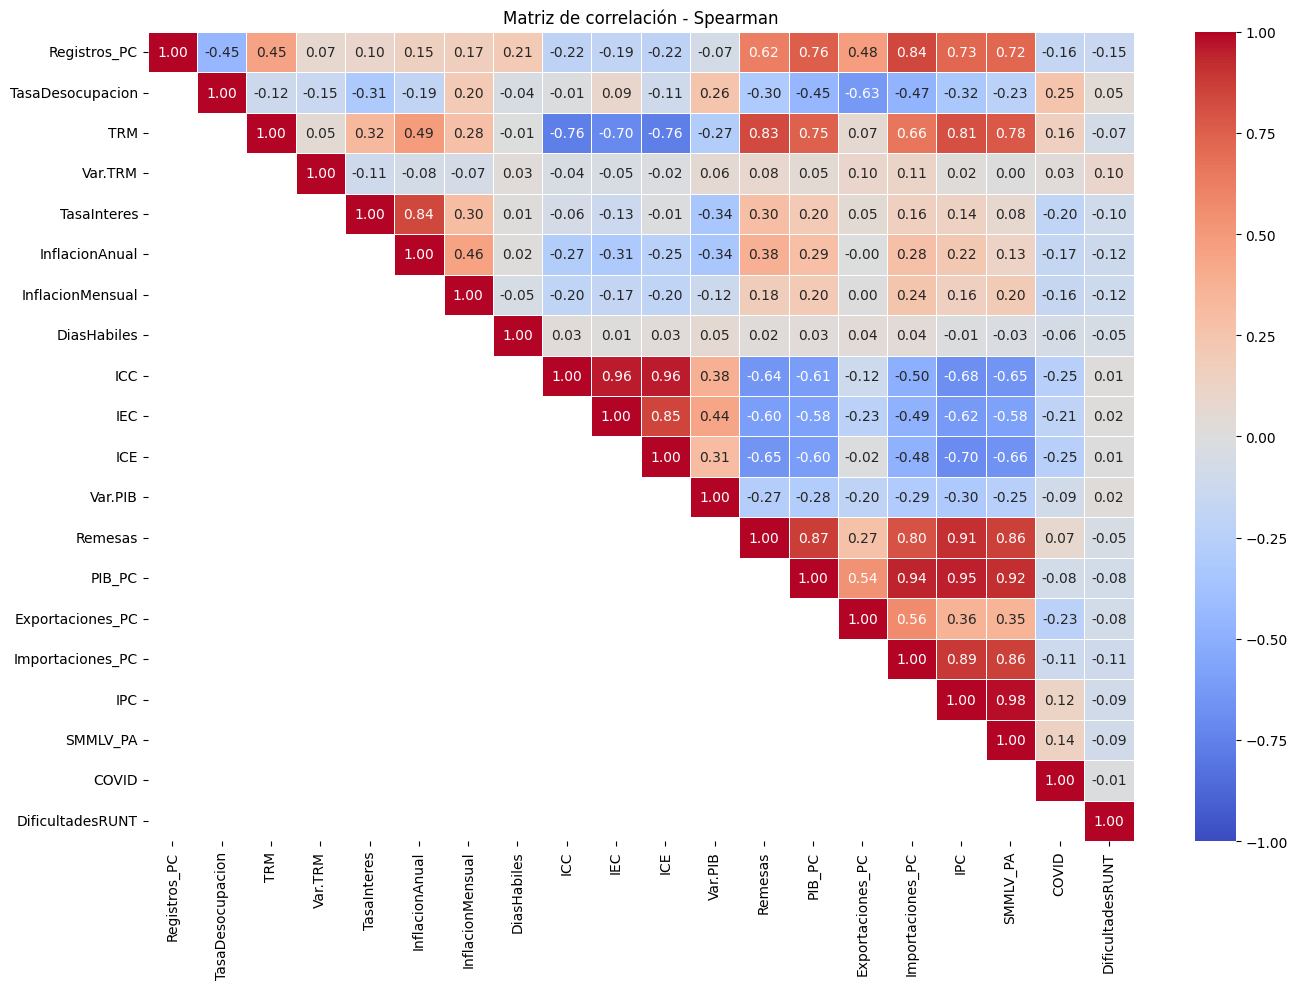

In [58]:
# Seleccionar variables numéricas
variables = df_datamarket.select_dtypes(include="number")

# Calcular matriz de correlación de Pearson
matriz_corr = variables.corr(method="spearman")

# Colocar Registros_PC de primero, conservando el orden de las demás
orden = ["Registros_PC"] + [
    col for col in matriz_corr.columns
    if col != "Registros_PC"
]

matriz_corr = matriz_corr.loc[orden, orden]

# Crear máscara para ocultar el triángulo inferior
mascara = np.tril(
    np.ones_like(matriz_corr, dtype=bool),
    k=-1
)

# Visualizar la matriz
plt.figure(figsize=(14, 10))

sns.heatmap(
    matriz_corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación - Spearman")
plt.tight_layout()
plt.show()

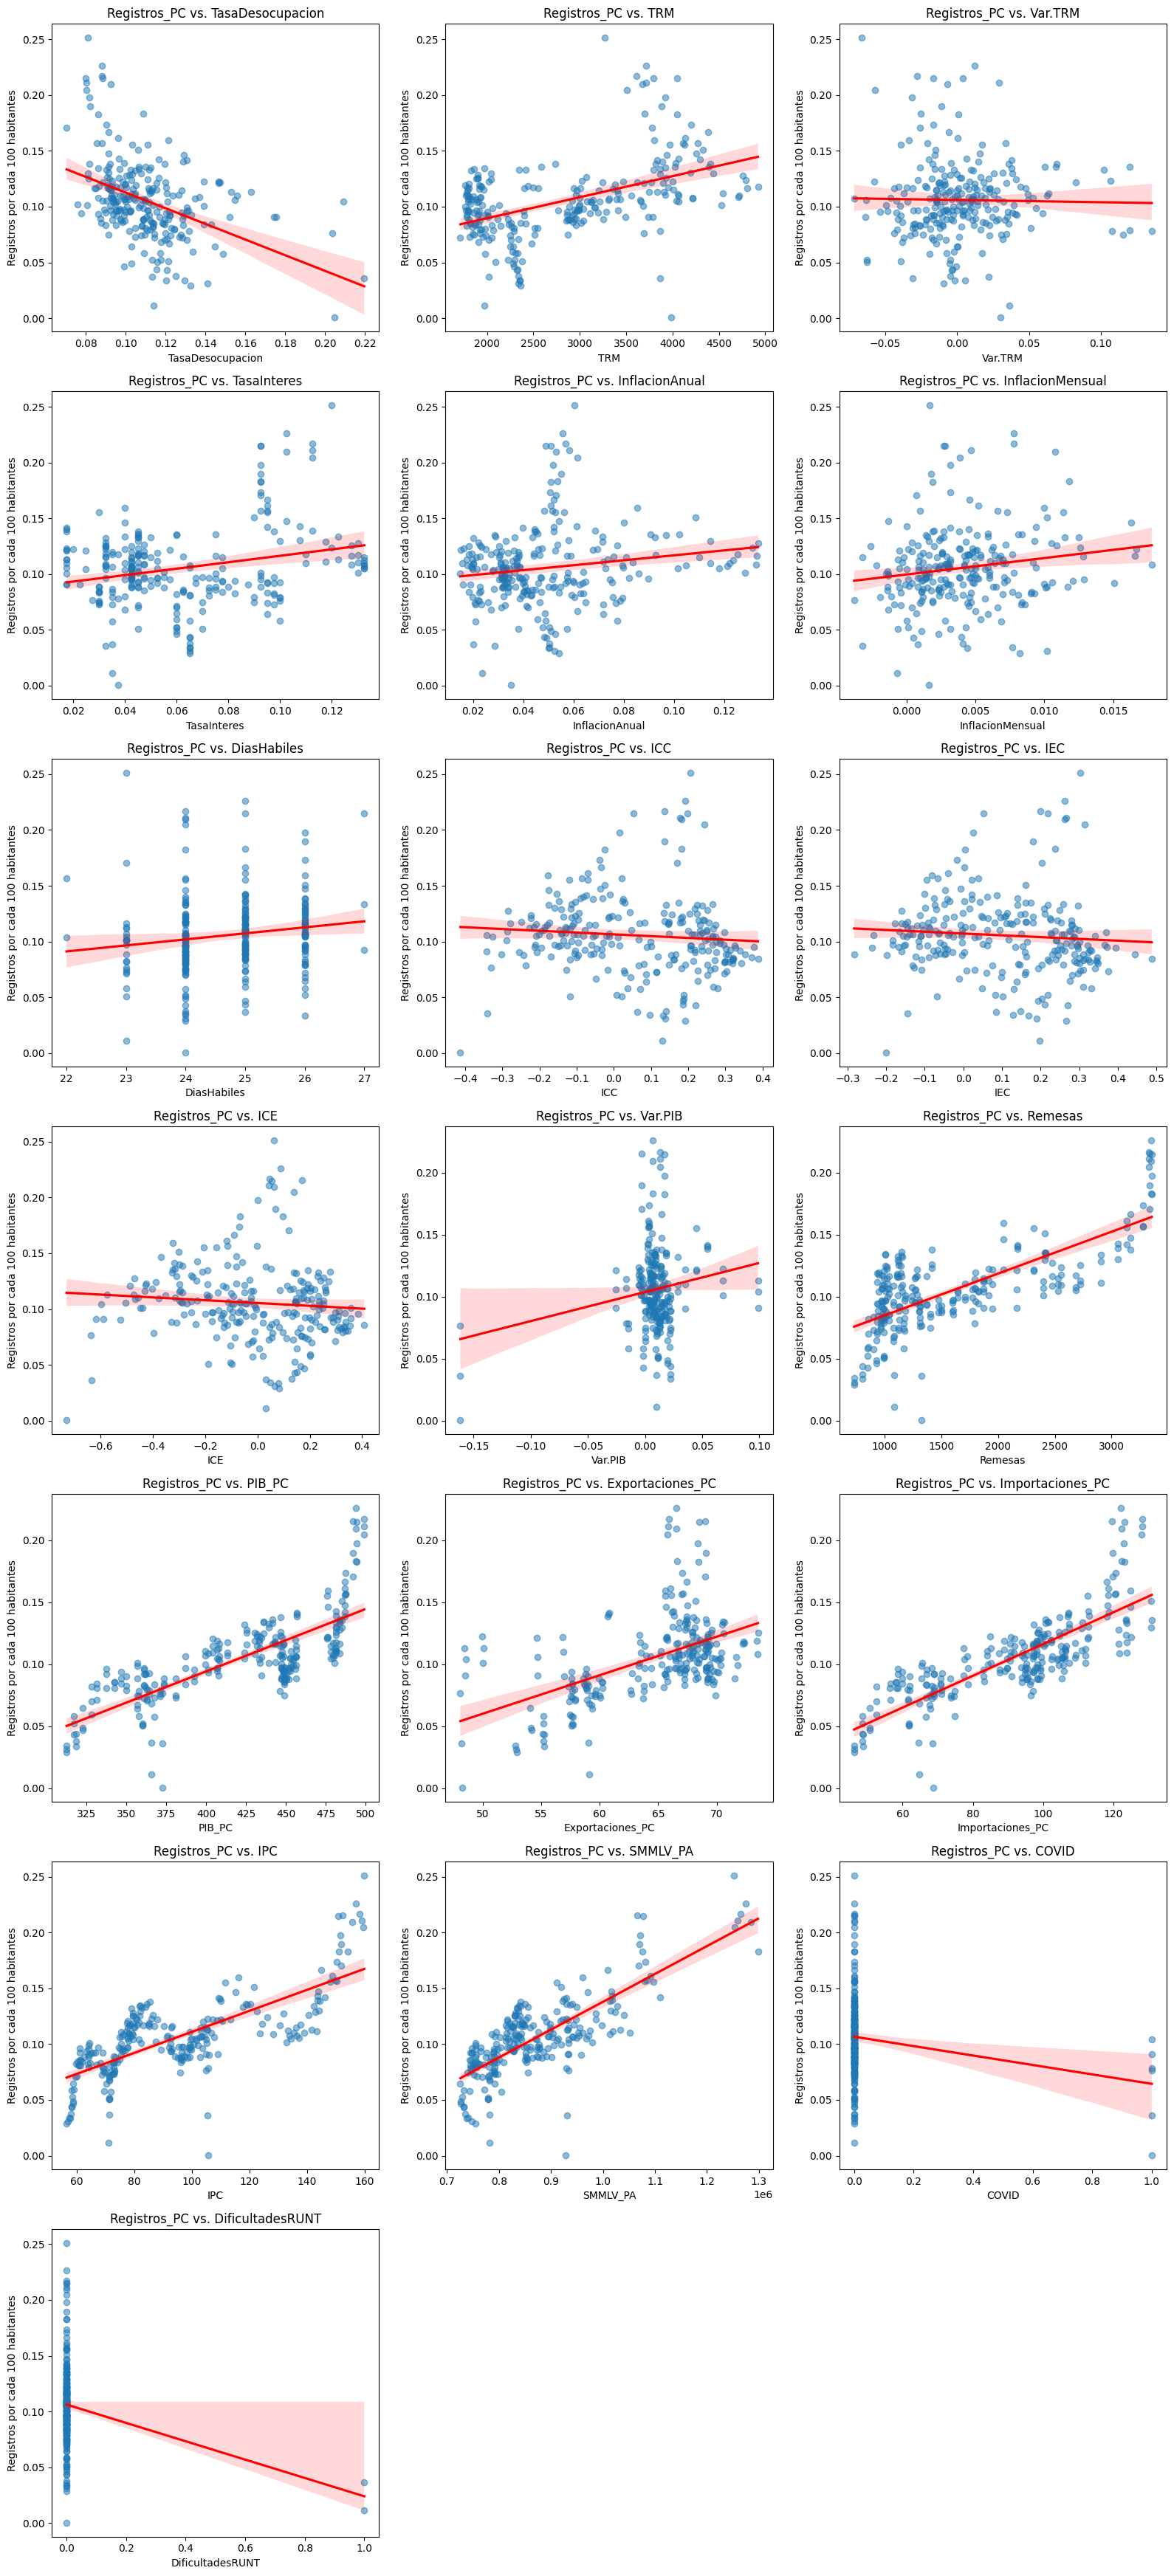

In [59]:
# Identificar variables numéricas, excluyendo fecha y variable objetivo
variables_graficos = [
    col for col in df_datamarket.select_dtypes(include="number").columns
    if col != "Registros_PC"
]

# Definir número de columnas y filas
ncols = 3
nrows = math.ceil(len(variables_graficos) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(16, 5 * nrows)
)

axes = np.array(axes).flatten()

# Generar gráficos de dispersión con línea de regresión
for i, col in enumerate(variables_graficos):

    temporal = df_datamarket[
        ["Registros_PC", col]
    ].dropna()

    sns.regplot(
        data=temporal,
        x=col,
        y="Registros_PC",
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"},
        ax=axes[i]
    )

    axes[i].set_title(f"Registros_PC vs. {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Registros por cada 100 habitantes")

# Eliminar espacios sobrantes
for j in range(len(variables_graficos), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

##Modelación

In [ ]:
# Copia del dataset mensual integrado
df = df_datamarket.copy()

df["Fecha"] = pd.to_datetime(df["Fecha"])
df = df.sort_values("Fecha").reset_index(drop=True)

objetivo = "Registros_PC"

# Variables macroeconómicas mensuales
variables_mensuales = [
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "InflacionAnual",
    "InflacionMensual",
    "ICC",
    "IEC",
    "ICE",
    "IPC",
    "SMMLV_PA"
]

# Variables trimestrales que ya están integradas a nivel mensual
variables_trimestrales = [
    "Var.PIB",
    "PIB_PC",
    "Remesas",
    "Exportaciones_PC",
    "Importaciones_PC"
]

# Crear rezagos de las variables mensuales
for variable in variables_mensuales:
    if variable in df.columns:
        df[f"{variable}_lag1"] = df[variable].shift(1)

# Crear rezagos de las variables trimestrales
for variable in variables_trimestrales:
    if variable in df.columns:
        df[f"{variable}_lag3"] = df[variable].shift(3)

# Rezagos de la variable objetivo
for rezago in [1, 3, 6, 12]:
    df[f"{objetivo}_lag{rezago}"] = df[objetivo].shift(rezago)

In [ ]:
def preparar_datos_horizonte(df, horizonte):

    datos = df.copy()

    # Valor de la variable objetivo en el mes futuro
    datos["y"] = datos[objetivo].shift(-horizonte)

    # Fecha correspondiente al valor que queremos pronosticar
    datos["Fecha_objetivo"] = datos["Fecha"].shift(-horizonte)

    # Variables macroeconómicas rezagadas
    columnas_features = []

    for variable in variables_mensuales:
        columna = f"{variable}_lag1"
        if columna in datos.columns:
            columnas_features.append(columna)

    for variable in variables_trimestrales:
        columna = f"{variable}_lag3"
        if columna in datos.columns:
            columnas_features.append(columna)

    # Rezagos de la variable objetivo
    columnas_features += [
        f"{objetivo}_lag{r}"
        for r in [1, 3, 6, 12]
    ]

    # Días hábiles del mes que se desea pronosticar
    datos["DiasHabiles_objetivo"] = (
        datos["DiasHabiles"].shift(-horizonte)
    )
    columnas_features.append("DiasHabiles_objetivo")

    # Estacionalidad del mes objetivo
    fecha_objetivo = datos["Fecha_objetivo"]
    mes_objetivo = fecha_objetivo.dt.month

    datos["Mes_sin"] = np.sin(
        2 * np.pi * mes_objetivo / 12
    )
    datos["Mes_cos"] = np.cos(
        2 * np.pi * mes_objetivo / 12
    )

    columnas_features += ["Mes_sin", "Mes_cos"]

    # Conservar variables, objetivo y fechas
    columnas = (
        columnas_features +
        ["y", "Fecha", "Fecha_objetivo"]
    )

    conjunto = datos[columnas].dropna().copy()

    X = conjunto[columnas_features]
    y = conjunto["y"]

    fechas_origen = conjunto["Fecha"]
    fechas_objetivo = conjunto["Fecha_objetivo"]

    return X, y, fechas_origen, fechas_objetivo

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

modelos = {
    "Regresión lineal": Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", LinearRegression())
    ]),

    "Árbol de regresión": DecisionTreeRegressor(
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    )
}

In [ ]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

resultados = []
predicciones_modelos = {}
modelos_entrenados = {}

for horizonte in [1, 3, 6, 12]:

    X, y, fechas_origen, fechas_objetivo = (
        preparar_datos_horizonte(df, horizonte)
    )

    # Punto de corte cronológico
    corte = int(len(X) * 0.80)

    # Separación entre entrenamiento y prueba
    # Se excluyen las observaciones cuyo objetivo futuro
    # todavía no sería conocido al iniciar la prueba.
    fin_train = corte - horizonte

    X_train = X.iloc[:fin_train]
    X_test = X.iloc[corte:]

    y_train = y.iloc[:fin_train]
    y_test = y.iloc[corte:]

    fechas_test = fechas_objetivo.iloc[corte:]
    origen_test = fechas_origen.iloc[corte:]

    predicciones_modelos[horizonte] = {}
    modelos_entrenados[horizonte] = {}

    for nombre, modelo in modelos.items():

        # Entrenamiento
        modelo.fit(X_train, y_train)

        # Predicción
        predicciones = modelo.predict(X_test)

        # Evaluación
        r2 = r2_score(y_test, predicciones)
        mape = mean_absolute_percentage_error(
            y_test, predicciones
        ) * 100

        mae = mean_absolute_error(
            y_test, predicciones
        )

        rmse = np.sqrt(
            mean_squared_error(y_test, predicciones)
        )

        resultados.append({
            "Horizonte": f"t+{horizonte}",
            "Modelo": nombre,
            "R2": r2,
            "MAPE (%)": mape,
            "MAE": mae,
            "RMSE": rmse
        })

        # Guardar predicciones y modelos
        predicciones_modelos[horizonte][nombre] = pd.DataFrame({
            "Fecha_origen": origen_test.values,
            "Fecha_objetivo": fechas_test.values,
            "Real": y_test.values,
            "Predicho": predicciones
        })

        modelos_entrenados[horizonte][nombre] = modelo


# Consolidar resultados
resultados_modelos = pd.DataFrame(resultados)

resultados_modelos = resultados_modelos.sort_values(
    ["Horizonte", "MAPE (%)"]
).reset_index(drop=True)

resultados_modelos.round(4)

,Horizonte,Modelo,R2,MAPE (%),MAE,RMSE
0,t+1,Árbol de regresión,-0.0649,18.3641,0.0302,0.0402
1,t+1,Regresión lineal,-0.2144,22.0534,0.0353,0.0430
2,t+12,Árbol de regresión,-2.6578,39.8308,0.0646,0.0767
3,t+12,Regresión lineal,-7.9828,68.9961,0.1083,0.1202
4,t+3,Regresión lineal,0.2779,17.1205,0.0273,0.0334
5,t+3,Árbol de regresión,-0.1177,22.8360,0.0344,0.0416
6,t+6,Regresión lineal,-2.6814,43.4205,0.0676,0.0755
7,t+6,Árbol de regresión,-4.1733,50.9193,0.0804,0.0895


In [ ]:
resultados_modelos.pivot(
    index="Horizonte",
    columns="Modelo",
    values="MAPE (%)"
).round(2)

Modelo,Regresión lineal,Árbol de regresión
Horizonte,,
t+1,22.05,18.36
t+12,69.00,39.83
t+3,17.12,22.84
t+6,43.42,50.92


In [ ]:
resultados_modelos.pivot(
    index="Horizonte",
    columns="Modelo",
    values="R2"
).round(3)

Modelo,Regresión lineal,Árbol de regresión
Horizonte,,
t+1,-0.214,-0.065
t+12,-7.983,-2.658
t+3,0.278,-0.118
t+6,-2.681,-4.173


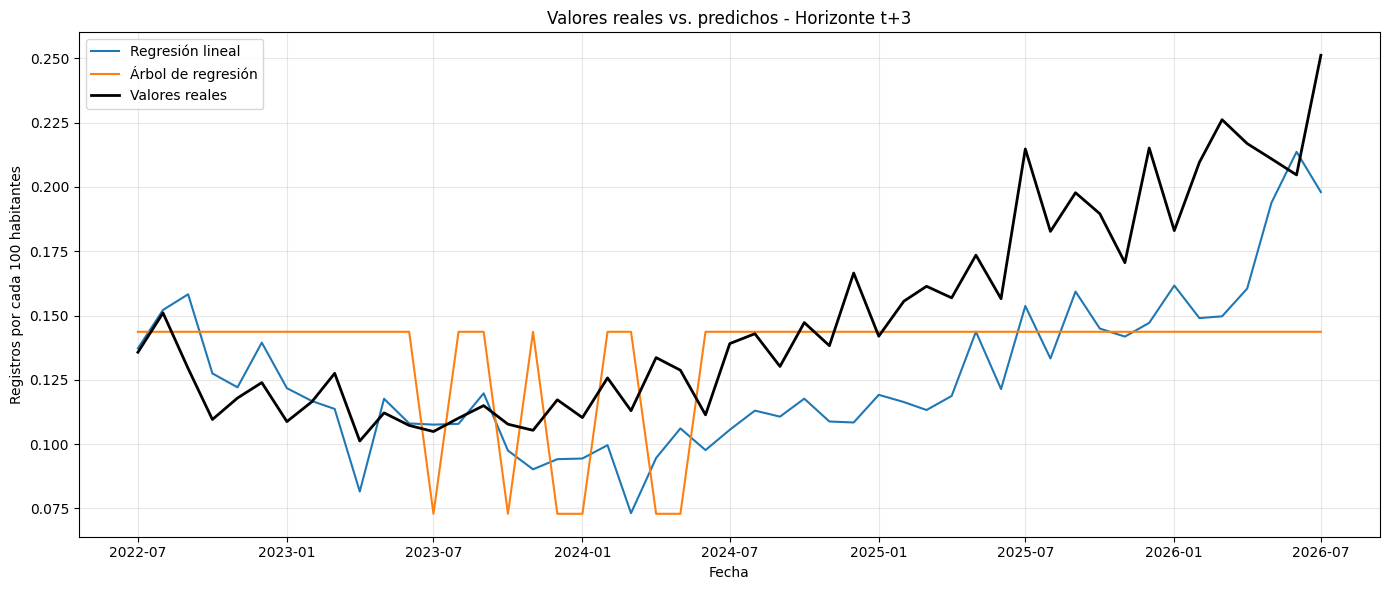

In [ ]:
import matplotlib.pyplot as plt

horizonte = 3

plt.figure(figsize=(14, 6))

for nombre, datos_pred in predicciones_modelos[horizonte].items():

    plt.plot(
        datos_pred["Fecha_objetivo"],
        datos_pred["Predicho"],
        label=nombre
    )

# Valores reales
datos_real = list(
    predicciones_modelos[horizonte].values()
)[0]

plt.plot(
    datos_real["Fecha_objetivo"],
    datos_real["Real"],
    label="Valores reales",
    color="black",
    linewidth=2
)

plt.title(
    f"Valores reales vs. predichos - Horizonte t+{horizonte}"
)

plt.xlabel("Fecha")
plt.ylabel("Registros por cada 100 habitantes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
horizonte = 3

arbol = modelos_entrenados[horizonte]["Árbol de regresión"]

importancia = pd.DataFrame({
    "Variable": arbol.feature_names_in_,
    "Importancia": arbol.feature_importances_
})

importancia = importancia.sort_values(
    "Importancia",
    ascending=False
)

importancia.head(15)

,Variable,Importancia
9,IPC_lag1,0.434204
12,PIB_PC_lag3,0.183026
11,Var.PIB_lag3,0.140858
3,TasaInteres_lag1,0.119549
19,Registros_PC_lag12,0.072919
20,DiasHabiles_objetivo,0.028171
7,IEC_lag1,0.011025
2,Var.TRM_lag1,0.007907
14,Exportaciones_PC_lag3,0.002341
6,ICC_lag1,0.000000


In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

resultados_cv = []
predicciones_cv = {}

n_splits = 5

for horizonte in [1, 3, 6, 12]:

    X, y, fechas_origen, fechas_objetivo = (
        preparar_datos_horizonte(df, horizonte)
    )

    # Validación cronológica con ventana expansiva
    tscv = TimeSeriesSplit(
        n_splits=n_splits,
        test_size=1,
        gap=horizonte
    )

    predicciones_cv[horizonte] = {}

    for nombre, modelo_base in modelos.items():

        resultados_folds = []
        predicciones_folds = []

        for fold, (train_idx, test_idx) in enumerate(
            tscv.split(X), start=1
        ):

            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]

            y_train = y.iloc[train_idx]
            y_test = y.iloc[test_idx]

            # Entrenar modelo
            modelo = clone(modelo_base)
            modelo.fit(X_train, y_train)

            # Predecir
            pred = modelo.predict(X_test)

            # Métricas de cada partición
            resultados_folds.append({
                "R2": r2_score(y_test, pred),
                "MAPE": mean_absolute_percentage_error(
                    y_test, pred
                ) * 100,
                "MAE": mean_absolute_error(y_test, pred),
                "RMSE": np.sqrt(
                    mean_squared_error(y_test, pred)
                )
            })

            predicciones_folds.append(pd.DataFrame({
                "Fold": fold,
                "Fecha_origen": fechas_origen.iloc[test_idx].values,
                "Fecha_objetivo": fechas_objetivo.iloc[test_idx].values,
                "Real": y_test.values,
                "Predicho": pred
            }))

        # Consolidar predicciones de los folds
        predicciones_cv[horizonte][nombre] = pd.concat(
            predicciones_folds,
            ignore_index=True
        )

        # Métricas globales sobre todas las predicciones
        predicciones_totales = predicciones_cv[horizonte][nombre]

        resultados_cv.append({
            "Horizonte": f"t+{horizonte}",
            "Modelo": nombre,
            "R2": r2_score(
                predicciones_totales["Real"],
                predicciones_totales["Predicho"]
            ),
            "MAPE (%)": mean_absolute_percentage_error(
                predicciones_totales["Real"],
                predicciones_totales["Predicho"]
            ) * 100,
            "MAE": mean_absolute_error(
                predicciones_totales["Real"],
                predicciones_totales["Predicho"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    predicciones_totales["Real"],
                    predicciones_totales["Predicho"]
                )
            )
        })

resultados_cv = pd.DataFrame(resultados_cv)

resultados_cv.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, Unde

,Horizonte,Modelo,R2,MAPE (%),MAE,RMSE
0,t+1,Regresión lineal,-0.4411,7.3519,0.0167,0.0195
1,t+1,Árbol de regresión,-3.2251,13.7335,0.0306,0.0334
2,t+3,Regresión lineal,-1.8922,10.0455,0.0216,0.0276
3,t+3,Árbol de regresión,-3.9508,14.4249,0.0326,0.0361
4,t+6,Regresión lineal,-0.3232,6.2421,0.0142,0.0187
5,t+6,Árbol de regresión,-4.3603,14.8961,0.0340,0.0376
6,t+12,Regresión lineal,-9.5953,21.7245,0.0493,0.0529
7,t+12,Árbol de regresión,-46.3647,49.5747,0.1106,0.1118


In [ ]:
tabla_mape = resultados_cv.pivot(
    index="Horizonte",
    columns="Modelo",
    values="MAPE (%)"
)

tabla_r2 = resultados_cv.pivot(
    index="Horizonte",
    columns="Modelo",
    values="R2"
)

print("MAPE (%)")
display(tabla_mape.round(2))

print("R²")
display(tabla_r2.round(3))

MAPE (%)


Modelo,Regresión lineal,Árbol de regresión
Horizonte,,
t+1,7.35,13.73
t+12,21.72,49.57
t+3,10.05,14.42
t+6,6.24,14.90


R²


Modelo,Regresión lineal,Árbol de regresión
Horizonte,,
t+1,-0.441,-3.225
t+12,-9.595,-46.365
t+3,-1.892,-3.951
t+6,-0.323,-4.360


In [ ]:
# Preparar serie mensual
df_estadistico = df_datamarket[
    ["Fecha", "Registros_PC", "DiasHabiles"]
].copy()

df_estadistico["Fecha"] = pd.to_datetime(
    df_estadistico["Fecha"]
)

df_estadistico = (
    df_estadistico
    .sort_values("Fecha")
    .set_index("Fecha")
)

# Frecuencia mensual
df_estadistico = df_estadistico.asfreq("MS")

# Verificar valores faltantes
print(df_estadistico.isna().sum())

y = df_estadistico["Registros_PC"]

Registros_PC    0
DiasHabiles     0
dtype: int64


In [ ]:
def obtener_origenes(y, horizonte, n_splits=5, min_train=60):

    ultimo_origen = len(y) - horizonte - 1

    origenes = np.linspace(
        min_train - 1,
        ultimo_origen,
        n_splits,
        dtype=int
    )

    return np.unique(origenes)

ARIMA

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

resultados_estadisticos = []
predicciones_estadisticas = {}

for horizonte in [1, 3, 6, 12]:

    origenes = obtener_origenes(
        y,
        horizonte,
        n_splits=5,
        min_train=60
    )

    predicciones = []

    for fold, origen in enumerate(origenes, start=1):

        # Información disponible hasta el origen
        y_train = y.iloc[:origen + 1]

        # Fecha que queremos pronosticar
        fecha_objetivo = y.index[origen + horizonte]

        # Entrenar ARIMA
        modelo = ARIMA(
            y_train,
            order=(1, 1, 1)
        )

        modelo_ajustado = modelo.fit()

        # Pronóstico de varios pasos
        forecast = modelo_ajustado.forecast(
            steps=horizonte
        )

        valor_predicho = forecast.iloc[-1]
        valor_real = y.iloc[origen + horizonte]

        predicciones.append({
            "Fold": fold,
            "Fecha_origen": y.index[origen],
            "Fecha_objetivo": fecha_objetivo,
            "Real": valor_real,
            "Predicho": valor_predicho
        })

    predicciones = pd.DataFrame(predicciones)

    predicciones_estadisticas[
        (horizonte, "ARIMA")
    ] = predicciones

    resultados_estadisticos.append({
        "Horizonte": f"t+{horizonte}",
        "Modelo": "ARIMA",
        "R2": r2_score(
            predicciones["Real"],
            predicciones["Predicho"]
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            predicciones["Real"],
            predicciones["Predicho"]
        ) * 100,
        "MAE": mean_absolute_error(
            predicciones["Real"],
            predicciones["Predicho"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                predicciones["Real"],
                predicciones["Predicho"]
            )
        )
    })

SARIMAX

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

for horizonte in [1, 3, 6, 12]:

    origenes = obtener_origenes(
        y,
        horizonte,
        n_splits=5,
        min_train=60
    )

    predicciones = []

    for fold, origen in enumerate(origenes, start=1):

        # Variable objetivo de entrenamiento
        y_train = y.iloc[:origen + 1]

        # Variable exógena histórica
        X_train = df_estadistico[
            ["DiasHabiles"]
        ].iloc[:origen + 1]

        # Días hábiles futuros conocidos
        X_future = df_estadistico[
            ["DiasHabiles"]
        ].iloc[origen + 1:origen + horizonte + 1]

        # Entrenar SARIMAX
        modelo = SARIMAX(
            y_train,
            exog=X_train,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        modelo_ajustado = modelo.fit(disp=False)

        # Pronosticar el horizonte completo
        forecast = modelo_ajustado.get_forecast(
            steps=horizonte,
            exog=X_future
        )

        valor_predicho = forecast.predicted_mean.iloc[-1]
        valor_real = y.iloc[origen + horizonte]

        predicciones.append({
            "Fold": fold,
            "Fecha_origen": y.index[origen],
            "Fecha_objetivo": y.index[origen + horizonte],
            "Real": valor_real,
            "Predicho": valor_predicho
        })

    predicciones = pd.DataFrame(predicciones)

    predicciones_estadisticas[
        (horizonte, "SARIMAX")
    ] = predicciones

    resultados_estadisticos.append({
        "Horizonte": f"t+{horizonte}",
        "Modelo": "SARIMAX",
        "R2": r2_score(
            predicciones["Real"],
            predicciones["Predicho"]
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            predicciones["Real"],
            predicciones["Predicho"]
        ) * 100,
        "MAE": mean_absolute_error(
            predicciones["Real"],
            predicciones["Predicho"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                predicciones["Real"],
                predicciones["Predicho"]
            )
        )
    })

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local

In [ ]:
pip install prophet

In [ ]:
from prophet import Prophet

# Preparar datos para Prophet
df_prophet = df_estadistico.reset_index()[
    ["Fecha", "Registros_PC"]
].copy()

df_prophet = df_prophet.rename(columns={
    "Fecha": "ds",
    "Registros_PC": "y"
})

In [ ]:
for horizonte in [1, 3, 6, 12]:

    origenes = obtener_origenes(
        y,
        horizonte,
        n_splits=5,
        min_train=60
    )

    predicciones = []

    for fold, origen in enumerate(origenes, start=1):

        # Datos históricos disponibles
        train = df_prophet.iloc[:origen + 1].copy()

        # Entrenar Prophet
        modelo = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            seasonality_mode="additive"
        )

        modelo.fit(train)

        # Crear fechas futuras
        fechas_futuras = pd.DataFrame({
            "ds": pd.date_range(
                start=train["ds"].iloc[-1],
                periods=horizonte + 1,
                freq="MS"
            )[1:]
        })

        # Pronóstico
        forecast = modelo.predict(fechas_futuras)

        valor_predicho = forecast["yhat"].iloc[-1]
        valor_real = y.iloc[origen + horizonte]

        predicciones.append({
            "Fold": fold,
            "Fecha_origen": y.index[origen],
            "Fecha_objetivo": y.index[origen + horizonte],
            "Real": valor_real,
            "Predicho": valor_predicho
        })

    predicciones = pd.DataFrame(predicciones)

    predicciones_estadisticas[
        (horizonte, "Prophet")
    ] = predicciones

    resultados_estadisticos.append({
        "Horizonte": f"t+{horizonte}",
        "Modelo": "Prophet",
        "R2": r2_score(
            predicciones["Real"],
            predicciones["Predicho"]
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            predicciones["Real"],
            predicciones["Predicho"]
        ) * 100,
        "MAE": mean_absolute_error(
            predicciones["Real"],
            predicciones["Predicho"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                predicciones["Real"],
                predicciones["Predicho"]
            )
        )
    })

In [ ]:
resultados_estadisticos = pd.DataFrame(
    resultados_estadisticos
)

resultados_estadisticos = (
    resultados_estadisticos
    .sort_values(["Horizonte", "MAPE (%)"])
    .reset_index(drop=True)
)

resultados_estadisticos.round(4)

,Horizonte,Modelo,R2,MAPE (%),MAE,RMSE
0,t+1,ARIMA,0.8893,12.7069,0.0155,0.0216
1,t+1,SARIMAX,0.8675,15.8691,0.0163,0.0236
2,t+1,Prophet,0.7057,17.3130,0.0253,0.0352
3,t+12,Prophet,0.3222,20.4774,0.0350,0.0480
4,t+12,ARIMA,0.5368,22.5710,0.0316,0.0397
5,t+12,SARIMAX,0.3720,26.3486,0.0315,0.0462
6,t+3,Prophet,0.6231,13.4182,0.0240,0.0368
7,t+3,ARIMA,0.7988,16.1782,0.0197,0.0269
8,t+3,SARIMAX,0.8135,16.4887,0.0186,0.0259
9,t+6,Prophet,0.5594,16.7517,0.0287,0.0420


In [ ]:
# Resultados de regresión lineal y árbol
# resultados_cv contiene los resultados de TimeSeriesSplit.

# Integrar ambas familias
comparacion_total = pd.concat(
    [
        resultados_cv,
        resultados_estadisticos
    ],
    ignore_index=True
)

comparacion_total.sort_values(
    ["Horizonte", "MAPE (%)"]
).round(4)

,Horizonte,Modelo,R2,MAPE (%),MAE,RMSE
0,t+1,Regresión lineal,-0.4411,7.3519,0.0167,0.0195
8,t+1,ARIMA,0.8893,12.7069,0.0155,0.0216
1,t+1,Árbol de regresión,-3.2251,13.7335,0.0306,0.0334
9,t+1,SARIMAX,0.8675,15.8691,0.0163,0.0236
10,t+1,Prophet,0.7057,17.3130,0.0253,0.0352
11,t+12,Prophet,0.3222,20.4774,0.0350,0.0480
6,t+12,Regresión lineal,-9.5953,21.7245,0.0493,0.0529
12,t+12,ARIMA,0.5368,22.5710,0.0316,0.0397
13,t+12,SARIMAX,0.3720,26.3486,0.0315,0.0462
7,t+12,Árbol de regresión,-46.3647,49.5747,0.1106,0.1118


In [ ]:
df_sarimax = df_datamarket.copy()

df_sarimax["Fecha"] = pd.to_datetime(
    df_sarimax["Fecha"]
)

df_sarimax = (
    df_sarimax
    .sort_values("Fecha")
    .set_index("Fecha")
    .asfreq("MS")
)

In [ ]:
# Variables macroeconómicas mensuales
variables_mensuales = [
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "InflacionAnual",
    "InflacionMensual",
    "ICC",
    "IEC",
    "ICE",
    "IPC",
    "SMMLV_PA"
]

# Variables trimestrales integradas al dataset mensual
variables_trimestrales = [
    "Var.PIB",
    "PIB_PC",
    "Remesas",
    "Exportaciones_PC",
    "Importaciones_PC"
]

In [ ]:
# Configuración de rezagos
rezagos_macro = {
    **{v: 1 for v in variables_mensuales},
    **{v: 3 for v in variables_trimestrales}
}

# Crear variables rezagadas
for variable, rezago in rezagos_macro.items():

    if variable in df_sarimax.columns:

        df_sarimax[f"{variable}_lag{rezago}"] = (
            df_sarimax[variable].shift(rezago)
        )

# Lista de variables exógenas rezagadas
variables_exogenas = [
    f"{variable}_lag{rezago}"
    for variable, rezago in rezagos_macro.items()
]

# Incorporar días hábiles sin rezago
variables_exogenas.append("DiasHabiles")

# Verificar columnas
print(variables_exogenas)

['TasaDesocupacion_lag1', 'TRM_lag1', 'Var.TRM_lag1', 'TasaInteres_lag1', 'InflacionAnual_lag1', 'InflacionMensual_lag1', 'ICC_lag1', 'IEC_lag1', 'ICE_lag1', 'IPC_lag1', 'SMMLV_PA_lag1', 'Var.PIB_lag3', 'PIB_PC_lag3', 'Remesas_lag3', 'Exportaciones_PC_lag3', 'Importaciones_PC_lag3', 'DiasHabiles']


In [ ]:
# Variable objetivo
objetivo = "Registros_PC"

# Dataset de modelación
datos_sarimax = df_sarimax[
    [objetivo] + variables_exogenas
].copy()

# Eliminar observaciones incompletas
datos_sarimax = datos_sarimax.dropna()

# Separar variable objetivo y exógenas
y_sarimax = datos_sarimax[objetivo]

X_sarimax = datos_sarimax[variables_exogenas]

print("Observaciones:", len(datos_sarimax))
print("Variables exógenas:", len(variables_exogenas))

display(datos_sarimax.head())

Observaciones: 253
Variables exógenas: 17


,Registros_PC,TasaDesocupacion_lag1,TRM_lag1,Var.TRM_lag1,TasaInteres_lag1,InflacionAnual_lag1,InflacionMensual_lag1,ICC_lag1,IEC_lag1,ICE_lag1,IPC_lag1,SMMLV_PA_lag1,Var.PIB_lag3,PIB_PC_lag3,Remesas_lag3,Exportaciones_PC_lag3,Importaciones_PC_lag3,DiasHabiles
Fecha,,,,,,,,,,,,,,,,,,
2005-07-01,0.043034,0.115427,2331.79,-0.003176,0.065,0.0483,0.0040,0.187,0.211,0.150,58.18,732210.381574,0.022348,318.501879,803.26,55.267494,48.713631,24
2005-08-01,0.058327,0.120484,2323.38,-0.003607,0.065,0.0491,0.0005,0.219,0.270,0.143,58.21,731833.018382,0.022348,318.501879,803.26,55.214364,48.666801,26
2005-09-01,0.052472,0.117188,2306.19,-0.007399,0.065,0.0488,0.0000,0.280,0.332,0.201,58.21,731833.018382,0.022348,318.501879,803.26,55.159336,48.618299,26
2005-10-01,0.046564,0.113333,2294.52,-0.005060,0.060,0.0502,0.0043,0.189,0.219,0.143,58.46,728703.386931,-0.001469,317.114632,851.47,55.281662,48.731371,25
2005-11-01,0.048768,0.098985,2292.55,-0.000859,0.060,0.0527,0.0023,0.187,0.193,0.178,58.60,726962.457338,-0.001469,317.114632,851.47,55.225796,48.682125,24


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

resultados_sarimax = []
predicciones_sarimax = {}

horizontes = [1, 3, 6, 12]

for horizonte in horizontes:

    origenes = obtener_origenes(
        y_sarimax,
        horizonte,
        n_splits=5,
        min_train=60
    )

    predicciones_folds = []

    for fold, origen in enumerate(origenes, start=1):

        # Datos disponibles hasta el origen
        y_train = y_sarimax.iloc[:origen + 1]

        X_train = X_sarimax.iloc[:origen + 1]

        # Variables futuras
        fechas_futuras = y_sarimax.index[
            origen + 1: origen + horizonte + 1
        ]

        # Última información macroeconómica disponible
        ultimo_valor_macro = X_train[
            variables_exogenas[:-1]
        ].iloc[-1]

        X_future = pd.DataFrame(
            index=fechas_futuras,
            columns=variables_exogenas
        )

        # Mantener constantes las variables macroeconómicas
        for variable in variables_exogenas[:-1]:

            X_future[variable] = ultimo_valor_macro[variable]

        # Días hábiles conocidos del período futuro
        X_future["DiasHabiles"] = (
            df_sarimax.loc[
                fechas_futuras, "DiasHabiles"
            ].values
        )

        # Entrenamiento SARIMAX
        modelo = SARIMAX(
            endog=y_train,
            exog=X_train,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        modelo_ajustado = modelo.fit(disp=False)

        # Pronóstico
        forecast = modelo_ajustado.get_forecast(
            steps=horizonte,
            exog=X_future
        )

        # Extraer pronóstico del horizonte correspondiente
        valor_predicho = forecast.predicted_mean.iloc[-1]

        valor_real = y_sarimax.iloc[origen + horizonte]

        predicciones_folds.append({
            "Fold": fold,
            "Fecha_origen": y_sarimax.index[origen],
            "Fecha_objetivo": y_sarimax.index[origen + horizonte],
            "Real": valor_real,
            "Predicho": valor_predicho
        })

    # Consolidar predicciones
    predicciones = pd.DataFrame(predicciones_folds)

    predicciones_sarimax[horizonte] = predicciones

    # Evaluación global
    resultados_sarimax.append({
        "Horizonte": f"t+{horizonte}",
        "Modelo": "SARIMAX con macroeconómicas",
        "R2": r2_score(
            predicciones["Real"],
            predicciones["Predicho"]
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            predicciones["Real"],
            predicciones["Predicho"]
        ) * 100,
        "MAE": mean_absolute_error(
            predicciones["Real"],
            predicciones["Predicho"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                predicciones["Real"],
                predicciones["Predicho"]
            )
        )
    })

# Consolidar resultados
resultados_sarimax = pd.DataFrame(resultados_sarimax)

resultados_sarimax.round(4)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local

,Horizonte,Modelo,R2,MAPE (%),MAE,RMSE
0,t+1,SARIMAX con macroeconómicas,0.8797,13.1482,0.0181,0.0204
1,t+3,SARIMAX con macroeconómicas,0.7392,17.4777,0.0204,0.0290
2,t+6,SARIMAX con macroeconómicas,0.3430,24.3489,0.0328,0.0472
3,t+12,SARIMAX con macroeconómicas,-0.9494,49.7453,0.0707,0.0793


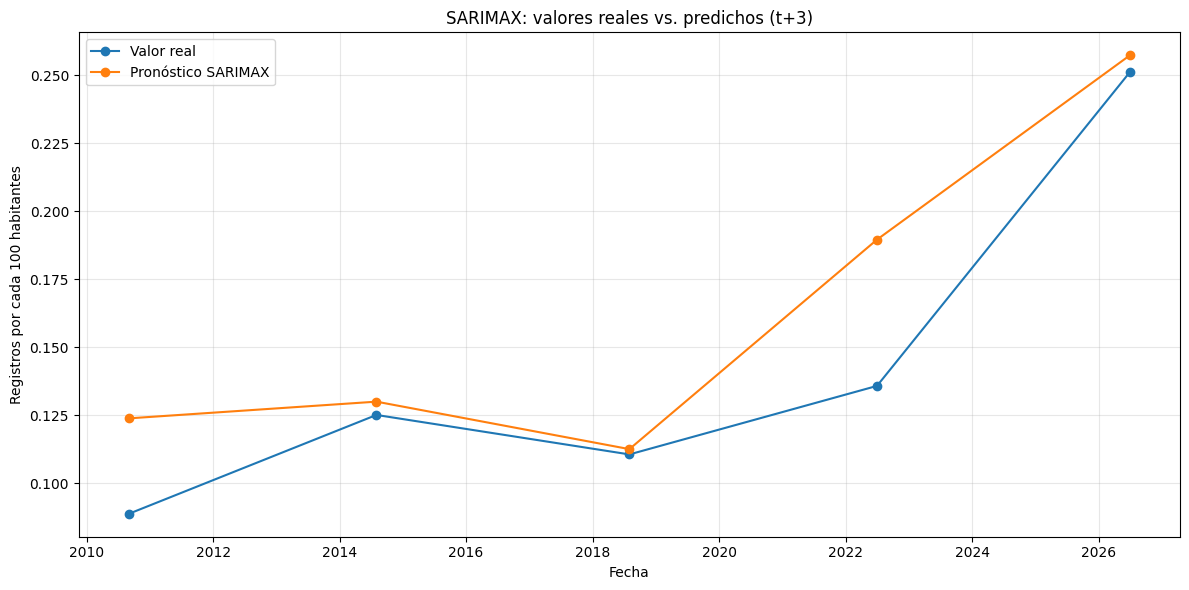

In [ ]:
horizonte = 3

datos_pred = predicciones_sarimax[horizonte]

plt.figure(figsize=(12, 6))

plt.plot(
    datos_pred["Fecha_objetivo"],
    datos_pred["Real"],
    marker="o",
    label="Valor real"
)

plt.plot(
    datos_pred["Fecha_objetivo"],
    datos_pred["Predicho"],
    marker="o",
    label="Pronóstico SARIMAX"
)

plt.title("SARIMAX: valores reales vs. predichos (t+3)")
plt.xlabel("Fecha")
plt.ylabel("Registros por cada 100 habitantes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Prophet con macroeconomicas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Copiar y organizar la base
df_prophet = df_datamarket.copy()

df_prophet["Fecha"] = pd.to_datetime(df_prophet["Fecha"])

df_prophet = (
    df_prophet
    .sort_values("Fecha")
    .reset_index(drop=True)
)

In [ ]:
variables_mensuales = [
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "InflacionAnual",
    "InflacionMensual",
    "ICC",
    "IEC",
    "ICE",
    "IPC",
    "SMMLV_PA"
]

variables_trimestrales = [
    "Var.PIB",
    "PIB_PC",
    "Remesas",
    "Exportaciones_PC",
    "Importaciones_PC"
]

rezagos_macro = {
    **{v: 1 for v in variables_mensuales},
    **{v: 3 for v in variables_trimestrales}
}

In [ ]:
from prophet import Prophet
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Preparar datos
df_prophet = df_datamarket.copy()

df_prophet["Fecha"] = pd.to_datetime(df_prophet["Fecha"])
df_prophet = df_prophet.sort_values("Fecha")

# Crear variables rezagadas
for variable, rezago in rezagos_macro.items():
    df_prophet[f"{variable}_lag{rezago}"] = (
        df_prophet[variable].shift(rezago)
    )

variables_exogenas = [
    f"{variable}_lag{rezago}"
    for variable, rezago in rezagos_macro.items()
]

variables_exogenas.append("DiasHabiles")

# Preparar estructura de Prophet
df_prophet = df_prophet.rename(columns={
    "Fecha": "ds",
    "Registros_PC": "y"
})

columnas_modelo = ["ds", "y"] + variables_exogenas

df_prophet = df_prophet[columnas_modelo].dropna()

df_prophet = df_prophet.reset_index(drop=True)

In [ ]:
horizontes = [1, 3, 6, 12]

resultados_prophet = []

for horizonte in horizontes:

    origenes = obtener_origenes(
        df_prophet["y"],
        horizonte,
        n_splits=5,
        min_train=60
    )

    y_real = []
    y_pred = []

    for origen in origenes:

        train = df_prophet.iloc[:origen + 1].copy()

        test = df_prophet.iloc[
            origen + horizonte:origen + horizonte + 1
        ].copy()

        # Construir modelo
        modelo = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False
        )

        # Incorporar regresores
        for variable in variables_exogenas:
            modelo.add_regressor(variable)

        modelo.fit(train)

        # Crear datos futuros
        futuro = modelo.make_future_dataframe(
            periods=horizonte,
            freq="MS"
        )

        # Incorporar variables exógenas futuras
        ultimo_valor_macro = train[
            variables_exogenas
        ].iloc[-1]

        X_future = pd.DataFrame({
            "ds": futuro["ds"].iloc[-horizonte:].values
        })

        for variable in variables_exogenas[:-1]:
            X_future[variable] = ultimo_valor_macro[variable]

        # Días hábiles conocidos del periodo futuro
        fechas_futuras = X_future["ds"]

        valores_dias = (
            df_datamarket
            .assign(Fecha=pd.to_datetime(df_datamarket["Fecha"]))
            .set_index("Fecha")
            .reindex(fechas_futuras)["DiasHabiles"]
            .values
        )

        X_future["DiasHabiles"] = valores_dias

        # Pronóstico
        pronostico = modelo.predict(X_future)

        prediccion = pronostico.iloc[-1]["yhat"]

        y_real.append(test["y"].iloc[0])
        y_pred.append(prediccion)

    resultados_prophet.append({
        "Horizonte": horizonte,
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "MAPE": np.mean(
            np.abs(
                (np.array(y_real) - np.array(y_pred)) /
                np.array(y_real)
            )
        ) * 100,
        "R2": r2_score(y_real, y_pred)
    })

resultados_prophet = pd.DataFrame(resultados_prophet)

display(resultados_prophet)

,Horizonte,MAE,RMSE,MAPE,R2
0,1,0.015064,0.021623,8.483439,0.864659
1,3,0.010817,0.014825,6.815696,0.931697
2,6,0.021815,0.035262,12.224529,0.634013
3,12,0.030625,0.045269,17.959806,0.365449


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Copiar y organizar la base
df_prophet = df_datamarket.copy()

df_prophet["Fecha"] = pd.to_datetime(df_prophet["Fecha"])

df_prophet = (
    df_prophet
    .sort_values("Fecha")
    .reset_index(drop=True)
)

In [ ]:
df_prophet = df_prophet.rename(columns={
    "Fecha": "ds",
    "Registros_PC": "y"
})

columnas_modelo = [
    "ds",
    "y"
] + variables_exogenas

df_prophet = df_prophet[columnas_modelo].copy()

# Verificar continuidad mensual
df_prophet = df_prophet.sort_values("ds").reset_index(drop=True)

if df_prophet["ds"].duplicated().any():
    raise ValueError("Existen fechas duplicadas en la base.")

# Verificar que no existan fechas duplicadas
if df_prophet["ds"].duplicated().any():
    raise ValueError("Existen fechas duplicadas en la base.")

# Verificar continuidad mensual
fechas_esperadas = pd.date_range(
    start=df_prophet["ds"].iloc[0],
    end=df_prophet["ds"].iloc[-1],
    freq="MS"
)

fechas_reales = pd.DatetimeIndex(df_prophet["ds"])

if not fechas_reales.equals(fechas_esperadas):
    faltantes = fechas_esperadas.difference(fechas_reales)

    raise ValueError(
        f"La secuencia mensual presenta diferencias. "
        f"Fechas faltantes: {list(faltantes)}"
    )

print("La secuencia mensual es continua.")

# Verificar valores faltantes
if df_prophet.isna().any().any():
    faltantes = df_prophet.isna().sum()
    raise ValueError(
        f"Hay valores faltantes en las variables del modelo:\n{faltantes[faltantes > 0]}"
    )

display(df_prophet.head())
display(df_prophet.tail())

KeyError: "['TasaDesocupacion_lag1', 'TRM_lag1', 'Var.TRM_lag1', 'TasaInteres_lag1', 'InflacionAnual_lag1', 'InflacionMensual_lag1', 'ICC_lag1', 'IEC_lag1', 'ICE_lag1', 'IPC_lag1', 'SMMLV_PA_lag1', 'Var.PIB_lag3', 'PIB_PC_lag3', 'Remesas_lag3', 'Exportaciones_PC_lag3', 'Importaciones_PC_lag3'] not in index"

In [ ]:
columnas_modelo = variables_exogenas + ["y"]

faltantes = df_prophet[columnas_modelo].isna().sum()

detalle_faltantes = pd.DataFrame({
    "Variable": faltantes[faltantes > 0].index,
    "Cantidad_faltantes": faltantes[faltantes > 0].values,
    "Primera_fecha_faltante": [
        df_prophet.loc[
            df_prophet[col].isna(), "ds"
        ].min()
        for col in faltantes[faltantes > 0].index
    ],
    "Ultima_fecha_faltante": [
        df_prophet.loc[
            df_prophet[col].isna(), "ds"
        ].max()
        for col in faltantes[faltantes > 0].index
    ]
})

display(detalle_faltantes)

KeyError: "['TasaDesocupacion_lag1', 'TRM_lag1', 'Var.TRM_lag1', 'TasaInteres_lag1', 'InflacionAnual_lag1', 'InflacionMensual_lag1', 'ICC_lag1', 'IEC_lag1', 'ICE_lag1', 'IPC_lag1', 'SMMLV_PA_lag1', 'Var.PIB_lag3', 'PIB_PC_lag3', 'Remesas_lag3', 'Exportaciones_PC_lag3', 'Importaciones_PC_lag3', 'y'] not in index"

In [ ]:
filas_faltantes = df_prophet[
    df_prophet[columnas_modelo].isna().any(axis=1)
]

display(
    filas_faltantes[
        ["ds"] + columnas_modelo
    ]
)

,ds,TasaDesocupacion_lag1,TRM_lag1,Var.TRM_lag1,TasaInteres_lag1,InflacionAnual_lag1,InflacionMensual_lag1,ICC_lag1,IEC_lag1,ICE_lag1,IPC_lag1,SMMLV_PA_lag1,Var.PIB_lag3,PIB_PC_lag3,Remesas_lag3,Exportaciones_PC_lag3,Importaciones_PC_lag3,DiasHabiles,y


In [ ]:
df_prophet = df_prophet.dropna(
    subset=columnas_modelo
).copy()

df_prophet = df_prophet.sort_values("ds").reset_index(drop=True)

KeyError: ['TasaDesocupacion_lag1', 'TRM_lag1', 'Var.TRM_lag1', 'TasaInteres_lag1', 'InflacionAnual_lag1', 'InflacionMensual_lag1', 'ICC_lag1', 'IEC_lag1', 'ICE_lag1', 'IPC_lag1', 'SMMLV_PA_lag1', 'Var.PIB_lag3', 'PIB_PC_lag3', 'Remesas_lag3', 'Exportaciones_PC_lag3', 'Importaciones_PC_lag3']

In [ ]:
def obtener_origenes(y, horizonte, n_splits=5, min_train=60):

    ultimo_origen = len(y) - horizonte - 1

    if ultimo_origen < min_train - 1:
        raise ValueError(
            "No hay suficientes observaciones para este horizonte."
        )

    return np.linspace(
        min_train - 1,
        ultimo_origen,
        n_splits,
        dtype=int
    )

In [ ]:
# Horizontes de predicción
horizontes = [1, 3, 6, 9, 12]

# Almacenar resultados
resultados_prophet = []
predicciones_prophet = []

# Evaluación temporal cruzada
for horizonte in horizontes:

    print(f"Evaluando horizonte de {horizonte} mes(es)...")

    origenes = obtener_origenes(
        df_prophet["y"],
        horizonte,
        n_splits=5,
        min_train=60
    )

    y_real = []
    y_pred = []

    for numero_origen, origen in enumerate(origenes, start=1):

        # Datos de entrenamiento
        train = df_prophet.iloc[:origen + 1].copy()

        # Observación real correspondiente al horizonte
        indice_test = origen + horizonte

        test = df_prophet.iloc[
            indice_test:indice_test + 1
        ].copy()

        # Crear modelo Prophet
        modelo = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False
        )

        # Agregar variables exógenas
        for variable in variables_exogenas:
            modelo.add_regressor(variable)

        # Entrenar
        modelo.fit(train)

        # Construir fechas futuras
        fechas_futuras = pd.date_range(
            start=train["ds"].iloc[-1] + pd.DateOffset(months=1),
            periods=horizonte,
            freq="MS"
        )

        # Construir regresores futuros
        X_future = pd.DataFrame({
            "ds": fechas_futuras
        })

        # Supuesto de persistencia para variables macroeconómicas
        ultimo_valor_macro = train[
            variables_exogenas[:-1]
        ].iloc[-1]

        for variable in variables_exogenas[:-1]:
            X_future[variable] = ultimo_valor_macro[variable]

        # Días hábiles conocidos para cada mes futuro
        dias_futuros = (
            df_prophet
            .set_index("ds")["DiasHabiles"]
            .reindex(fechas_futuras)
        )

        if dias_futuros.isna().any():
            raise ValueError(
                f"No hay datos de días hábiles futuros "
                f"para el origen {numero_origen}, "
                f"horizonte {horizonte}."
            )

        X_future["DiasHabiles"] = dias_futuros.values

        # Generar pronóstico
        pronostico = modelo.predict(X_future)

        # Seleccionar predicción del último mes del horizonte
        prediccion = pronostico.iloc[-1]["yhat"]

        real = test["y"].iloc[0]
        fecha_test = test["ds"].iloc[0]

        # Almacenar para métricas
        y_real.append(real)
        y_pred.append(prediccion)

        # Almacenar para gráficos
        predicciones_prophet.append({
            "Horizonte": horizonte,
            "Origen": train["ds"].iloc[-1],
            "Fecha": fecha_test,
            "Real": real,
            "Predicho": prediccion
        })

    # Calcular métricas
    resultados_prophet.append({

        "Horizonte": horizonte,

        "MAE": mean_absolute_error(
            y_real,
            y_pred
        ),

        "RMSE": np.sqrt(
            mean_squared_error(y_real, y_pred)
        ),

        "MAPE": np.mean(
            np.abs(
                (np.array(y_real) - np.array(y_pred)) /
                np.array(y_real)
            )
        ) * 100,

        "R2": r2_score(
            y_real,
            y_pred
        )
    })

# Convertir resultados a DataFrames
resultados_prophet = pd.DataFrame(resultados_prophet)

predicciones_prophet = pd.DataFrame(predicciones_prophet)

# Mostrar resultados
print("Métricas del modelo Prophet:")
display(resultados_prophet.round(4))

print("Predicciones obtenidas en la validación:")
display(predicciones_prophet.round(4))

Evaluando horizonte de 1 mes(es)...
Evaluando horizonte de 3 mes(es)...
Evaluando horizonte de 6 mes(es)...
Evaluando horizonte de 12 mes(es)...
Métricas del modelo Prophet:


,Horizonte,MAE,RMSE,MAPE,R2
0,1,0.0151,0.0216,8.4834,0.8647
1,3,0.0108,0.0148,6.8157,0.9317
2,6,0.0218,0.0353,12.2245,0.6340
3,12,0.0306,0.0453,17.9598,0.3654


Predicciones obtenidas en la validación:


,Horizonte,Origen,Fecha,Real,Predicho
0,1,2010-06-01,2010-07-01,0.0831,0.0807
1,1,2014-06-01,2014-07-01,0.1337,0.1444
2,1,2018-06-01,2018-07-01,0.0999,0.0968
3,1,2022-06-01,2022-07-01,0.1357,0.1214
4,1,2026-06-01,2026-07-01,0.2512,0.2065
5,3,2010-06-01,2010-09-01,0.0887,0.0810
6,3,2014-05-01,2014-08-01,0.1250,0.1286
7,3,2018-05-01,2018-08-01,0.1105,0.1020
8,3,2022-04-01,2022-07-01,0.1357,0.1395
9,3,2026-04-01,2026-07-01,0.2512,0.2205


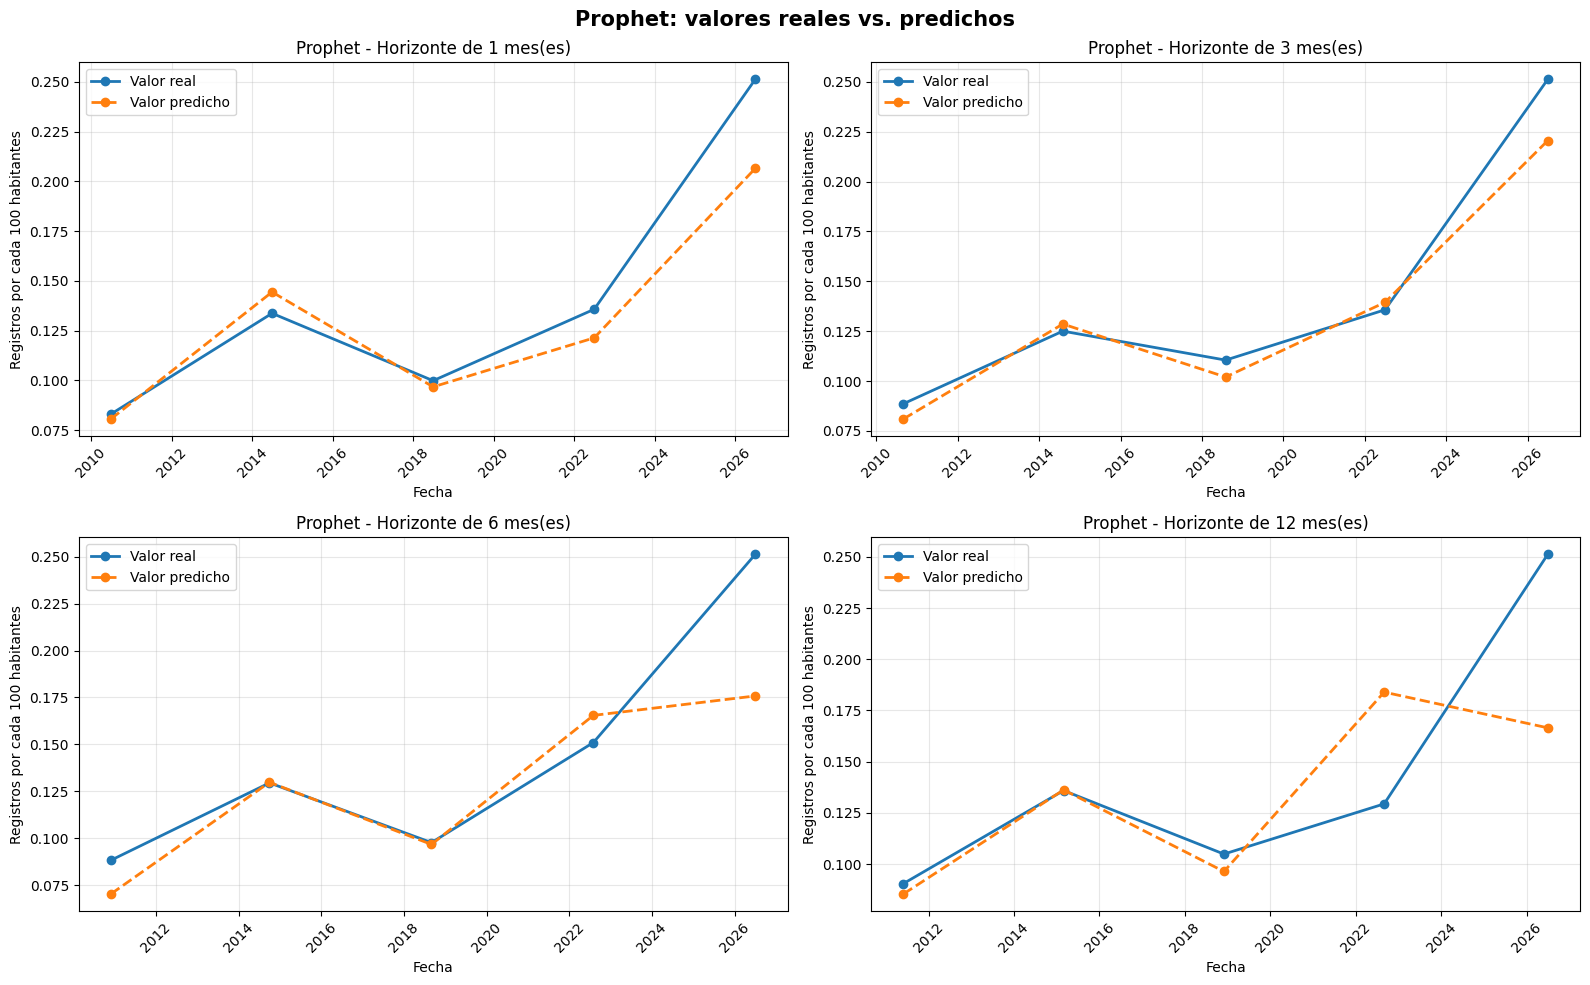

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, horizonte in zip(axes.flat, horizontes):

    datos = (
        predicciones_prophet[
            predicciones_prophet["Horizonte"] == horizonte
        ]
        .sort_values("Fecha")
    )

    ax.plot(
        datos["Fecha"],
        datos["Real"],
        marker="o",
        linewidth=2,
        label="Valor real"
    )

    ax.plot(
        datos["Fecha"],
        datos["Predicho"],
        marker="o",
        linestyle="--",
        linewidth=2,
        label="Valor predicho"
    )

    ax.set_title(
        f"Prophet - Horizonte de {horizonte} mes(es)"
    )

    ax.set_xlabel("Fecha")
    ax.set_ylabel("Registros por cada 100 habitantes")

    ax.legend()
    ax.grid(alpha=0.3)

    ax.tick_params(
        axis="x",
        rotation=45
    )

plt.suptitle(
    "Prophet: valores reales vs. predichos",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

In [ ]:
variables_mensuales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionMensual",
    "DiasHabiles",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

variables_trimestrales = [
    "PoblacionTotal",
    "PoblacionOcupada",
    "PoblacionDesocupada",
    "TasaOcupacion",
    "TasaDesocupacion",
    "PIB",
    "Var.PIB",
    "Exportaciones",
    "Importaciones",
    "TRM",
    "Var.TRM",
    "TasaInteres",
    "DTF",
    "InflacionAnual",
    "InflacionTrimestral",
    "DiasHabiles",
    "Remesas",
    "PIB_PC",
    "SMMLV",
    "ICC",
    "IEC",
    "ICE"
]

In [ ]:
# Copias de trabajo: no modificamos los DataFrames originales
datos_objetivo = objetivo[["Fecha", "Registros"]].copy()
datos_mensuales = df_datamarket_men.copy()

datos_objetivo["Fecha"] = pd.to_datetime(datos_objetivo["Fecha"])
datos_mensuales["Fecha"] = pd.to_datetime(datos_mensuales["Fecha"])

datos_objetivo["Periodo"] = datos_objetivo["Fecha"].dt.to_period("M")
datos_mensuales["Periodo"] = datos_mensuales["Fecha"].dt.to_period("M")

# Comprobar que exista una observación por mes
assert not datos_objetivo["Periodo"].duplicated().any(), (
    "La variable objetivo tiene meses duplicados."
)

assert not datos_mensuales["Periodo"].duplicated().any(), (
    "Los predictores mensuales tienen meses duplicados."
)

predictores_men = [
    col for col in variables_mensuales
    if col in datos_mensuales.columns
]

base_mensual_rf = datos_objetivo[
    ["Periodo", "Registros"]
].merge(
    datos_mensuales[["Periodo"] + predictores_men],
    on="Periodo",
    how="left",
    validate="one_to_one"
).sort_values("Periodo").reset_index(drop=True)

print("Observaciones:", len(base_mensual_rf))
print("Predictores disponibles:", predictores_men)
print("Periodo inicial:", base_mensual_rf["Periodo"].min())
print("Periodo final:", base_mensual_rf["Periodo"].max())

Observaciones: 259
Predictores disponibles: ['PoblacionTotal', 'PoblacionOcupada', 'PoblacionDesocupada', 'TasaOcupacion', 'TasaDesocupacion', 'TRM', 'Var.TRM', 'TasaInteres', 'DTF', 'InflacionAnual', 'InflacionMensual', 'DiasHabiles', 'SMMLV', 'ICC', 'IEC', 'ICE']
Periodo inicial: 2005-01
Periodo final: 2026-07


In [ ]:
datos_registros_trim = objetivo[["Fecha", "Registros"]].copy()
datos_trim = df_datamarket_trim.copy()

datos_registros_trim["Fecha"] = pd.to_datetime(
    datos_registros_trim["Fecha"]
)
datos_trim["FechaFin"] = pd.to_datetime(datos_trim["FechaFin"])

datos_registros_trim["Periodo"] = (
    datos_registros_trim["Fecha"].dt.to_period("Q")
)

datos_trim["Periodo"] = (
    datos_trim["FechaFin"].dt.to_period("Q")
)

registros_trim = (
    datos_registros_trim
    .groupby("Periodo", as_index=False)
    .agg(Registros=("Registros", "sum"))
)

assert not datos_trim["Periodo"].duplicated().any(), (
    "Los predictores trimestrales tienen trimestres duplicados."
)

predictores_trim = [
    col for col in variables_trimestrales
    if col in datos_trim.columns
]

base_trimestral_rf = registros_trim.merge(
    datos_trim[["Periodo"] + predictores_trim],
    on="Periodo",
    how="left",
    validate="one_to_one"
).sort_values("Periodo").reset_index(drop=True)

print("Observaciones:", len(base_trimestral_rf))
print("Predictores disponibles:", predictores_trim)
print("Periodo inicial:", base_trimestral_rf["Periodo"].min())
print("Periodo final:", base_trimestral_rf["Periodo"].max())

Observaciones: 87
Predictores disponibles: ['PoblacionTotal', 'PoblacionOcupada', 'PoblacionDesocupada', 'TasaOcupacion', 'TasaDesocupacion', 'PIB', 'Var.PIB', 'Exportaciones', 'Importaciones', 'TRM', 'Var.TRM', 'TasaInteres', 'DTF', 'InflacionAnual', 'InflacionTrimestral', 'DiasHabiles', 'Remesas', 'PIB_PC', 'SMMLV', 'ICC', 'IEC', 'ICE']
Periodo inicial: 2005Q1
Periodo final: 2026Q3


In [ ]:

def entrenar_random_forest(base, predictores, nombre_modelo,
                           proporcion_test=0.20):

    datos = base.copy().sort_values("Periodo").reset_index(drop=True)

    X = datos[predictores].apply(pd.to_numeric, errors="coerce")
    y = pd.to_numeric(datos["Registros"], errors="coerce")

    # Excluir observaciones sin variable objetivo
    validos = y.notna()

    X = X.loc[validos].reset_index(drop=True)
    y = y.loc[validos].reset_index(drop=True)
    periodos = datos.loc[validos, "Periodo"].reset_index(drop=True)

    # Eliminar variables que no tienen ningún dato
    X = X.dropna(axis=1, how="all")

    if len(X) < 20:
        raise ValueError(
            f"{nombre_modelo}: hay menos de 20 observaciones. "
            "Revisa el tamaño de la muestra."
        )

    if X.shape[1] == 0:
        raise ValueError("No hay variables predictoras disponibles.")

    # División cronológica: no mezclar el orden temporal
    punto_corte = int(len(X) * (1 - proporcion_test))

    X_train = X.iloc[:punto_corte]
    X_test = X.iloc[punto_corte:]

    y_train = y.iloc[:punto_corte]
    y_test = y.iloc[punto_corte:]

    # Modelo Random Forest
    modelo = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("rf", RandomForestRegressor(
            n_estimators=500,
            max_features=1.0,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])

    modelo.fit(X_train, y_train)

    predicciones = modelo.predict(X_test)

    # Métricas de desempeño
    mae = mean_absolute_error(y_test, predicciones)
    rmse = np.sqrt(mean_squared_error(y_test, predicciones))

    # MAPE: excluir valores reales iguales a cero
    mascara_mape = y_test != 0

    if mascara_mape.any():
        mape = np.mean(
            np.abs(
                (y_test[mascara_mape].to_numpy()
                 - predicciones[mascara_mape.to_numpy()])
                / y_test[mascara_mape].to_numpy()
            )
        ) * 100
    else:
        mape = np.nan

    metricas = pd.DataFrame([{
        "Modelo": nombre_modelo,
        "Observaciones entrenamiento": len(X_train),
        "Observaciones prueba": len(X_test),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }])

    # Importancia propia del Random Forest
    importancias_rf = pd.Series(
        modelo.named_steps["rf"].feature_importances_,
        index=X.columns,
        name="Importancia_RF"
    )

    # Importancia por permutación sobre el conjunto de prueba
    permutacion = permutation_importance(
        modelo,
        X_test,
        y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=20,
        random_state=42,
        n_jobs=-1
    )

    importancias_perm = pd.DataFrame({
        "Variable": X.columns,
        "Importancia_permutacion": permutacion.importances_mean,
        "Desviacion_importancia": permutacion.importances_std
    })

    importancias_perm = importancias_perm.merge(
        importancias_rf.rename_axis("Variable").reset_index(),
        on="Variable",
        how="left"
    )

    importancias_perm = importancias_perm.sort_values(
        "Importancia_permutacion",
        ascending=False
    ).reset_index(drop=True)

    # Resultados de las predicciones del conjunto de prueba
    resultados_test = pd.DataFrame({
        "Periodo": periodos.iloc[punto_corte:].reset_index(drop=True),
        "Real": y_test.reset_index(drop=True),
        "Predicho": predicciones
    })

    return modelo, metricas, importancias_perm, resultados_test


In [ ]:
modelo_mensual, metricas_mensual, importancia_mensual, test_mensual = (
    entrenar_random_forest(
        base=base_mensual_rf,
        predictores=predictores_men,
        nombre_modelo="Random Forest mensual"
    )
)

display(metricas_mensual)
display(importancia_mensual)

,Modelo,Observaciones entrenamiento,Observaciones prueba,MAE,RMSE,MAPE (%)
0,Random Forest mensual,207,52,17055.996856,22505.479152,20.464036


,Variable,Importancia_permutacion,Desviacion_importancia,Importancia_RF
0,TasaOcupacion,6.248757e+01,4.155994e+01,0.013023
1,PoblacionDesocupada,1.029990e+01,1.026180e+01,0.004515
2,Var.TRM,7.587131e+00,1.966935e+01,0.014660
3,DiasHabiles,6.755483e+00,3.649852e+01,0.016282
4,PoblacionOcupada,1.873637e-01,2.486195e-01,0.476856
5,PoblacionTotal,1.273293e-12,1.735205e-12,0.278420
6,SMMLV,1.091394e-12,1.667131e-12,0.025279
7,TasaInteres,-2.653453e-01,4.145714e-01,0.007095
8,DTF,-2.997485e-01,3.926647e-01,0.054702
9,TasaDesocupacion,-9.519432e-01,2.552867e+00,0.004918


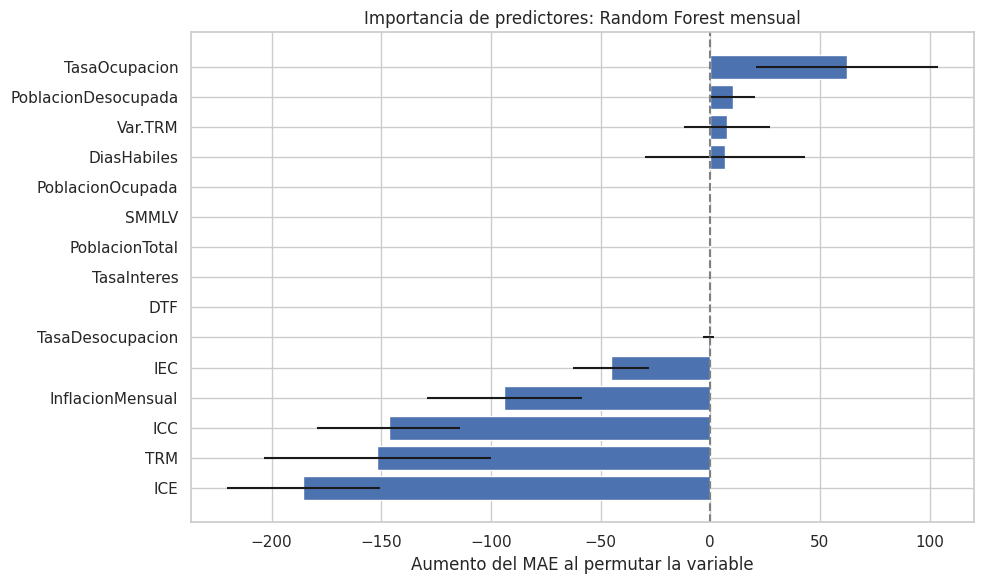

In [ ]:
top_mensual = importancia_mensual.head(15).sort_values(
    "Importancia_permutacion"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_mensual["Variable"],
    top_mensual["Importancia_permutacion"],
    xerr=top_mensual["Desviacion_importancia"]
)

plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("Aumento del MAE al permutar la variable")
plt.title("Importancia de predictores: Random Forest mensual")
plt.tight_layout()
plt.show()

In [ ]:
modelo_trimestral, metricas_trimestral, importancia_trimestral, test_trimestral = (
    entrenar_random_forest(
        base=base_trimestral_rf,
        predictores=predictores_trim,
        nombre_modelo="Random Forest trimestral"
    )
)

display(metricas_trimestral)
display(importancia_trimestral)

,Modelo,Observaciones entrenamiento,Observaciones prueba,MAE,RMSE,MAPE (%)
0,Random Forest trimestral,69,18,49281.998305,71899.784852,18.282161


,Variable,Importancia_permutacion,Desviacion_importancia,Importancia_RF
0,Importaciones,815.168115,345.928551,0.261596
1,PIB,785.516929,372.115189,0.078565
2,PIB_PC,673.193693,324.684316,0.272926
3,PoblacionTotal,595.482031,278.392752,0.067640
4,TRM,285.603918,571.318579,0.022596
5,Remesas,178.214964,107.090768,0.009536
6,IEC,175.911612,80.257725,0.012611
7,ICC,90.830108,58.920446,0.022081
8,ICE,48.107822,36.422523,0.023755
9,SMMLV,47.536694,34.620483,0.040896


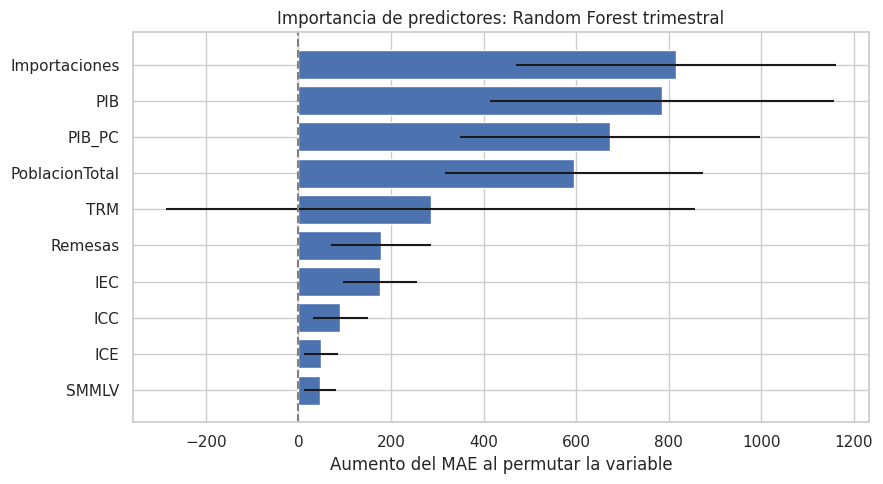

In [ ]:
top_trimestral = importancia_trimestral.sort_values(
    "Importancia_permutacion"
).tail(10)

plt.figure(figsize=(9, 5))

plt.barh(
    top_trimestral["Variable"],
    top_trimestral["Importancia_permutacion"],
    xerr=top_trimestral["Desviacion_importancia"]
)

plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("Aumento del MAE al permutar la variable")
plt.title("Importancia de predictores: Random Forest trimestral")
plt.tight_layout()
plt.show()

In [ ]:
comparacion_modelos = pd.concat(
    [metricas_mensual, metricas_trimestral],
    ignore_index=True
)

display(comparacion_modelos)

,Modelo,Observaciones entrenamiento,Observaciones prueba,MAE,RMSE,MAPE (%)
0,Random Forest mensual,207,52,17055.996856,22505.479152,20.464036
1,Random Forest trimestral,69,18,49281.998305,71899.784852,18.282161


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Copiar resultados de prueba
mensual = test_mensual.copy()
trimestral = test_trimestral.copy()

# Convertir los periodos a fechas mensuales
mensual["Periodo"] = pd.PeriodIndex(
    mensual["Periodo"], freq="M"
)

trimestral["Periodo"] = pd.PeriodIndex(
    trimestral["Periodo"], freq="Q"
)

# Agregar las predicciones mensuales por trimestre
mensual["Trimestre"] = mensual["Periodo"].dt.asfreq("Q")

mensual_trim = (
    mensual.groupby("Trimestre")
    .agg(
        Real_mensual=("Real", "sum"),
        Predicho_mensual=("Predicho", "sum"),
        Meses=("Periodo", "nunique")
    )
    .reset_index()
)

# Conservar únicamente trimestres completos de prueba
mensual_trim = mensual_trim[mensual_trim["Meses"] == 3].copy()

# Renombrar periodo trimestral del modelo trimestral
trimestral = trimestral.rename(
    columns={
        "Periodo": "Trimestre",
        "Real": "Real_trimestral",
        "Predicho": "Predicho_trimestral"
    }
)

# Unir por los mismos trimestres
comparacion = mensual_trim.merge(
    trimestral[
        ["Trimestre", "Real_trimestral", "Predicho_trimestral"]
    ],
    on="Trimestre",
    how="inner"
)

# Comprobar que ambos modelos usan la misma variable objetivo
comparacion["Diferencia_reales"] = (
    comparacion["Real_mensual"]
    - comparacion["Real_trimestral"]
)

display(comparacion)

,Trimestre,Real_mensual,Predicho_mensual,Meses,Real_trimestral,Predicho_trimestral,Diferencia_reales
0,2022Q2,203659,210806.344374,3,203659,181853.245113,0
1,2022Q3,210392,212801.064145,3,210392,182190.573030,0
2,2022Q4,178152,213351.194210,3,178152,181893.208448,0
3,2023Q1,179331,210473.893025,3,179331,180744.313125,0
4,2023Q2,163393,211805.219259,3,163393,180234.853148,0
5,2023Q3,168583,211843.379610,3,168583,179309.686863,0
6,2023Q4,169217,211010.407322,3,169217,180179.399484,0
7,2024Q1,179259,208854.381517,3,179259,181192.448998,0
8,2024Q2,192420,210186.860127,3,192420,180464.759179,0
9,2024Q3,212754,209131.941014,3,212754,180950.864932,0


In [ ]:
def calcular_metricas(y_real, y_predicho, nombre_modelo):
    y_real = np.asarray(y_real, dtype=float)
    y_predicho = np.asarray(y_predicho, dtype=float)

    mascara = y_real != 0

    mape = (
        np.mean(
            np.abs(
                (y_real[mascara] - y_predicho[mascara])
                / y_real[mascara]
            )
        ) * 100
        if mascara.any()
        else np.nan
    )

    return {
        "Modelo": nombre_modelo,
        "Trimestres evaluados": len(y_real),
        "MAE trimestral": mean_absolute_error(y_real, y_predicho),
        "RMSE trimestral": np.sqrt(
            mean_squared_error(y_real, y_predicho)
        ),
        "MAPE (%)": mape
    }


metricas_comparables = pd.DataFrame([
    calcular_metricas(
        comparacion["Real_mensual"],
        comparacion["Predicho_mensual"],
        "Random Forest mensual agregado a trimestre"
    ),
    calcular_metricas(
        comparacion["Real_trimestral"],
        comparacion["Predicho_trimestral"],
        "Random Forest trimestral"
    )
])

display(metricas_comparables.round(3))

,Modelo,Trimestres evaluados,MAE trimestral,RMSE trimestral,MAPE (%)
0,Random Forest mensual agregado a trimestre,17,47390.898,60926.019,19.441
1,Random Forest trimestral,17,51695.250,73957.162,18.990


##Evaluación